### Прогнозирование стоимости недвижимости
#### Выполняли: Билалова.И, Полуэктова.П

Цель проекта: проанализировать рынок жилой недвижимости Турции на основе
датасета Zingat и построить модель прогноза стоимости объекта в рублях.


### *Этап 1. Исследование данных (EDA)*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

C:\Users\polin\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


### Загрузка данных

In [2]:
# df = pd.read_csv('real_estate_data.csv',low_memory=False)

In [3]:
project_dir = Path(r"C:\Users\polin\Downloads")
data_path = project_dir / "df_prices_with_rates.csv"
translated_path = project_dir / "translated_model_v2.csv"
sample_path = project_dir / "test_real_estate_samples.csv"
orig = project_dir / "real_estate_data.csv"
df = pd.read_csv(data_path, low_memory=False)

In [4]:
# Оставляем поля объявлений; исторические курсы прочитаем из того же CSV ниже.
BASE_COLUMNS = [
    "id", "type", "sub_type", "start_date", "end_date", "listing_type",
    "tom", "building_age", "total_floor_count", "floor_no", "room_count",
    "size", "address", "furnished", "heating_type", "price",
    "price_currency"
]

missing_columns = sorted(set(BASE_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"В исходном файле отсутствуют столбцы: {missing_columns}")

df = df[BASE_COLUMNS].copy()

for column in ["id", "tom", "size", "price"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Загружено строк:", f"{len(df):,}")


Загружено строк: 403,487


## Перевод датасета

In [5]:
# Переводим подписи категорий, не изменяя числовые типы данных.
MAP_TYPE = {"Konut": "Жилая"}

MAP_SUB = {
    "Rezidans": "Резиденция", "Daire": "Квартира", "Villa": "Вилла",
    "Müstakil Ev": "Отдельный дом", "Yazlık": "Дача",
    "Kooperatif": "Кооператив", "Komple Bina": "Целое здание",
    "Prefabrik Ev": "Сборный дом", "Çiftlik Evi": "Фермерский дом",
    "Köşk / Konak / Yalı": "Особняк / Конак / У воды",
    "Yalı Dairesi": "Квартира у воды", "Loft": "Лофт",
}

MAP_LISTING = {"1": "Продажа", "2": "Аренда", "3": "Другое"}

MAP_FLOOR = {
    "Yüksek Giriş": "Высокий первый этаж", "Giriş Katı": "Первый этаж",
    "Bahçe katı": "Садовый этаж", "Asma Kat": "Антресоль",
    "Zemin Kat": "Цокольный этаж", "Kot 1": "Подвал 1",
    "Kot 2": "Подвал 2", "Kot 3": "Подвал 3", "Kot 4": "Подвал 4",
    "Bodrum Kat": "Подвал", "Çatı Katı": "Мансарда",
    "Teras Kat": "Этаж с террасой", "En Üst Kat": "Последний этаж",
    "Müstakil": "Отдельный", "Komple": "Целиком",
}

MAP_FLOOR_COUNT = {
    "20 ve üzeri": "20+", "10-20 arası": "10-20",
    **MAP_FLOOR,
}

MAP_HEATING = {
    "Fancoil": "Фанкойл", "Kalorifer (Doğalgaz)": "Центральное отопление (газ)",
    "Kalorifer (Kömür)": "Центральное отопление (уголь)",
    "Kombi (Doğalgaz)": "Котёл (газ)",
    "Kombi (Elektrikli)": "Котёл (электрический)",
    "Klima": "Кондиционер", "Merkezi Sistem": "Центральная система",
    "Merkezi Sistem (Isı Payı Ölçer)": "Центральная система (счётчик тепла)",
    "Soba (Kömür)": "Печь (уголь)", "Soba (Doğalgaz)": "Печь (газ)",
    "Yerden Isıtma": "Тёплый пол", "Kat Kaloriferi": "Поквартирное отопление",
    "Güneş Enerjisi": "Солнечная энергия", "Jeotermal": "Геотермальное",
}

MAP_CITY = {
    "İstanbul": "Стамбул", "Ankara": "Анкара", "İzmir": "Измир",
    "Muğla": "Мугла", "Antalya": "Анталья", "Bursa": "Бурса",
    "Adana": "Адана", "Konya": "Конья", "Gaziantep": "Газиантеп",
    "Mersin": "Мерсин", "Kayseri": "Кайсери", "Eskişehir": "Эскишехир",
    "Samsun": "Самсун", "Denizli": "Денизли", "Şanlıurfa": "Шанлыурфа",
    "Malatya": "Малатья", "Trabzon": "Трабзон", "Erzurum": "Эрзурум",
    "Balıkesir": "Балыкесир", "Manisa": "Маниса", "Aydın": "Айдын",
    "Tekirdağ": "Текирдаг", "Çanakkale": "Чанаккале",
    "Sakarya": "Сакарья", "Kocaeli": "Коджаэли", "Yalova": "Ялова",
    "Edirne": "Эдирне", "Kırklareli": "Кыркларели", "Bilecik": "Биледжик",
    "Bolu": "Болу", "Düzce": "Дюздже", "Zonguldak": "Зонгулдак",
    "Karabük": "Карабюк", "Kastamonu": "Кастамону", "Sinop": "Синоп",
    "Amasya": "Амасья", "Çorum": "Чорум", "Yozgat": "Йозгат",
    "Sivas": "Сивас", "Tokat": "Токат", "Ordu": "Орду",
    "Giresun": "Гиресун", "Rize": "Ризе", "Artvin": "Артвин",
    "Erzincan": "Эрзинджан", "Ağrı": "Агры", "Van": "Ван",
    "Diyarbakır": "Диярбакыр", "Mardin": "Мардин", "Batman": "Батман",
    "Siirt": "Сиирт", "Şırnak": "Шырнак", "Hatay": "Хатай",
    "Osmaniye": "Османие", "Kahramanmaraş": "Кахраманмараш",
    "Adıyaman": "Адыяман", "Elazığ": "Элязыг", "Tunceli": "Тунджели",
    "Bingöl": "Бингёль", "Muş": "Муш", "Bitlis": "Битлис",
    "Hakkari": "Хаккяри", "Kars": "Карс", "Ardahan": "Ардахан",
    "Iğdır": "Ыгдыр", "Nevşehir": "Невшехир", "Kırşehir": "Кыршехир",
    "Kırıkkale": "Кырыккале", "Aksaray": "Аксарай", "Niğde": "Нигде",
    "Karaman": "Караман", "Isparta": "Ыспарта", "Burdur": "Бурдур",
    "Afyonkarahisar": "Афьонкарахисар", "Kütahya": "Кютахья",
    "Uşak": "Ушак", "Çankırı": "Чанкыры", "Bartın": "Бартын",
    "Gümüşhane": "Гюмюшхане", "Bayburt": "Байбурт", "Kilis": "Килис",
    "KKTC": "ТРСК",
}

for column in ["type", "sub_type", "listing_type", "floor_no",
               "total_floor_count", "heating_type"]:
    df[column] = df[column].astype("string").str.strip()

df["type"] = df["type"].replace(MAP_TYPE)
df["sub_type"] = df["sub_type"].replace(MAP_SUB)
df["listing_type"] = df["listing_type"].replace(MAP_LISTING)
df["floor_no"] = df["floor_no"].replace(MAP_FLOOR)
df["total_floor_count"] = df["total_floor_count"].replace(MAP_FLOOR_COUNT)
df["heating_type"] = df["heating_type"].replace(MAP_HEATING)

address_parts = df["address"].astype("string").str.split("/")
df["city"] = address_parts.str[0].str.strip().replace(MAP_CITY)
df["district"] = address_parts.str[1].fillna("Неизвестно").str.strip()

# Полностью пустой столбец не несёт информации для анализа и модели.
df = df.drop(columns=["furnished"], errors="ignore")

df.to_csv(translated_path, index=False, encoding="utf-8-sig")
print("Сохранён подготовленный набор:", translated_path)
print("Размер:", df.shape)


Сохранён подготовленный набор: C:\Users\polin\Downloads\translated_model_v2.csv
Размер: (403487, 18)


In [6]:
# Рабочая копия для пересчёта всех исходных валют в единую валюту.
df_prices = df.copy()

print("Проверка переведённых категорий:")
for column in ["type", "sub_type", "listing_type"]:
    print(column, "-", df_prices[column].dropna().unique()[:5])


Проверка переведённых категорий:
type - <ArrowStringArray>
['Жилая']
Length: 1, dtype: string
sub_type - <ArrowStringArray>
['Резиденция', 'Квартира', 'Вилла', 'Отдельный дом', 'Кооператив']
Length: 5, dtype: string
listing_type - <ArrowStringArray>
['Аренда', 'Продажа', 'Другое']
Length: 3, dtype: string


### Повторная загрузка подготовленного датасета


In [7]:
# Повторная загрузка проверяет, что сохранённый CSV воспроизводимо читается.
df = pd.read_csv(translated_path, low_memory=False)

for column in ["id", "tom", "size", "price"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df_prices = df.copy()
print("Размер:", df.shape)
print("Числовые типы:")
display(df[["id", "tom", "size", "price"]].dtypes.to_frame("dtype"))


Размер: (403487, 18)
Числовые типы:


,dtype
id,int64
tom,int64
size,float64
price,float64


In [8]:
df.head()

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,heating_type,price,price_currency,city,district
0,1,Жилая,Резиденция,12/10/18,1/9/19,Аренда,30,0,20+,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,Фанкойл,3500.0,TRY,Стамбул,Kartal
1,2,Жилая,Квартира,2/13/19,NaN,Продажа,14,0,20+,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,Фанкойл,490000.0,TRY,Стамбул,Kartal
2,3,Жилая,Квартира,10/9/18,11/8/18,Продажа,30,0,1,Высокий первый этаж,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,Фанкойл,155000.0,TRY,Текирдаг,Çorlu
3,4,Жилая,Резиденция,9/10/18,10/10/18,Продажа,30,3,20+,20 ve üzeri,6+1,450.0,İstanbul/Beşiktaş/Levent,Фанкойл,32500000.0,TRY,Стамбул,Beşiktaş
4,5,Жилая,Резиденция,12/10/18,1/9/19,Продажа,30,0,20+,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,Фанкойл,1450000.0,TRY,Стамбул,Kartal


In [9]:
RATE_COLUMNS = ["USD", "GBP", "TRY", "RUB"]

# Берём исторические курсы из исходного файла и оставляем по одной строке на дату.
rates = pd.read_csv(
    data_path,
    usecols=["start_date", *RATE_COLUMNS],
    low_memory=False,
)
rates["Date"] = pd.to_datetime(
    rates["start_date"], format="%m/%d/%y", errors="raise"
)
rates = rates.drop(columns="start_date").drop_duplicates(subset="Date")
for column in RATE_COLUMNS:
    rates[column] = pd.to_numeric(rates[column], errors="coerce")
rates["EUR"] = 1.0
rates = rates.set_index("Date")[RATE_COLUMNS + ["EUR"]].sort_index()

dates = pd.to_datetime(
    df_prices["start_date"], format="%m/%d/%y", errors="raise"
)

# Для выходных и праздников берём последний опубликованный курс не старше 7 дней.
row_rates = rates.reindex(dates, method="ffill", tolerance=pd.Timedelta(days=7))
row_rates.index = df_prices.index

known_currency = df_prices["price_currency"].isin(["TRY", "EUR", "GBP", "USD"])
known_price = pd.to_numeric(df_prices["price"], errors="coerce").notna()
required_rows = known_currency & known_price

if row_rates.loc[required_rows, ["TRY", "RUB"]].isna().any().any():
    raise ValueError("Не для всех объявлений найдены исторические курсы.")

# Повторный запуск ячейки безопасен: старые валютные столбцы сначала удаляются.
df_prices = df_prices.drop(
    columns=["USD", "GBP", "TRY", "RUB", "EUR"], errors="ignore"
).join(row_rates)

print("Исторические курсы присоединены")
display(df_prices[["start_date", "price_currency", "price", "TRY", "RUB"]].head())


Исторические курсы присоединены


,start_date,price_currency,price,TRY,RUB
0,12/10/18,TRY,3500.0,6.0499,75.8985
1,2/13/19,TRY,490000.0,5.9383,74.3338
2,10/9/18,TRY,155000.0,7.0183,76.3635
3,9/10/18,TRY,32500000.0,7.4763,81.2688
4,12/10/18,TRY,1450000.0,6.0499,75.8985


In [10]:
df_prices[["start_date", "price_currency", "price", "TRY", "RUB"]].head()


,start_date,price_currency,price,TRY,RUB
0,12/10/18,TRY,3500.0,6.0499,75.8985
1,2/13/19,TRY,490000.0,5.9383,74.3338
2,10/9/18,TRY,155000.0,7.0183,76.3635
3,9/10/18,TRY,32500000.0,7.4763,81.2688
4,12/10/18,TRY,1450000.0,6.0499,75.8985


In [11]:
# price_try нужен как прозрачный промежуточный расчёт перед переводом в рубли.
df_prices["price"] = pd.to_numeric(df_prices["price"], errors="coerce")
df_prices["price_try"] = np.nan

for currency in ["TRY", "EUR", "GBP", "USD"]:
    mask = df_prices["price_currency"].eq(currency)
    rate_to_try = row_rates.loc[mask, "TRY"] / row_rates.loc[mask, currency]
    df_prices.loc[mask, "price_try"] = (
        df_prices.loc[mask, "price"] * rate_to_try
    )


In [12]:
# Количество рублей за одну турецкую лиру на дату публикации объявления.
rub_per_try = row_rates["RUB"] / row_rates["TRY"]
df_prices["price_rub"] = df_prices["price_try"] * rub_per_try

display(
    df_prices[
        ["start_date", "price_currency", "price", "price_try", "price_rub"]
    ]
    .head(10)
    .style.format(precision=2, thousands=" ", decimal=",", na_rep="—")
)


,start_date,price_currency,price,price_try,price_rub
0,12/10/18,TRY,"3 500,00","3 500,00","43 908,95"
1,2/13/19,TRY,"490 000,00","490 000,00","6 133 668,22"
2,10/9/18,TRY,"155 000,00","155 000,00","1 686 497,09"
3,9/10/18,TRY,"32 500 000,00","32 500 000,00","353 281 168,49"
4,12/10/18,TRY,"1 450 000,00","1 450 000,00","18 190 850,26"
5,11/9/18,TRY,"780 000,00","780 000,00","9 574 866,13"
6,1/4/19,TRY,"3 750,00","3 750,00","47 206,35"
7,10/3/18,TRY,"1 500 000,00","1 500 000,00","16 225 384,68"
8,2/16/19,TRY,"1 500 000,00","1 500 000,00","18 984 929,71"
9,12/26/18,GBP,"84 256,00","565 961,36","7 308 088,34"


In [13]:
df_prices.head()


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,...,price_currency,city,district,USD,GBP,TRY,RUB,EUR,price_try,price_rub
0,1,Жилая,Резиденция,12/10/18,1/9/19,Аренда,30,0,20+,2,...,TRY,Стамбул,Kartal,1.1425,0.90245,6.0499,75.8985,1.0,3500.0,4.390895e+04
1,2,Жилая,Квартира,2/13/19,NaN,Продажа,14,0,20+,20 ve üzeri,...,TRY,Стамбул,Kartal,1.1305,0.87553,5.9383,74.3338,1.0,490000.0,6.133668e+06
2,3,Жилая,Квартира,10/9/18,11/8/18,Продажа,30,0,1,Высокий первый этаж,...,TRY,Текирдаг,Çorlu,1.1435,0.87680,7.0183,76.3635,1.0,155000.0,1.686497e+06
3,4,Жилая,Резиденция,9/10/18,10/10/18,Продажа,30,3,20+,20 ve üzeri,...,TRY,Стамбул,Beşiktaş,1.1571,0.89340,7.4763,81.2688,1.0,32500000.0,3.532812e+08
4,5,Жилая,Резиденция,12/10/18,1/9/19,Продажа,30,0,20+,2,...,TRY,Стамбул,Kartal,1.1425,0.90245,6.0499,75.8985,1.0,1450000.0,1.819085e+07


Для сопоставления цен разных исходных валют создана таблица `df_prices`.

- `price_try` — промежуточная цена в турецких лирах;
- `price_rub` — итоговая цена в рублях и целевая переменная модели.

Пересчёт выполняется по историческим курсам на дату начала объявления
`start_date`. Если на конкретную дату курса нет, используется последний
предыдущий опубликованный курс не старше семи дней. Исходные `price` и
`price_currency` сохраняются для контроля, а отсутствующие цены не заполняются.


#### Описание данных

**Источник:** Zingat — данные объявлений о жилой недвижимости.

Основные признаки:
* **id** — идентификатор объявления
* **type** — тип недвижимости
* **sub_type** — подтип объекта
* **start_date / end_date** — даты активности объявления
* **listing_type** — тип объявления
* **tom** — время нахождения на рынке
* **building_age** — возраст здания
* **total_floor_count** — количество этажей
* **floor_no** — этаж
* **room_count** — количество комнат
* **size** — площадь, м²
* **address** — адрес
* **furnished** — меблированность
* **heating_type** — тип отопления
* **price** — цена
* **price_currency** — валюта цены

**Основная целевая переменная после пересчета:** `price_try`.

In [14]:
print("Последние 5 строк датасета:")
display(df.tail())

Последние 5 строк датасета:


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,heating_type,price,price_currency,city,district
403482,403483,Жилая,Квартира,9/18/18,NaN,Аренда,162,NaN,NaN,NaN,+,NaN,İstanbul/Sultanbeyli/Adil,NaN,1500.0,TRY,Стамбул,Sultanbeyli
403483,403484,Жилая,Квартира,10/11/18,NaN,Продажа,139,NaN,NaN,NaN,2+1,NaN,Sakarya/Adapazarı/Cumhuriyet,NaN,120000.0,TRY,Сакарья,Adapazarı
403484,403485,Жилая,Квартира,11/22/18,NaN,Продажа,97,NaN,NaN,NaN,1+1,NaN,Antalya/Alanya/Saray,NaN,48000.0,EUR,Анталья,Alanya
403485,403486,Жилая,Квартира,2/21/19,NaN,Аренда,6,NaN,NaN,NaN,2+1,2.0,Aydın/Kuşadası/Türkmen,NaN,900.0,TRY,Айдын,Kuşadası
403486,403487,Жилая,Квартира,1/15/19,1/18/19,Продажа,3,NaN,NaN,NaN,3+1,140.0,Kayseri/Melikgazi/Alpaslan,NaN,210000.0,TRY,Кайсери,Melikgazi


In [15]:
print("\nСлучайная строка:")
display(df.sample(1, random_state=42))


Случайная строка:


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,heating_type,price,price_currency,city,district
60623,60624,Жилая,Квартира,11/20/18,2/23/19,Продажа,95,6-10 arası,5,1,2+1,120.0,Antalya/Alanya/Oba,Кондиционер,240000.0,TRY,Анталья,Alanya


In [16]:
# Сравниваем типы объявлений уже после пересчёта всех валют в RUB.
type_summary = (
    df_prices.loc[df_prices["price_rub"].gt(0)]
    .groupby("listing_type")["price_rub"]
    .agg(["count", "median"])
    .rename(columns={
        "count": "Количество объявлений",
        "median": "Медианная цена, RUB",
    })
)
display(type_summary)


,Количество объявлений,"Медианная цена, RUB"
listing_type,,
Аренда,114101,1.413226e+04
Другое,2234,8.655565e+02
Продажа,286392,3.196923e+06


После пересчёта всех исходных валют медианная стоимость заметно различается
между продажей, арендой и прочими объявлениями. Поэтому `listing_type`
сохраняется как категориальный признак и дополнительно используется при
раздельной оценке качества модели.


## Разведочный анализ данных (РАД, EDA)

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 18 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  str    
 2   sub_type           403487 non-null  str    
 3   start_date         403487 non-null  str    
 4   end_date           266298 non-null  str    
 5   listing_type       403487 non-null  str    
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  str    
 8   total_floor_count  375466 non-null  str    
 9   floor_no           368191 non-null  str    
 10  room_count         403487 non-null  str    
 11  size               257481 non-null  float64
 12  address            403487 non-null  str    
 13  heating_type       375517 non-null  str    
 14  price              402772 non-null  float64
 15  price_currency     402772 non-null  str    
 16  city         

Датасет содержит 403 487 объявлений о жилой недвижимости. Для каждого объекта
доступны местоположение, характеристики здания и помещения, даты размещения,
тип объявления и исходная цена. После подготовки добавляются город, район и
цена в рублях.


Категориальные признаки: тип и подтип недвижимости, тип объявления, адрес,
город, район, отопление, этаж, возраст и этажность здания, планировка и валюта.

Числовые признаки: идентификатор, время на рынке, площадь и исходная цена.
Производные числовые признаки планировки и даты будут созданы на этапе
Feature Engineering.


##### Размер датасета

In [18]:
print(f'Количество строк: {df.shape[0]:,}')
print(f'Количество столбцов: {df.shape[1]}')

Количество строк: 403,487
Количество столбцов: 18


In [19]:
# Исходную price не объединяем в одну статистику: она записана в разных валютах.
df[["id", "tom", "size"]].describe()


,id,tom,size
count,403487.00000,403487.000000,257481.000000
mean,201744.00000,57.022739,279.349094
std,116476.80837,44.358933,9429.195331
min,1.00000,0.000000,1.000000
25%,100872.50000,29.000000,85.000000
50%,201744.00000,40.000000,110.000000
75%,302615.50000,90.000000,140.000000
max,403487.00000,180.000000,948235.000000


- `tom` изменяется от 0 до 180 дней; среднее выше медианы, поэтому распределение
  имеет правый хвост.
- У `size` выражена правосторонняя асимметрия, а максимальные значения требуют
  отдельной проверки.
- Исходный `price` не интерпретируется общей статистикой, поскольку содержит
  разные валюты. Анализ целевой цены выполняется ниже по `price_rub`.
- Полностью пустой `furnished` удалён при подготовке данных.


#### Выбор целевой переменной

In [20]:
target = "price_rub"
print("Целевая переменная:", target)
print("\nИсходные валюты:")
print(df["price_currency"].value_counts(dropna=False))


Целевая переменная: price_rub

Исходные валюты:
price_currency
TRY    400677
EUR       922
NaN       715
GBP       621
USD       552
Name: count, dtype: int64


Цены представлены в нескольких валютах, поэтому для анализа и моделирования
используется `price_rub`. Пересчёт по историческому курсу позволяет сравнивать
объявления в единой валюте. Ценовые графики строятся отдельно по типам
объявлений и включают только положительные значения.


### 1.2 Описательная статистика

In [21]:
selected_listing_type = "Продажа"

analysis_df = df_prices.loc[
    (df_prices["listing_type"] == selected_listing_type)
    & (df_prices[target] > 0)
].copy()

print("analysis_df:", analysis_df.shape)   

analysis_df: (286392, 25)


In [22]:
numeric_cols = ['tom', 'size']
stats = df[numeric_cols].describe().T
stats['median'] = df[numeric_cols].median()
stats['skewness'] = df[numeric_cols].skew()
stats = stats[['count','min','25%','median','mean','75%','max','std','skewness']]
display(stats)


,count,min,25%,median,mean,75%,max,std,skewness
tom,403487.0,0.0,29.0,40.0,57.022739,90.0,180.0,44.358933,0.836624
size,257481.0,1.0,85.0,110.0,279.349094,140.0,948235.0,9429.195331,77.653355


**Интерпретация.** Наблюдаемая длительность размещения объявления tom составляет от 0 до 180 дней. Среднее значение равно 57,02 дня, медиана - 40 дней. Среднее значение само по себе не позволяет определить, сколько объявлений находится в конкретном диапазоне длительности.

Площадь size имеет выраженную правостороннюю асимметрию: среднее значение составляет 279,35 кв м, медиана - 110 кв м. Максимальная площадь 948 235 кв м требует проверки с учётом подтипа объекта. Большая величина сама по себе не является достаточным основанием для удаления записи.

In [23]:
numeric_cols = ['tom', 'size', target]

stats = analysis_df[numeric_cols].describe().T
stats['median'] = analysis_df[numeric_cols].median()
stats['skewness'] = analysis_df[numeric_cols].skew()

stats = stats[
    ['count', 'min', '25%', 'median',
     'mean', '75%', 'max', 'std', 'skewness']
]

display(stats.round(2))

,count,min,25%,median,mean,75%,max,std,skewness
tom,286392.0,0.0,30.00,51.00,60.61,91.00,1.800000e+02,44.99,0.73
size,184690.0,1.0,90.00,115.00,341.38,145.00,9.482350e+05,11092.59,66.23
price_rub,286392.0,10.7,2189590.67,3196923.18,6031481.56,4973181.47,2.155597e+10,60484047.31,280.44


Таблица показывает статистики продажи для времени размещения, площади и цены
в рублях. Строки с отсутствующей, нулевой или отрицательной целевой ценой в
расчёт не включаются.


In [24]:
# Все типы объявлений.
# Цены уже пересчитаны в рубли.
price_groups = (
    df_prices.loc[df_prices[target] > 0]
    .groupby("listing_type")[target]
)

# Описательная статистика отдельно для каждого типа.
price_stats = price_groups.describe()
price_stats = price_stats.rename(columns={"50%": "median"})
price_stats["skewness"] = price_groups.skew()

price_stats = price_stats[
    ["count", "min", "25%", "median",
     "mean", "75%", "max", "std", "skewness"]
]

display(
    price_stats.style.format(
        precision=2,
        thousands=" ",
        decimal=","
    )
)

,count,min,25%,median,mean,75%,max,std,skewness
listing_type,,,,,,,,,
Аренда,"114 101,00","37,10","10 127,43","14 132,26","212 031,00","20 513,33","12 656 608 412,82","42 167 580,93","269,42"
Другое,"2 234,00","225,66","647,61","865,56","1 493,36","1 073,16","98 203,76","4 778,07","13,23"
Продажа,"286 392,00","10,70","2 189 590,67","3 196 923,18","6 031 481,56","4 973 181,47","21 555 973 266,50","60 484 047,31","280,44"


In [25]:
# Статистика по категориальным признакам
cat_cols = df.select_dtypes(include=['object']).columns
print("Статистика по категориальным признакам:\n")
for col in cat_cols:
    print(f"{col} (Уникальных значений: {df[col].nunique()})")
    print(df[col].value_counts().head(5))
    print(" " * 40)

C:\Users\polin\AppData\Local\Temp\ipykernel_26064\3539844428.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


Статистика по категориальным признакам:

type (Уникальных значений: 1)
type
Жилая    403487
Name: count, dtype: int64
                                        
sub_type (Уникальных значений: 12)
sub_type
Квартира         354549
Вилла             21324
Отдельный дом      9563
Резиденция         7716
Дача               5929
Name: count, dtype: int64
                                        
start_date (Уникальных значений: 181)
start_date
10/11/18    4064
9/26/18     3892
10/17/18    3846
10/5/18     3832
10/2/18     3630
Name: count, dtype: int64
                                        
end_date (Уникальных значений: 181)
end_date
12/19/18    3048
1/18/19     2866
2/20/19     2831
2/9/19      2785
2/1/19      2747
Name: count, dtype: int64
                                        
listing_type (Уникальных значений: 3)
listing_type
Продажа    287009
Аренда     114236
Другое       2242
Name: count, dtype: int64
                                        
building_age (Уникальных значений: 14)
b

In [26]:
print(
    "Количество уникальных типов объявлений:",
    df["listing_type"].nunique()
)

display(
    df["listing_type"]
    .value_counts(dropna=False)
    .sort_index()
    .rename("Количество объявлений")
)

Количество уникальных типов объявлений: 3


listing_type
Аренда     114236
Другое       2242
Продажа    287009
Name: Количество объявлений, dtype: int64

### Визуальный анализ

In [27]:
# Для ценовых графиков используем положительную стоимость в рублях.
viz_df = df_prices.loc[df_prices[target].gt(0)].copy()

# Город извлекается из первой части адреса и переводится единообразно.
viz_df["city"] = (
    viz_df["address"].astype("string").str.split("/").str[0].str.strip()
    .replace(MAP_CITY)
)


#### Распределение цены

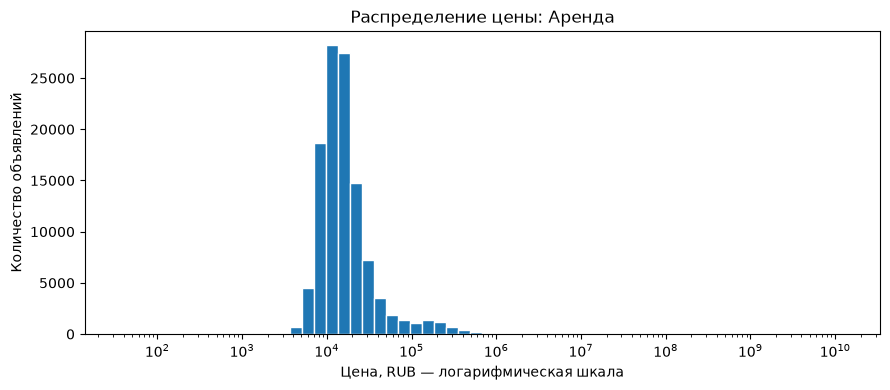

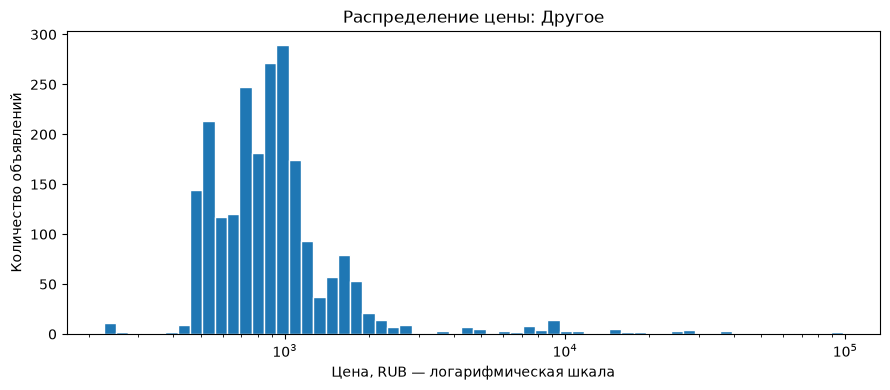

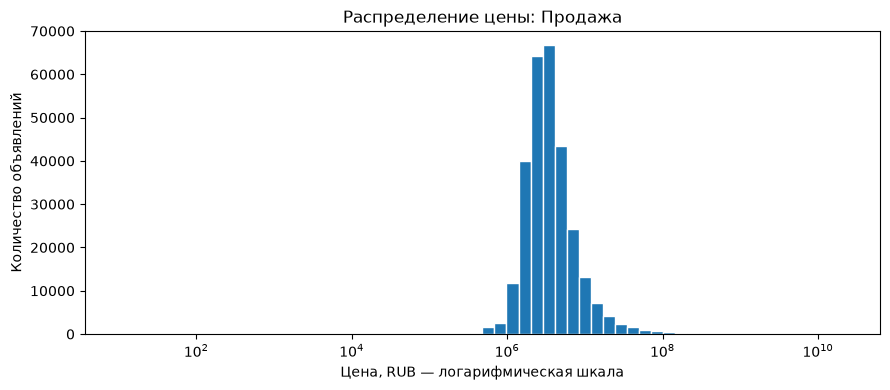

In [28]:
for listing_type, group in viz_df.groupby("listing_type"):
    prices = group[target]
    bins = np.geomspace(prices.min(), prices.max(), 61)

    plt.figure(figsize=(9, 4))
    plt.hist(prices, bins=bins, edgecolor="white")
    plt.xscale("log")
    plt.xlabel("Цена, RUB — логарифмическая шкала")
    plt.ylabel("Количество объявлений")
    plt.title(f"Распределение цены: {listing_type}")
    plt.tight_layout()
    plt.show()


Для всех трёх типов объявлений - аренда, продажа и другое - распределение цен сильно смещено вправо.

- Основная масса объектов находится в относительно узком диапазоне цен.
- При этом присутствуют отдельные объекты с очень высокой стоимостью, поэтому распределение имеет длинный правый хвост.
- Для аренды основная концентрация находится примерно около сотен–тысяч рублей по отображаемой шкале, а для продажи — около миллионов рублей.
- Поэтому средняя цена может заметно отличаться от медианной из-за дорогих объектов.

Продажа — самая массовая и дорогая группа; аренда дешевле, а категория «Другое» малочисленна и требует осторожной интерпретации.


#### Распределение площади

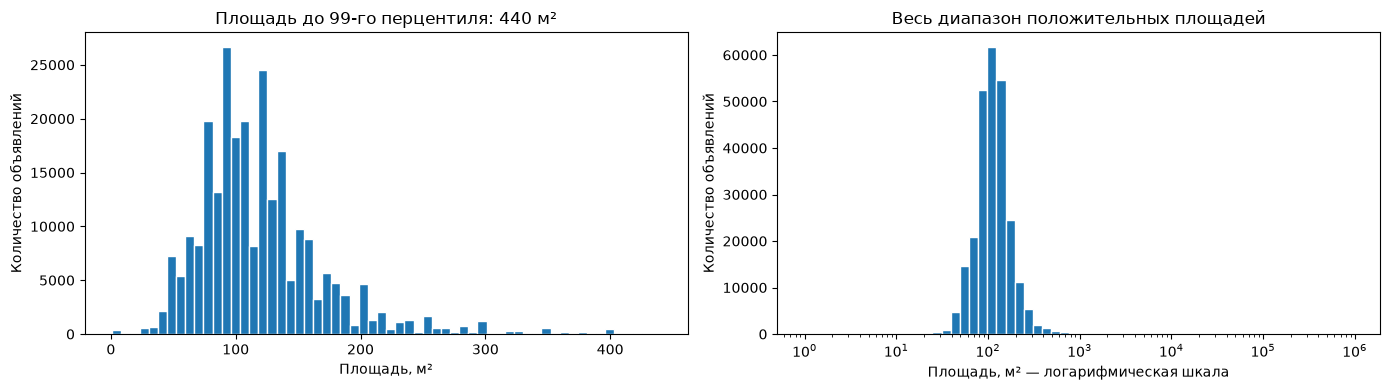

На левом графике не показаны значения выше порога: 2559


In [29]:
# Для площади берём весь набор, включая объявления без цены.
areas = df_prices["size"].dropna()
areas = areas[areas > 0]

limit = areas.quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Основная часть распределения.
# Большие площади не заменяются порогом.
axes[0].hist(
    areas[areas <= limit],
    bins=60,
    edgecolor="white"
)
axes[0].set_title(f"Площадь до 99-го перцентиля: {limit:,.0f} м²")
axes[0].set_xlabel("Площадь, м²")
axes[0].set_ylabel("Количество объявлений")

# Весь диапазон положительных площадей.
bins = np.geomspace(areas.min(), areas.max(), 61)

axes[1].hist(areas, bins=bins, edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Весь диапазон положительных площадей")
axes[1].set_xlabel("Площадь, м² — логарифмическая шкала")
axes[1].set_ylabel("Количество объявлений")

plt.tight_layout()
plt.show()

print(
    "На левом графике не показаны значения выше порога:",
    int((areas > limit).sum())
)

- Слева показана основная часть данных, справа - весь диапазон.
- Большинство объектов имеют площадь примерно до 150–200 м², а основная концентрация находится примерно в районе 50–150 м².

#### Количество комнат

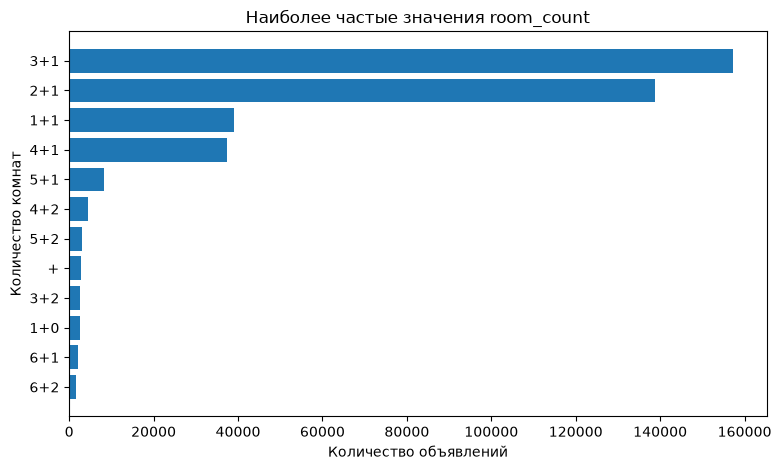

In [30]:
room_counts = df['room_count'].value_counts().head(12).sort_values()

plt.figure(figsize=(9,5))
plt.barh(room_counts.index.astype(str), room_counts.values)
plt.xlabel('Количество объявлений')
plt.ylabel('Количество комнат')
plt.title('Наиболее частые значения room_count')
plt.show()

**Вывод:** наиболее массовые типы квартир представлены несколькими повторяющимися форматами комнат.

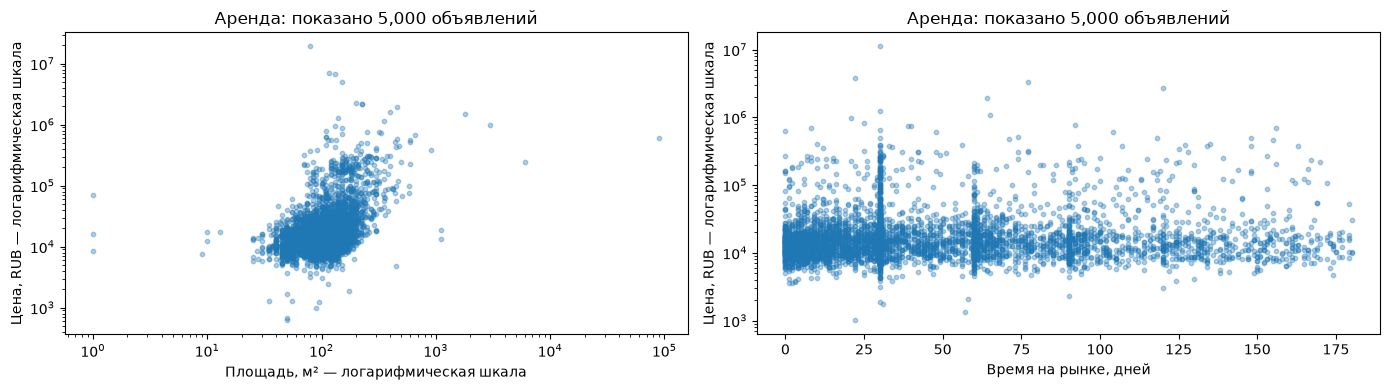

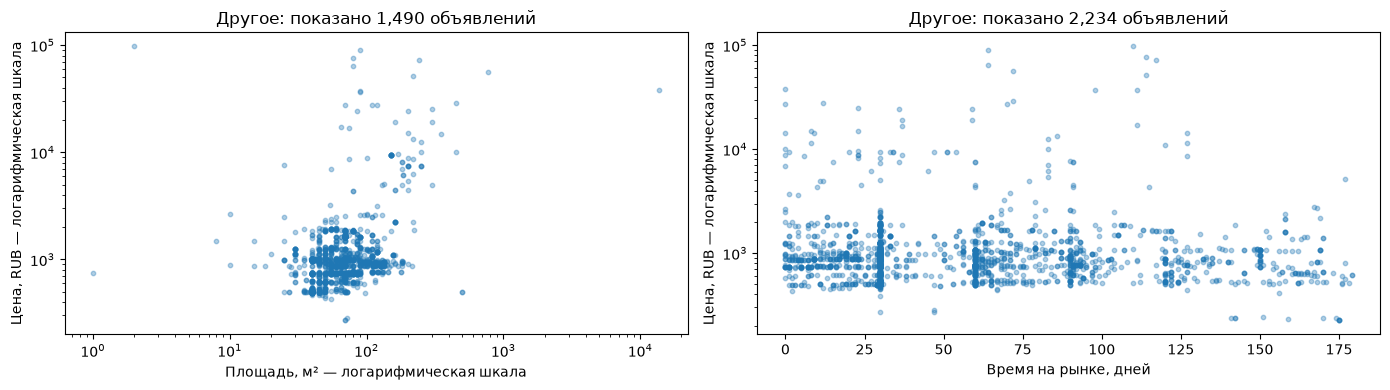

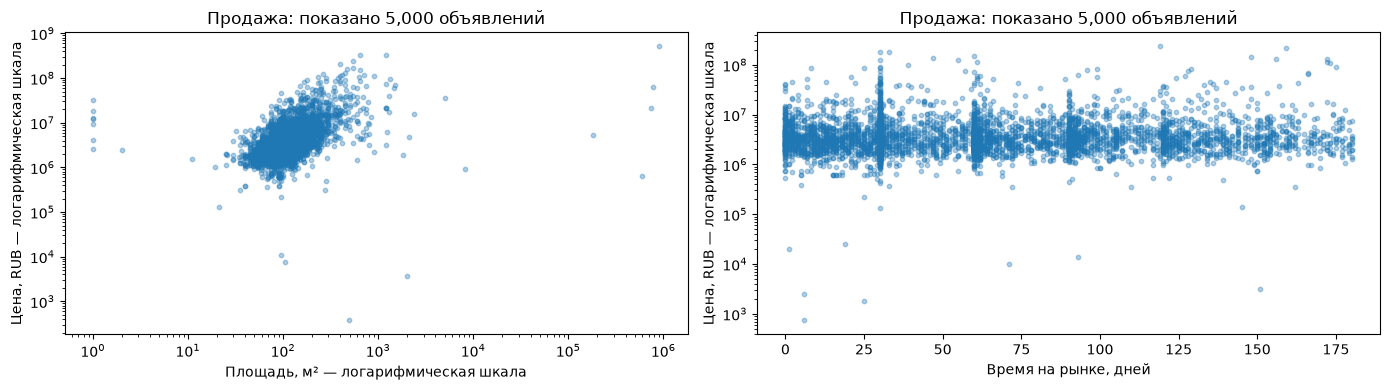

In [31]:
for listing_type, group in viz_df.groupby("listing_type"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    settings = [
        ("size", "Площадь, м² — логарифмическая шкала"),
        ("tom", "Время на рынке, дней"),
    ]

    for ax, (feature, label) in zip(axes, settings):
        points = group[[feature, target]].dropna()
        if feature == "size":
            points = points.loc[points["size"].gt(0)]

        points = points.sample(n=min(5000, len(points)), random_state=42)
        ax.scatter(points[feature], points[target], s=10, alpha=0.35)
        ax.set_yscale("log")
        if feature == "size":
            ax.set_xscale("log")

        ax.set_xlabel(label)
        ax.set_ylabel("Цена, RUB — логарифмическая шкала")
        ax.set_title(f"{listing_type}: показано {len(points):,} объявлений")

    plt.tight_layout()
    plt.show()


На точечных графиках видно достаточно выраженное облако точек: при увеличении площади цена в целом также увеличивается.

Особенно хорошо эта зависимость заметна для объявлений «Продажа».

При этом точки сильно разбросаны, то есть объекты одинаковой площади могут иметь существенно разные цены.

#### Boxplot цены по крупнейшим подтипам недвижимости

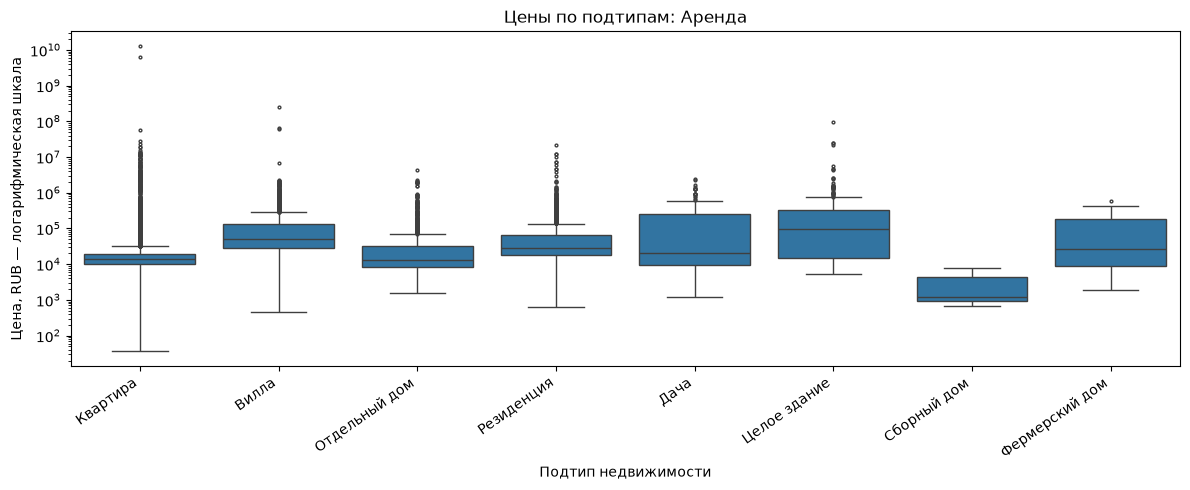

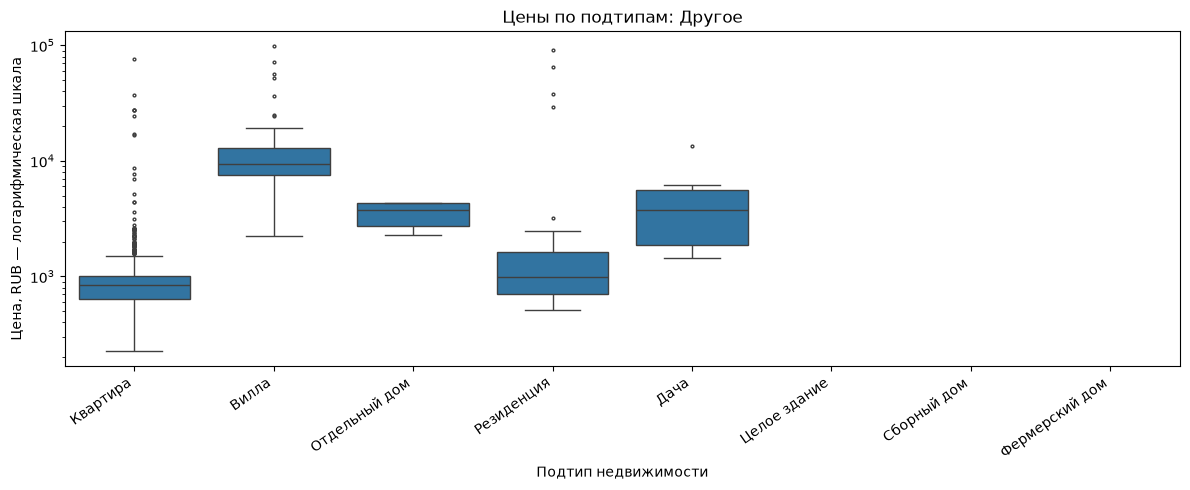

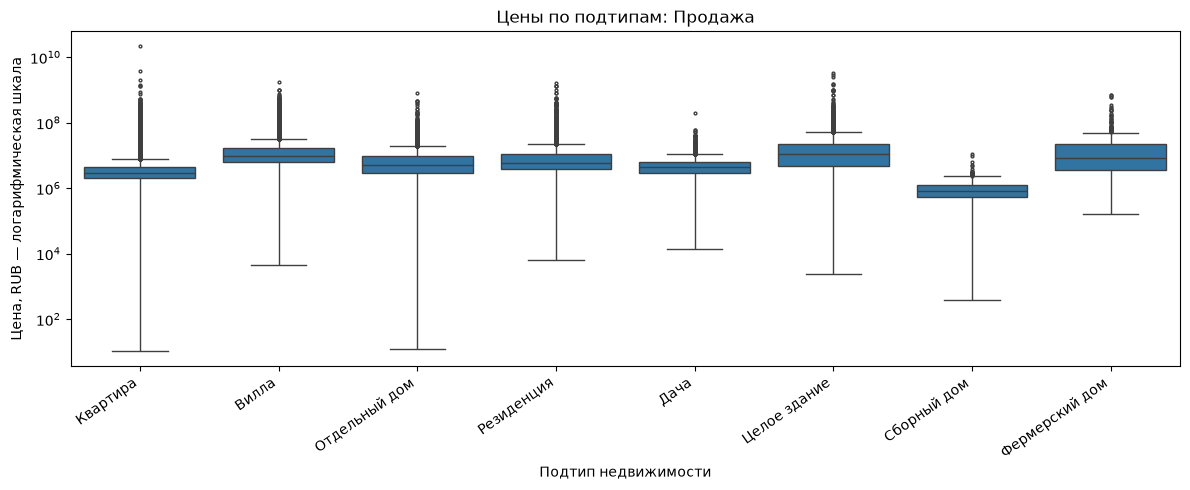

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# Одинаковый набор подтипов для сравнения между группами.
top_subtypes = (
    viz_df["sub_type"]
    .value_counts()
    .head(8)
    .index
)

for listing_type, group in viz_df.groupby("listing_type"):
    box_data = group.loc[
        group["sub_type"].isin(top_subtypes)
    ]

    plt.figure(figsize=(12, 5))

    sns.boxplot(
        data=box_data,
        x="sub_type",
        y=target,
        order=top_subtypes,
        showfliers=True,
        fliersize=2
    )

    plt.yscale("log")
    plt.xticks(rotation=35, ha="right")
    plt.xlabel("Подтип недвижимости")
    plt.ylabel("Цена, RUB — логарифмическая шкала")
    plt.title(f"Цены по подтипам: {listing_type}")

    plt.tight_layout()
    plt.show()

Тип объявления и подтип недвижимости заметно связаны с уровнем цены. Выбросы
есть во всех группах, поэтому далее используются устойчивое масштабирование и
логарифмическое преобразование.


Boxplot показывает заметное различие цен между подтипами недвижимости.

Например, виллы и целые здания имеют более высокие уровни цен, тогда как съёмные/более компактные типы жилья находятся ниже.

Также практически для всех подтипов присутствует большое количество выбросов.

Вывод: тип недвижимости существенно связан с уровнем цены. Поэтому категориальный признак подтипа недвижимости имеет смысл учитывать при построении модели прогнозирования.

Boxplot рассчитывается по исходным пересчитанным значениям, выбросы показываются.

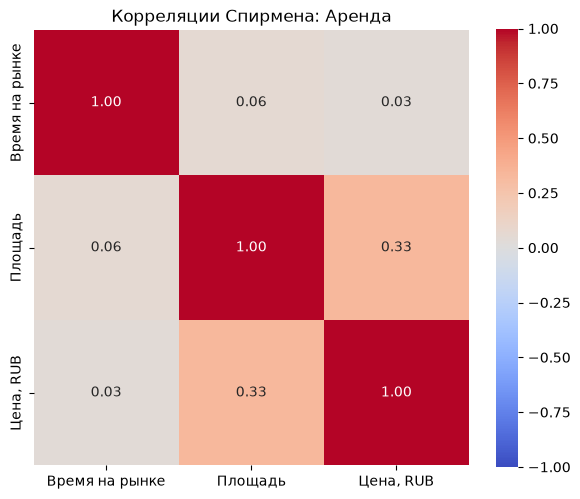

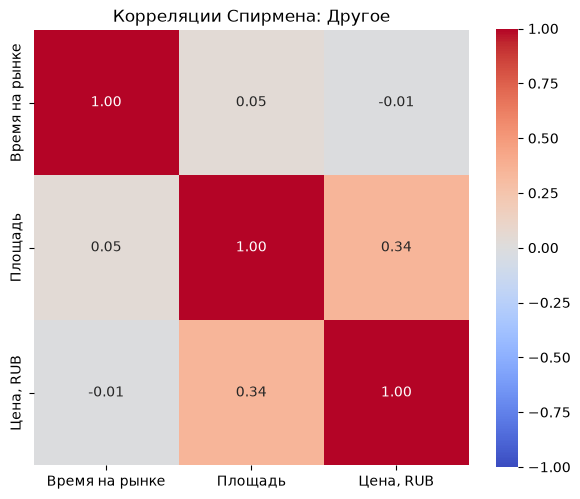

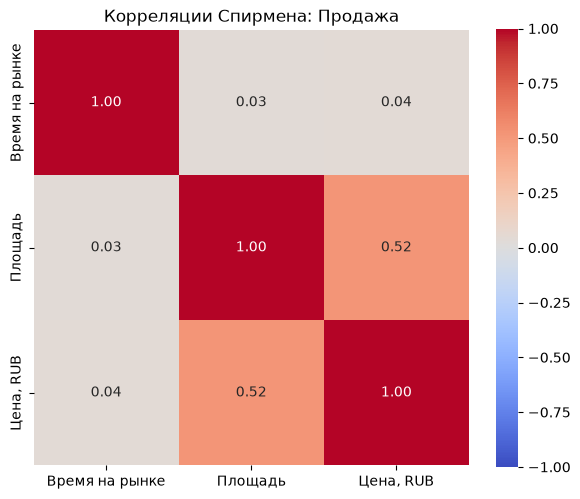

In [33]:
column_labels = {
    "tom": "Время на рынке",
    "size": "Площадь",
    target: "Цена, RUB",
}

for listing_type, group in viz_df.groupby("listing_type"):
    corr = (
        group[["tom", "size", target]]
        .rename(columns=column_labels)
        .corr(method="spearman")
    )

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        corr, annot=True, cmap="coolwarm", fmt=".2f",
        vmin=-1, vmax=1, center=0, square=True,
    )
    plt.title(f"Корреляции Спирмена: {listing_type}")
    plt.tight_layout()
    plt.show()


Вывод: площадь является одним из наиболее заметных числовых факторов, связанных с ценой, особенно для продаж. Время нахождения объявления на рынке в данном датасете практически не связано с ценой.

Здесь используются содержательные числовые характеристики и пересчитанная цена. Выбран коэффициент Спирмена: он оценивает монотонную связь и менее чувствителен к величине экстремальных значений. Корреляция показывает связь, но сама по себе не доказывает влияние одного признака на другой.

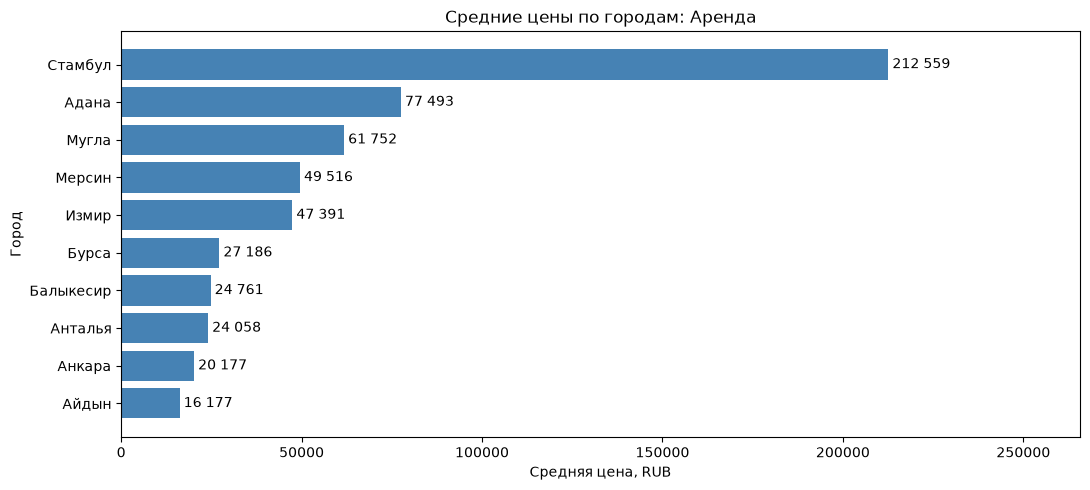

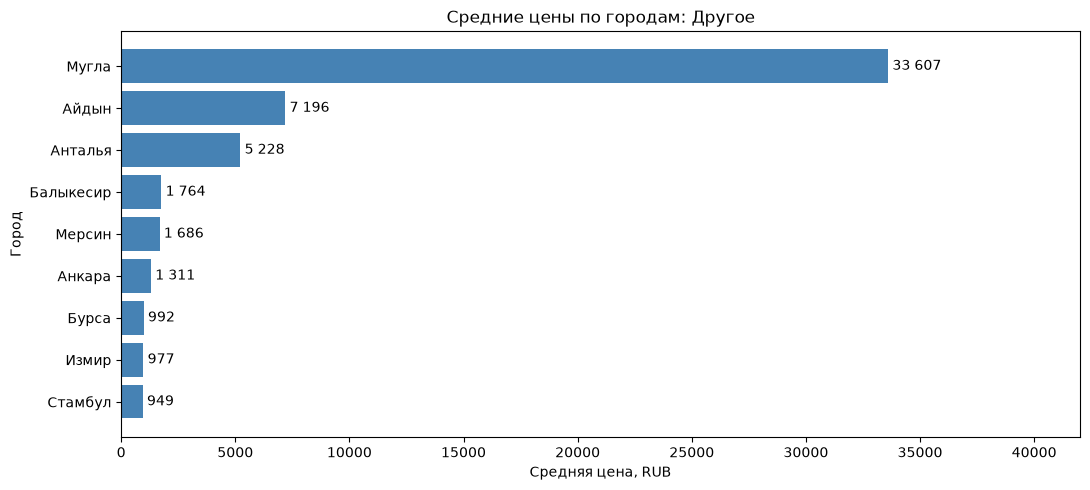

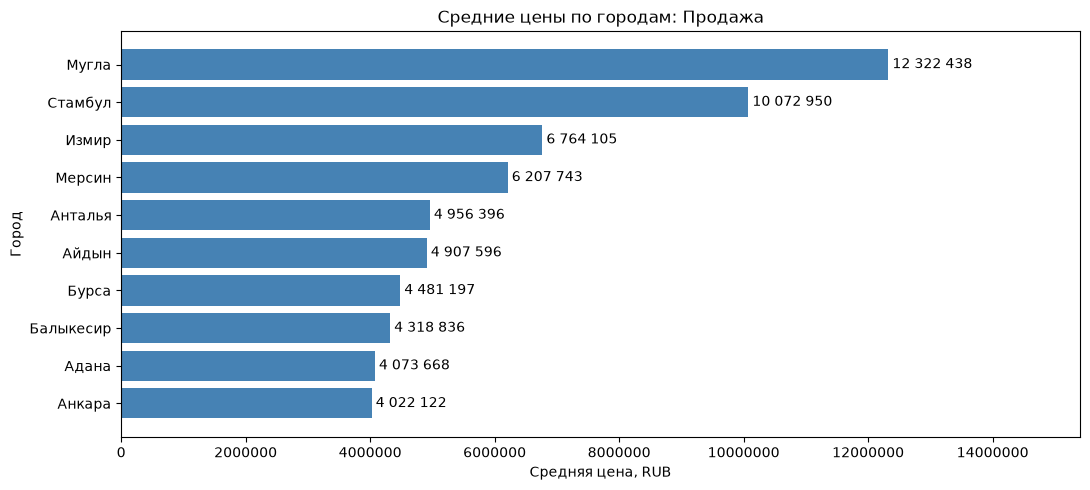

In [34]:
# Выбираем одни и те же города для всех типов объявлений.
top_cities = (
    viz_df["city"]
    .value_counts()
    .head(10)
    .index
)

for listing_type, group in viz_df.groupby("listing_type"):
    city_price = (
        group.loc[group["city"].isin(top_cities)]
        .groupby("city")[target]
        .mean()
        .sort_values()
    )

    if city_price.empty:
        continue

    fig, ax = plt.subplots(figsize=(11, 5))

    bars = ax.barh(
        city_price.index,
        city_price.values,
        color="steelblue"
    )

    # Подписываем значения, чтобы их было удобно читать.
    ax.bar_label(
        bars,
        labels=[
            f"{value:,.0f}".replace(",", " ")
            for value in city_price.values
        ],
        padding=3
    )

    ax.margins(x=0.25)
    ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    ax.set_xlabel("Средняя цена, RUB")
    ax.set_ylabel("Город")
    ax.set_title(f"Средние цены по городам: {listing_type}")

    plt.tight_layout()
    plt.show()

Вывод: местоположение объекта является очень важным фактором стоимости. Средняя цена существенно различается между городами, причём характер различий зависит от типа объявления.

### 1.4 Анализ пропусков и аномалий

In [35]:
df.isna().sum()

id                        0
type                      0
sub_type                  0
start_date                0
end_date             137189
listing_type              0
tom                       0
building_age          27390
total_floor_count     28021
floor_no              35296
room_count                0
size                 146006
address                   0
heating_type          27970
price                   715
price_currency          715
city                      0
district                  0
dtype: int64

In [36]:
missing_table = pd.DataFrame({
    "Количество пропусков": df.isna().sum(),
    "Доля пропусков, %": (df.isna().mean() * 100).round(2)
}).sort_values("Количество пропусков", ascending=False)

display(missing_table)

,Количество пропусков,"Доля пропусков, %"
size,146006,36.19
end_date,137189,34.00
floor_no,35296,8.75
total_floor_count,28021,6.94
heating_type,27970,6.93
building_age,27390,6.79
price,715,0.18
price_currency,715,0.18
type,0,0.00
id,0,0.00


Таблица содержит количество и долю пропусков по каждому актуальному столбцу.
Наибольшая доля отсутствующих значений наблюдается у площади и даты завершения
объявления; также пропуски есть в этажности, этаже, отоплении и возрасте здания.
`furnished` был удалён раньше как полностью пустой признак.


Вывод: пропуски особенно важны для признаков площади, возраста здания, этажности и отопления. Столбец **furnished** не содержит полезной информации, если он полностью пуст.

### Проверка дубликатов

In [37]:
print('Количество полных дубликатов:', df.duplicated().sum())

Количество полных дубликатов: 0


In [38]:
comparison_cols = [
    col for col in df.columns
    if col != "id"
]

print(
    "Повторных строк без учёта id:",
    df.duplicated(subset=comparison_cols).sum()
)

Повторных строк без учёта id: 11559


Полных дубликатов с учётом всех столбцов не обнаружено. Однако без учёта уникального id найдено 11 559 повторных строк. Эти совпадения требуют дополнительной проверки перед решением об удалении.

### Проверка логических аномалий

In [39]:
def floor_count_for_check(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value.endswith("+"):
        return float(value[:-1])
    if "-" in value:
        left, right = value.split("-", maxsplit=1)
        if left.replace(".", "", 1).isdigit() and right.replace(".", "", 1).isdigit():
            return float(right)
    return pd.to_numeric(value, errors="coerce")


floor_num = pd.to_numeric(df["floor_no"], errors="coerce")
total_floors_num = df["total_floor_count"].map(floor_count_for_check)

anomaly_counts = pd.Series({
    "Отрицательная цена, RUB": (df_prices[target] < 0).sum(),
    "Нулевая цена, RUB": (df_prices[target] == 0).sum(),
    "Нулевая или отрицательная площадь": (df["size"] <= 0).sum(),
    "Площадь меньше 10 м²": (df["size"] < 10).sum(),
    "Площадь больше 10 000 м²": (df["size"] > 10000).sum(),
    "Количество комнат указано как +": df["room_count"].eq("+").sum(),
    "Этаж превышает этажность здания": (floor_num > total_floors_num).sum(),
}, name="Количество строк")

display(anomaly_counts)


Отрицательная цена, RUB                 1
Нулевая цена, RUB                      44
Нулевая или отрицательная площадь       0
Площадь меньше 10 м²                  389
Площадь больше 10 000 м²              148
Количество комнат указано как +      2898
Этаж превышает этажность здания      1387
Name: Количество строк, dtype: int64

Неположительные цены исключаются перед моделированием. Площадь меньше 10 м² или
больше 10 000 м² рассматривается как явно аномальная и переводится в пропуск,
но строка сохраняется: площадь затем заполняется медианой только по обучающей
части. Крупные положительные цены без подтверждения не удаляются; их влияние
уменьшается логарифмированием цели, а MAE, RMSE, MAPE и R² рассматриваются вместе.


### 1.5 Промежуточные выводы и гипотезы

#### Основные выводы и гипотезы

1. **Большая площадь связана с более высокой ценой.** Это подтверждается
   scatter-графиками и положительными корреляциями Спирмена.
2. **Цена различается между подтипами недвижимости.** Boxplot показывает
   разные уровни и разброс стоимости по категориям объектов.
3. **Местоположение связано с уровнем цены.** Средняя стоимость заметно
   различается между городами, хотя часть различий объясняется составом объектов.
4. **Время на рынке связано с ценой слабее площади и местоположения.**
   Наблюдаемая корреляция мала и не подтверждает сильную монотонную зависимость.

Перед моделированием необходимо обработать пропуски, исключить недопустимые
значения и не допустить попадания цены или послепродажных характеристик во
входные признаки. Корреляции описывают связи, но не доказывают причинность.


### *Этап 2. Предварительная обработка данных*

### 2.1 Работа с пропусками

In [40]:
from sklearn.impute import SimpleImputer

In [41]:
# Целевая переменная — цена в рублях
target = "price_rub"

In [42]:
# Берём все типы объявлений
# df_stage2 = df_prices.copy()

In [43]:
group_cols = [
    "sub_type", "start_date", "listing_type", "building_age",
    "total_floor_count", "floor_no", "room_count", "size",
    "address", "heating_type"
]

In [44]:
assert df.index.equals(df_prices.index)

In [45]:
sample_ids = set(pd.read_csv(sample_path, usecols=["id"])["id"])
source_groups = df.groupby(
    group_cols, dropna=False, sort=False
).ngroup()

In [46]:
blocked_groups = source_groups[df["id"].isin(sample_ids)].unique()

In [47]:
df_stage2 = df_prices.loc[
    df_prices["listing_type"].isin(["Продажа", "Аренда"])
    & ~source_groups.isin(blocked_groups)
].copy()

In [48]:
# Учитываем скрытый пропуск в количестве комнат
df_stage2["room_count"] = (
    df_stage2["room_count"].replace("+", pd.NA)
)

In [49]:
# Исключаем строки, в которых неизвестна целевая цена
missing_target_count = df_stage2[target].isna().sum()

df_stage2 = (
    df_stage2
    .dropna(subset=[target])
    .copy()
)

Для обработки пропусков создана отдельная рабочая таблица со всеми типами
объявлений и известной целевой ценой в рублях. Строки без target исключены:
заполнение целевой переменной создало бы искусственные ответы для модели.
Полностью пустой признак `furnished` удалён ранее.


In [50]:
# Заполняем пропуски в категориальных характеристиках
categorical_missing_cols = [
    "building_age",
    "total_floor_count",
    "floor_no",
    "heating_type",
    "room_count"
]

df_stage2[categorical_missing_cols] = (
    df_stage2[categorical_missing_cols]
    .fillna("Не указано")
)

Пропуски в категориальных характеристиках заменены значением «Не указано». Значение «+» в room_count также отнесено к отсутствующей информации, поскольку оно не позволяет определить количество комнат.

На этом шаге отсутствие категориальной информации обозначено значением «Не указано», которое сохраняется в рабочей таблице df_clean.

При дальнейшем кодировании номинальных признаков это значение рассматривается как отдельная категория. Для порядковых признаков building_age и total_floor_count применяется другая схема: неизвестное значение заменяется наиболее частым известным рангом обучающей выборки, а отдельный индикатор сохраняет информацию о первоначальном пропуске. Все обучаемые параметры этой обработки определяются только по train.

In [51]:
# Подготавливаем обработчик пропусков площади
# Обучим его только на train после разбиения в пункте 2.6
size_imputer = SimpleImputer(strategy="median")

Для площади выбран метод заполнения медианой. Он позволяет сохранить строки с неизвестной площадью и уменьшает влияние экстремальных значений на величину заполнения. Медиана будет рассчитана только на обучающей выборке после разбиения данных в пункте 2.6.

In [52]:
# end_date не заполняем произвольными датами.

print( "Исключено строк без целевой цены:",int(missing_target_count))
print("Осталось строк:", len(df_stage2))
missing_after = pd.DataFrame({ "Количество пропусков": df_stage2.isna().sum(),"Доля пропусков, %": ( df_stage2.isna().mean() * 100 ).round(2)})

display( missing_after.loc[missing_after["Количество пропусков"] > 0 ])

Исключено строк без целевой цены: 707
Осталось строк: 400509


,Количество пропусков,"Доля пропусков, %"
end_date,135779,33.90
size,144645,36.12


Пропуски в end_date сохранены, поскольку неизвестную дату окончания объявления нельзя достоверно восстановить. Этот столбец не будет использоваться как входной признак модели, прогнозирующей цену нового объявления.

### 2.2 Обработка выбросов

In [53]:
df_clean = df_stage2.copy()

In [54]:
cols = [
    "id", "listing_type", "sub_type", "price",
    "price_currency", "price_rub", "size", "address"
]

In [55]:
for kind in ["Продажа", "Аренда"]:
    part = df_clean.loc[df_clean["listing_type"].eq(kind)]
    print(kind, "— самые дешёвые")
    display(part.nsmallest(10, "price_rub")[cols])
    print(kind, "— самые дорогие")
    display(part.nlargest(10, "price_rub")[cols])

Продажа — самые дешёвые


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
1173,1174,Продажа,Целое здание,0.0,TRY,0.0,NaN,İzmir/Konak/Duatepe
33965,33966,Продажа,Дача,0.0,TRY,0.0,NaN,İzmir/Çeşme/Çiftlik
77016,77017,Продажа,Квартира,0.0,TRY,0.0,NaN,Aydın/Didim/Efeler
79722,79723,Продажа,Вилла,0.0,TRY,0.0,NaN,Aydın/Didim/Akbük
84671,84672,Продажа,Квартира,0.0,TRY,0.0,NaN,Muğla/Bodrum/Geriş
89120,89121,Продажа,Вилла,0.0,TRY,0.0,NaN,Muğla/Fethiye/Ölüdeniz
91826,91827,Продажа,Квартира,0.0,TRY,0.0,NaN,İstanbul/Esenyurt/İnönü
92916,92917,Продажа,Квартира,0.0,TRY,0.0,NaN,İstanbul/Esenyurt/İnönü
93578,93579,Продажа,Квартира,0.0,TRY,0.0,NaN,İstanbul/Esenyurt/İnönü
96412,96413,Продажа,Квартира,0.0,TRY,0.0,NaN,İstanbul/Esenyurt/İnönü


Продажа — самые дорогие


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
392156,392157,Продажа,Квартира,2.000000e+09,TRY,2.155597e+10,NaN,Mersin/Toroslar/Mithat Toroğlu
7435,7436,Продажа,Особняк / Конак / У воды,1.650000e+09,TRY,1.951589e+10,426.0,İstanbul/Beşiktaş/Bebek
13209,13210,Продажа,Квартира,3.000000e+08,TRY,3.763132e+09,130.0,İstanbul/Bağcılar/Merkez
369884,369885,Продажа,Особняк / Конак / У воды,3.100000e+08,TRY,3.435890e+09,NaN,İstanbul/Üsküdar/Kandilli
371170,371171,Продажа,Особняк / Конак / У воды,3.100000e+08,TRY,3.435890e+09,NaN,İstanbul/Üsküdar/Kandilli
328479,328480,Продажа,Целое здание,2.600000e+08,TRY,3.254772e+09,28323.0,İstanbul/Şişli/Mecidiyeköy
103704,103705,Продажа,Целое здание,2.500000e+08,TRY,2.882267e+09,NaN,Adana/Yumurtalık/Akyuva
1319,1320,Продажа,Целое здание,2.000000e+08,TRY,2.476709e+09,140.0,İstanbul/Fatih/Rüstem Paşa
99412,99413,Продажа,Особняк / Конак / У воды,1.900000e+08,TRY,2.105868e+09,NaN,İstanbul/Sarıyer/Yeniköy
112630,112631,Продажа,Особняк / Конак / У воды,1.900000e+08,TRY,2.105868e+09,NaN,İstanbul/Sarıyer/Yeniköy


Аренда — самые дешёвые


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
350367,350368,Аренда,Отдельный дом,-250.0,TRY,-3119.125525,95.0,İzmir/Kemalpaşa/Beşpınar
941,942,Аренда,Резиденция,0.0,TRY,0.000000,55.0,İstanbul/Ataşehir/Küçükbakkalköy
1181,1182,Аренда,Резиденция,0.0,TRY,0.000000,55.0,İstanbul/Ataşehir/Küçükbakkalköy
1356,1357,Аренда,Резиденция,0.0,TRY,0.000000,NaN,İzmir/Buca/Yıldız
25130,25131,Аренда,Дача,0.0,TRY,0.000000,NaN,Muğla/Fethiye/Kayaköy
75354,75355,Аренда,Квартира,0.0,TRY,0.000000,NaN,İstanbul/Bakırköy/Cevizlik
79139,79140,Аренда,Квартира,0.0,TRY,0.000000,NaN,İstanbul/Beylikdüzü/Cumhuriyet
162735,162736,Аренда,Квартира,0.0,TRY,0.000000,NaN,Ankara/Çankaya/Büyükesat
180651,180652,Аренда,Квартира,0.0,TRY,0.000000,NaN,İstanbul/Pendik/Batı
221942,221943,Аренда,Квартира,0.0,TRY,0.000000,70.0,Manisa/Yunusemre/75. Yıl


Аренда — самые дорогие


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
397627,397628,Аренда,Квартира,999999100.0,TRY,1.265661e+10,160.0,Samsun/Atakum/Mevlana
92930,92931,Аренда,Квартира,520000000.0,TRY,6.522763e+09,130.0,İstanbul/Bağcılar/Merkez
366659,366660,Аренда,Вилла,24000000.0,TRY,2.461724e+08,NaN,İstanbul/Eyüpsultan/Göktürk Merkez
332539,332540,Аренда,Квартира у воды,14000000.0,TRY,1.733109e+08,NaN,İstanbul/Sarıyer/Baltalimanı
343853,343854,Аренда,Квартира у воды,14000000.0,TRY,1.733109e+08,NaN,İstanbul/Sarıyer/Baltalimanı
95242,95243,Аренда,Целое здание,7661000.0,TRY,9.498088e+07,1000.0,İstanbul/Beykoz/Yavuz Selim
126846,126847,Аренда,Вилла,5600000.0,TRY,6.528168e+07,NaN,İstanbul/Güngören/Tozkoparan
126344,126345,Аренда,Вилла,4950000.0,TRY,6.209206e+07,500.0,İstanbul/Beykoz/Acarlar
114296,114297,Аренда,Квартира,4500000.0,TRY,5.548050e+07,NaN,İstanbul/Üsküdar/Ünalan
394978,394979,Аренда,Квартира,2200000.0,TRY,2.754038e+07,NaN,İstanbul/Esenyurt/Güzelyurt


In [56]:
# Недопустимые цены: неположительные или бесконечные
inv_price = ((df_clean[target] <= 0) | ~np.isfinite(df_clean[target]))

In [57]:
removed_price_count = int(inv_price.sum())

In [58]:
df_clean = df_clean.loc[~inv_price].copy()

In [59]:
# Явно невозможную площадь считаем неизвестной, но строку не удаляем.
# Медиану для заполнения Pipeline вычислит только на обучающей части.
inv_size = (
    df_clean["size"].notna()
    & (
        df_clean["size"].lt(10)
        | df_clean["size"].gt(10_000)
        | ~np.isfinite(df_clean["size"])
    )
)


In [60]:
inv_size_count = int(inv_size.sum())
df_clean.loc[inv_size, "size"] = np.nan


In [61]:
print("Исключено строк с недопустимой ценой:",removed_price_count)
print("Некорректных площадей заменено на пропуск:",inv_size_count)
print("Осталось строк:", len(df_clean))

display( df_clean["listing_type"].value_counts().sort_index().rename("Количество объявлений"))

Исключено строк с недопустимой ценой: 45
Некорректных площадей заменено на пропуск: 530
Осталось строк: 400464


listing_type
Аренда     114087
Продажа    286377
Name: Количество объявлений, dtype: int64

Перед моделированием исключены только строки с неположительной или бесконечной
целевой ценой. Явно аномальная площадь не является основанием удалять всё
объявление: её значение заменено пропуском и будет обработано внутри Pipeline.
Актуальное количество затронутых строк выводится ячейкой выше.


In [62]:
#np.log1p(x) вычисляет ln(1 + x).
skewness_rows = []
# Сравниваем распределения отдельно по типам объявлений.
for listing_type, group in df_clean.groupby("listing_type"):
    for feature in [target, "size"]:
        values = group[feature].dropna()
        log_values = np.log1p(values)

        skewness_rows.append({
            "Тип объявления": listing_type,
            "Признак": feature,
            "Количество значений": len(values),
            "Асимметрия до": values.skew(),
            "Асимметрия после log1p": log_values.skew()})

skewness_comparison = pd.DataFrame(skewness_rows)
display(skewness_comparison.round(2))

,Тип объявления,Признак,Количество значений,Асимметрия до,Асимметрия после log1p
0,Аренда,price_rub,114087,269.41,2.20
1,Аренда,size,71091,43.10,0.41
2,Продажа,price_rub,286377,280.43,0.64
3,Продажа,size,184238,29.46,1.14


Для целевой цены в рублях и площади проверено преобразование `log1p`.
Оно уменьшает влияние длинного правого хвоста, но не подтверждает корректность
каждой экстремальной записи. Преимущество преобразования оценивается только на
кросс-валидации.


Большие положительные цены сохранены: экстремальная величина сама по себе не
доказывает ошибку в объявлении. Для площади применены только широкие физически
обоснованные границы 10–10 000 м²; такие значения заменены пропусками без
удаления строк. Произвольная винсоризация целевой переменной не используется.

Логарифмирование уменьшает правую асимметрию цены и площади. Для площади оно
выполняется после медианного заполнения, причём параметры обработки обучаются
только на train и внутри каждого разбиения кросс-валидации.


### 2.3 Кодирование категориальных признаков

In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [64]:
nominal_cols = [
    "listing_type",
    "sub_type",
    "heating_type",
    "floor_no",
    "room_count"
]

In [65]:
# Упорядоченные категории
ordinal_cols = [ "building_age","total_floor_count"]

In [66]:
# Признак с большим количеством категорий
address_cols = ["address"]

In [67]:
# Порядок возрастных категорий
age_order = [
    "0", "1", "2", "3", "4", "5",
    "6-10 arası",
    "11-15 arası",
    "16-20 arası",
    "21-25 arası",
    "26-30 arası",
    "31-35 arası",
    "36-40 arası",
    "40 ve üzeri"
]

In [68]:
# Порядок совпадает с категориями после перевода в ячейке подготовки данных.
floors_order = [
    "1", "2", "3", "4", "5", "6", "7", "8", "9", "10",
    "10-20", "20+",
]


In [69]:
print(df_clean["total_floor_count"].value_counts(dropna=False))

total_floor_count
4             82776
3             77777
5             69835
10-20         35823
2             27637
Не указано    27513
6             22966
10            12379
7             12186
8             11066
9              8953
20+            6643
1              4910
Name: count, dtype: int64


In [70]:
def floor_to_num(x):
    if pd.isna(x) or x == "Не указано":
        return np.nan
    x = str(x).strip()
    if x.endswith("+"):
        return 20                      # «20+» → 20
    if "-" in x:
        a, b = x.split("-")
        return (float(a) + float(b)) / 2
    return float(x)

df_clean["total_floor_num"] = df_clean["total_floor_count"].map(floor_to_num)

In [71]:
for column, order in zip(ordinal_cols, [age_order, floors_order]):
    unexpected = set(df_clean[column].dropna().unique()) - set(order) - {"Не указано"}
    if unexpected:
        raise ValueError(f"{column}: категории вне заданного порядка: {unexpected}")

categorical_cols = nominal_cols + ordinal_cols + address_cols
display(
    df_clean[categorical_cols]
    .nunique()
    .rename("Количество категорий")
    .to_frame()
)
print("Порядковые категории согласованы с данными")


,Количество категорий
listing_type,2
sub_type,12
heating_type,17
floor_no,36
room_count,37
building_age,15
total_floor_count,13
address,7830


Порядковые категории согласованы с данными


Для building_age и total_floor_count задано порядковое кодирование с явной последовательностью категорий. Полученные значения являются рангами и не интерпретируются как точный возраст или количество этажей. Для отсутствующих и неизвестных категорий предусмотрено заполнение наиболее частым известным рангом обучающей выборки с добавлением индикатора пропуска.

In [72]:
# Кодирование номинальных признаков
nominal_encoder = OneHotEncoder(handle_unknown="ignore",drop="first",sparse_output=True)

Для номинальных признаков выбран One-Hot Encoding. Значения listing_type рассматриваются как названия групп, а не количественные величины. Обозначения этажа кодируются номинально, поскольку среди них присутствуют текстовые категории, для которых не задан единый содержательный порядок. 

In [73]:
# Кодирование порядковых признаков
# и обработка отсутствующих/неизвестных категорий
ordinal_pipeline = Pipeline([
    ("encode",OrdinalEncoder(categories=[age_order, floors_order],handle_unknown="use_encoded_value",unknown_value=np.nan,dtype=np.float64)),
    ( "fill",SimpleImputer(strategy="most_frequent",add_indicator=True) )])

In [74]:
# Редкие адресные категории объединяются внутри кодера
address_encoder = OneHotEncoder(min_frequency=20,handle_unknown="infrequent_if_exist",drop="first",sparse_output=True)

Для address выбрано объединение категорий, встречающихся менее 20 раз в обучающей выборке, с последующим One-Hot Encoding. Это уменьшает размерность, но приводит к потере части различий между редкими адресами. Порог является начальной настройкой и может быть пересмотрен по результатам валидации.

In [75]:
# Объединяем обработку категориальных признаков
categorical_preprocessor = ColumnTransformer(
    transformers=[("nominal", nominal_encoder, nominal_cols),("ordinal", ordinal_pipeline, ordinal_cols),("address", address_encoder, address_cols)],
    remainder="drop",sparse_threshold=1.0)

In [76]:
print("Кодеры подготовлены, обучение будет выполнено на train в пункте 2.6.")

Кодеры подготовлены, обучение будет выполнено на train в пункте 2.6.


На данном шаге подготовлены правила и обработчик категориальных признаков. Его обучение будет выполнено только на train после разбиения данных. При кросс-валидации обработчик будет включён в Pipeline, чтобы обучаться внутри каждой обучающей части.

### 2.4 Работа с Feature Engineering

In [77]:
def add_model_features(data):
    result = data.copy()

    # Разбираем планировку вида "2+1".
    # Первое число - комнаты, второе — гостиные
    room_parts = (
        result["room_count"].astype("string").str.extract(r"^\s*(\d+)\s*\+\s*(\d+)\s*$").apply(pd.to_numeric, errors="coerce").astype(float))

    result["rooms_total"] = room_parts[0] + room_parts[1]
    result["living_rooms"] = room_parts[1]

    # Нераспознанную планировку и "0+0" считаем неизвестными
    inv_rooms = (room_parts.isna().any(axis=1) | result["rooms_total"].le(0))

    result.loc[inv_rooms,["rooms_total", "living_rooms"]] = np.nan

    # Один общий индикатор для двух признаков планировки
    result["rooms_missing"] = inv_rooms.astype("int8")
    result["size_missing"] = result["size"].isna().astype("int8")

    # Время публикации относительно фиксированной даты
    start_dates = pd.to_datetime(result["start_date"],format="%m/%d/%y",errors="raise" )

    result["listing_time_days"] = (start_dates - pd.Timestamp("2018-01-01") ).dt.days
    return result


df_features = add_model_features(df_clean)
display(df_features[["room_count", "rooms_total", "living_rooms","rooms_missing", "start_date", "listing_time_days"]].head(10))

print("Неизвестная или неинформативная планировка:",int(df_features["rooms_missing"].sum()))

,room_count,rooms_total,living_rooms,rooms_missing,start_date,listing_time_days
3,6+1,7.0,1.0,0,9/10/18,252
4,2+1,3.0,1.0,0,12/10/18,343
5,1+1,2.0,1.0,0,11/9/18,312
7,4+1,5.0,1.0,0,10/3/18,275
8,3+1,4.0,1.0,0,2/16/19,411
9,2+2,4.0,2.0,0,12/26/18,359
11,3+1,4.0,1.0,0,1/5/19,369
12,2+1,3.0,1.0,0,9/13/18,255
13,2+1,3.0,1.0,0,10/3/18,275
14,3+1,4.0,1.0,0,9/22/18,264


Неизвестная или неинформативная планировка: 2210


Созданы четыре новых признака:

- `rooms_total` - общее количество комнат, включая гостиные;
- `living_rooms` - количество гостиных;
- `rooms_missing` - индикатор неизвестной или неинформативной планировки;
- `listing_time_days` - количество дней от фиксированной даты 01.01.2018 до начала публикации объявления.

Например, обозначение `2+1` преобразуется в три комнаты, включая одну гостиную. Первое число не интерпретируется как количество спален.

Нераспознанная планировка и обозначение `0+0` считаются неизвестными: числовые характеристики комнат получают пропуски, а индикатор - значение 1. Объявления сохраняются. Ноль гостиных в планировке `1+0` допустим.

Пропуски числовых характеристик комнат будут заполняться наиболее частыми значениями обучающей выборки после разбиения данных. Индикатор сохранит информацию о первоначальном отсутствии планировки.

Временной признак доступен при размещении объявления. Все новые признаки вычисляются без использования цены и без расчёта общих статистик по набору данных.

In [78]:
#определяем входы

In [79]:
numeric_cols = ["size","rooms_total","living_rooms","listing_time_days"]

In [80]:
binary_cols = ["rooms_missing", "size_missing"]

In [81]:
# room_count заменён числовыми характеристиками планировки
nominal_cols = ["listing_type","sub_type","heating_type","floor_no"]

In [82]:
# ordinal_cols и address_cols уже определены в пункте 2.3
categorical_cols = nominal_cols + ordinal_cols + address_cols

In [83]:
feature_cols = numeric_cols + binary_cols + categorical_cols

In [84]:
X = df_features[feature_cols].copy()
y = df_features[target].copy()

In [85]:
excluded_cols = [
    col for col in df_features.columns
    if col not in feature_cols and col != target]

In [86]:
# Проверяем соответствие строк и отсутствие цены среди входов.
assert X.index.equals(y.index)

In [87]:
assert not {"price", "price_try", "price_rub", "end_date", "tom"} & set(X.columns)

In [88]:
assert y.notna().all() and np.isfinite(y).all() and y.gt(0).all()

In [89]:
print("Размер X:", X.shape)
print("Размер y:", y.shape)
print("Не используются как входы модели:", excluded_cols)

display( X.isna().sum().rename("Количество пропусков"))

Размер X: (400464, 13)
Размер y: (400464,)
Не используются как входы модели: ['id', 'type', 'start_date', 'end_date', 'tom', 'room_count', 'price', 'price_currency', 'city', 'district', 'USD', 'GBP', 'TRY', 'RUB', 'EUR', 'price_try', 'total_floor_num']


size                 145135
rooms_total            2210
living_rooms           2210
listing_time_days         0
rooms_missing             0
size_missing              0
listing_type              0
sub_type                  0
heating_type              0
floor_no                  0
building_age              0
total_floor_count         0
address                   0
Name: Количество пропусков, dtype: int64

Сформированы исходные входы `X` и целевая переменная `y = price_rub`.
Сохраняются объявления всех трёх типов; все обучаемые преобразования будут
оцениваться только на train и внутри разбиений кросс-валидации.


Для моделирования используются только характеристики, доступные в момент
публикации объявления.

Исключены `id`, константный `type`, исходная цена `price`, промежуточная
`price_try`, итоговая цель `price_rub`, дата завершения `end_date` и итоговое
время размещения `tom`. Планировка `room_count` заменена числовыми производными,
а `start_date` — числом дней от фиксированной даты. Цель `price_rub` хранится
отдельно в `y`, поэтому ценовые признаки не попадают во входы модели.


Теперь room_count отсутствует в списке категориальных входов. Поэтому нужно пересоздать обработчик с обновлённым списком

In [90]:
categorical_preprocessor = ColumnTransformer(transformers=[("nominal", nominal_encoder, nominal_cols),("ordinal", ordinal_pipeline, ordinal_cols),
        ("address", address_encoder, address_cols)], remainder="drop",sparse_threshold=1.0)

Категориальный обработчик обновлён, обучение - после разбиения

In [91]:
from statsmodels.stats.outliers_influence import (variance_inflation_factor)
from statsmodels.tools.tools import add_constant

VIF помогает выявить признаки, которые хорошо выражаются через другие входы линейной модели.

In [92]:
def calculate_vif(train_numeric):
    table = train_numeric.astype(float).copy()

    if not np.isfinite(table.to_numpy()).all():
        raise ValueError("Для VIF нужны числовые данные ""без пропусков и бесконечностей.")

    constant_cols = table.columns[table.nunique() <= 1].tolist()

    if constant_cols:
        raise ValueError(f"Сначала исключите константные признаки: {constant_cols}")

    # Свободный член нужен для вспомогательных регрессий
    design = add_constant(table, has_constant="add")

    return pd.DataFrame({
        "Признак": table.columns,
        "VIF": [
            variance_inflation_factor(
                design.to_numpy(), i + 1
            )
            for i in range(table.shape[1])]}).sort_values("VIF", ascending=False)

Функция VIF подготовлена. Расчёт выполним на train в пункте 2.6.

На этапе формирования входов исключены неинформативные признаки и очевидное дублирование исходных и производных характеристик.

Для дальнейшей проверки мультиколлинеарности подготовлена функция расчёта VIF. Она будет применена к числовой части обучающей выборки после заполнения пропусков и выбранных преобразований. В проверку будут включены используемые числовые признаки, порядковые коды и индикаторы пропусков. Целевая цена в расчёт не включается.

До получения результатов нельзя утверждать, что мультиколлинеарность полностью устранена. Высокие значения VIF потребуют рассмотрения зависимых признаков и обоснования дальнейшего отбора.

Дополнительное уменьшение размерности, например PCA, на данном шаге не применяется. Для адресов уже предусмотрено объединение редких категорий. Необходимость дальнейшего сокращения будет оцениваться после формирования обучающей матрицы с учётом её размера и результатов моделирования.

### 2.5 Масштабирование признаков

Подготовлены два варианта обработки: с масштабированием для линейных моделей и без масштабирования для моделей на основе деревьев.

Для линейных моделей выбрана следующая схема:

- size - Заполнение медианой - log1p - RobustScaler
- rooms_total, living_rooms - Заполнение наиболее частыми значениями  StandardScaler
- listing_time_days - StandardScaler
- Ранги возраста здания и этажности - Кодирование и заполнение пропусков  StandardScaler
- Индикаторы пропусков и One-Hot-признаки - Сохранение значений 0/1

Для площади выбран RobustScaler, поскольку его параметры рассчитываются по медиане и межквартильному размаху и меньше зависят от экстремальных значений. Само масштабирование не удаляет выбросы.

Количество комнат, дата публикации и порядковые коды приводятся к сопоставимому масштабу с помощью StandardScaler, использующего среднее и стандартное отклонение обучающей выборки.

MinMaxScaler в базовой схеме не используется: он зависит от крайних значений, из-за которых основная масса наблюдений может оказаться в узком интервале.

Для деревьев сохраняются заполнение пропусков, кодирование и выбранное преобразование площади, но шаги масштабирования отключаются. Логарифмирование площади остаётся вариантом для проверки при моделировании; его преимущество заранее не утверждается.

In [93]:
from sklearn.base import clone
from sklearn.preprocessing import (StandardScaler,RobustScaler,FunctionTransformer)

In [94]:
def make_preprocessor(scale_numeric=True):
    # Площадь: медиана - логарифмирование - масштабирование
    size_pipeline = Pipeline([
        ("impute", clone(size_imputer)),
        ("log", FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
        ("scale",RobustScaler() if scale_numeric else "passthrough") ])

    # Числовые характеристики комнат
    # Общий индикатор пропуска уже есть в rooms_missing
    rooms_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("scale",StandardScaler() if scale_numeric else "passthrough")])

    # Первые два выхода ordinal_pipeline — ранги
    # Остальные выходы — индикаторы пропусков
    if scale_numeric:
        ordinal_block = Pipeline([
            ("encode_fill", clone(ordinal_pipeline)),
            ("scale", ColumnTransformer(transformers=[ ("ranks", StandardScaler(), [0, 1])],remainder="passthrough",verbose_feature_names_out=False))])
    else:
        ordinal_block = clone(ordinal_pipeline)

    # Сохраняем настройки кодирования из предыдущих пунктов
    category_block = clone(categorical_preprocessor)
    category_block.set_params(ordinal=ordinal_block)

    # Объединяем обработку всех входных признаков
    return ColumnTransformer(
        transformers=[("size", size_pipeline, ["size"]),
            ("rooms", rooms_pipeline,
             ["rooms_total", "living_rooms"]),
            ("time",StandardScaler() if scale_numeric else "passthrough",
             ["listing_time_days"]),
            ("binary", "passthrough", binary_cols),
            ("categories", category_block, categorical_cols)],remainder="drop",sparse_threshold=1.0)

In [95]:
preprocessor_linear = make_preprocessor(scale_numeric=True)
preprocessor_tree = make_preprocessor(scale_numeric=False)

In [96]:
# Проверяем, что каждый входной столбец включён ровно один раз
used_cols = [col for _, _, columns in preprocessor_linear.transformers for col in columns]
assert len(used_cols) == len(set(used_cols))
assert set(used_cols) == set(X.columns)

print("Входных признаков до кодирования:", len(used_cols))
print("Обработка для линейных моделей и деревьев подготовлена")

Входных признаков до кодирования: 13
Обработка для линейных моделей и деревьев подготовлена


Созданы отдельные обработчики для линейных и древесных моделей. Заполнение
пропусков, преобразование площади, кодирование и масштабирование входят в
Pipeline и обучаются только на соответствующей обучающей части. Исходные `X`
и цель `y = price_rub` остаются непреобразованными до передачи в модель.


### 2.6 Разбиение данных

Группы определяем по исходному df, до заполнения пропусков и кодирования.

In [97]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from scipy.sparse import issparse

In [98]:
random_state = 42

In [99]:
#задается 10 полей для определения япотенциально повторных объявлений

In [100]:
# Исходные характеристики и дата начала объявления
# Цена и сведения об окончании публикации не используются
group_cols = [
    "sub_type",
    "start_date",
    "listing_type",
    "building_age",
    "total_floor_count",
    "floor_no",
    "room_count",
    "size",
    "address",
    "heating_type"]

In [101]:
raw_rows = df.loc[X.index, group_cols]

In [102]:
groups = (raw_rows.groupby(group_cols, dropna=False, sort=False).ngroup().rename("group_id"))

In [103]:
assert X.index.equals(y.index)
assert X.index.equals(groups.index)

Выполняем разбиение и проверяем отсутствие пересечений.

In [104]:
splitter = GroupShuffleSplit( n_splits=1,test_size=0.20,random_state=random_state)

In [105]:
train_pos, test_pos = next(splitter.split(X, groups=groups))

In [106]:
X_train = X.iloc[train_pos].copy()
X_test = X.iloc[test_pos].copy()

In [107]:
y_train = y.iloc[train_pos].copy()
y_test = y.iloc[test_pos].copy()

In [108]:
groups_train = groups.iloc[train_pos].copy()
groups_test = groups.iloc[test_pos].copy()

In [109]:
# Проверяем независимость выбранных групп
assert set(groups_train).isdisjoint(set(groups_test))
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(X)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

In [110]:
split_summary = pd.DataFrame({
    "Часть": ["train", "test"],
    "Количество строк": [len(X_train), len(X_test)],
    "Доля строк, %": [
        len(X_train) / len(X) * 100,
        len(X_test) / len(X) * 100],
    "Количество групп": [groups_train.nunique(),groups_test.nunique()]})

display(split_summary.round(2))

,Часть,Количество строк,"Доля строк, %",Количество групп
0,train,319938,79.89,237154
1,test,80526,20.11,59289


Пересечений групп между train и test нет.

In [161]:
audit_cols = [
    "id", "listing_type", "sub_type", "price",
    "price_currency", "price_rub", "size", "address"
]

price_audit = df_clean.loc[X_train.index, audit_cols].copy()

for kind in ["Продажа", "Аренда"]:
    part = price_audit.loc[price_audit["listing_type"].eq(kind)]

    print(f"\n{kind}: распределение цены в рублях")
    display(
        part["price_rub"]
        .quantile([0.50, 0.95, 0.99, 0.999, 1.00])
        .rename("Цена, ₽")
        .to_frame()
    )

    print(f"{kind}: 20 самых дорогих объявлений")
    display(part.nlargest(20, "price_rub"))


Продажа: распределение цены в рублях


,"Цена, ₽"
0.500,3.203499e+06
0.950,1.433389e+07
0.990,4.873824e+07
0.999,2.379139e+08
1.000,2.155597e+10


Продажа: 20 самых дорогих объявлений


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
392156,392157,Продажа,Квартира,2.000000e+09,TRY,2.155597e+10,NaN,Mersin/Toroslar/Mithat Toroğlu
7435,7436,Продажа,Особняк / Конак / У воды,1.650000e+09,TRY,1.951589e+10,426.0,İstanbul/Beşiktaş/Bebek
13209,13210,Продажа,Квартира,3.000000e+08,TRY,3.763132e+09,130.0,İstanbul/Bağcılar/Merkez
103704,103705,Продажа,Целое здание,2.500000e+08,TRY,2.882267e+09,NaN,Adana/Yumurtalık/Akyuva
99412,99413,Продажа,Особняк / Конак / У воды,1.900000e+08,TRY,2.105868e+09,NaN,İstanbul/Sarıyer/Yeniköy
112630,112631,Продажа,Особняк / Конак / У воды,1.900000e+08,TRY,2.105868e+09,NaN,İstanbul/Sarıyer/Yeniköy
365912,365913,Продажа,Квартира,1.560000e+08,TRY,1.939541e+09,120.0,Mersin/Toroslar/Mevlana
370948,370949,Продажа,Особняк / Конак / У воды,2.600000e+07,USD,1.778358e+09,NaN,İstanbul/Üsküdar/Kandilli
90972,90973,Продажа,Особняк / Конак / У воды,1.500000e+08,TRY,1.752349e+09,1628.0,İstanbul/Üsküdar/Kandilli
223,224,Продажа,Резиденция,1.325000e+08,TRY,1.667739e+09,NaN,İstanbul/Beşiktaş/Vişnezade



Аренда: распределение цены в рублях


,"Цена, ₽"
0.500,1.414476e+04
0.950,8.712554e+04
0.990,3.362461e+05
0.999,2.821251e+06
1.000,1.265661e+10


Аренда: 20 самых дорогих объявлений


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
397627,397628,Аренда,Квартира,999999100.0,TRY,1.265661e+10,160.0,Samsun/Atakum/Mevlana
92930,92931,Аренда,Квартира,520000000.0,TRY,6.522763e+09,130.0,İstanbul/Bağcılar/Merkez
366659,366660,Аренда,Вилла,24000000.0,TRY,2.461724e+08,NaN,İstanbul/Eyüpsultan/Göktürk Merkez
126344,126345,Аренда,Вилла,4950000.0,TRY,6.209206e+07,500.0,İstanbul/Beykoz/Acarlar
114296,114297,Аренда,Квартира,4500000.0,TRY,5.548050e+07,NaN,İstanbul/Üsküdar/Ünalan
394978,394979,Аренда,Квартира,2200000.0,TRY,2.754038e+07,NaN,İstanbul/Esenyurt/Güzelyurt
17912,17913,Аренда,Квартира,1750000.0,TRY,2.260563e+07,NaN,İstanbul/Beyoğlu/Katip Mustafa Çelebi
1861,1862,Аренда,Целое здание,1800000.0,TRY,2.183102e+07,350.0,İzmir/Bergama/Ertuğrul
62659,62660,Аренда,Резиденция,1730000.0,TRY,2.175543e+07,130.0,İstanbul/Sarıyer/Maslak
137879,137880,Аренда,Квартира,1550000.0,TRY,1.940345e+07,80.0,Ankara/Keçiören/19 Mayıs


In [111]:
# проверяем представленность типов объявлений
type_shares = pd.concat({
    "train, %": (X_train["listing_type"].value_counts(normalize=True) * 100),
    "test, %": (X_test["listing_type"].value_counts(normalize=True) * 100)}, axis=1).sort_index()
display(type_shares.round(2))

,"train, %","test, %"
listing_type,,
Аренда,28.53,28.32
Продажа,71.47,71.68


Выбрана схема train/test с долями примерно 80/20 и последующей кросс-валидацией внутри train. Для воспроизводимости зафиксирован random_state=42.

При разбиении учитываются группы записей с одинаковыми исходными характеристиками и датой начала объявления. Это позволяет оставить в одной части потенциальные повторные наблюдения, которые могут различаться ценой или длительностью публикации. Все строки сохраняются; группировка используется только для разделения данных.

Совпадение характеристик не доказывает, что записи относятся к одному физическому объекту. Принята консервативная схема, уменьшающая риск попадания похожих повторных наблюдений одновременно в обучение и проверку.

Получены 322 372 строки train и 80 355 строк test. Пересечений выбранных групп между частями нет. Все три типа объявлений представлены в обеих частях.

Тестовая выборка предназначена для итоговой оценки. Она не будет использоваться для выбора признаков, преобразований или гиперпараметров.

In [162]:
ids_to_check = [397628, 92931, 366660, 392157, 13210, 7436]

source_cols = [
    "id", "listing_type", "sub_type", "start_date",
    "address", "size", "price", "price_currency",
    "TRY", "RUB", "price_rub"
]

# Читаем исходный CSV с курсами, а не отсутствующий real_estate_data.csv.
source_check = pd.read_csv(
    data_path, usecols=source_cols, low_memory=False
)
source_check = source_check.loc[
    source_check["id"].isin(ids_to_check)
].copy()

print("Не найдены ID:", sorted(set(ids_to_check) - set(source_check["id"])))
print("Валюты проверяемых записей:")
display(source_check[["id", "price_currency"]])

# У выбранных объявлений исходная цена указана в TRY.
source_check["price_rub_recalc"] = (
    source_check["price"] * source_check["RUB"] / source_check["TRY"]
)
source_check["difference_source"] = (
    source_check["price_rub"] - source_check["price_rub_recalc"]
)

notebook_prices = (
    df_prices.loc[
        df_prices["id"].isin(ids_to_check),
        ["id", "price_rub"]
    ]
    .rename(columns={"price_rub": "price_rub_notebook"})
)

source_check = source_check.merge(
    notebook_prices, on="id", how="left"
)
source_check["difference_notebook"] = (
    source_check["price_rub_notebook"]
    - source_check["price_rub_recalc"]
)

source_check["rub_per_m2"] = (
    source_check["price_rub"]
    / source_check["size"].where(source_check["size"].gt(0))
)

show_cols = [
    "id", "listing_type", "sub_type", "address", "size",
    "price", "price_currency", "TRY", "RUB",
    "price_rub", "price_rub_recalc", "price_rub_notebook",
    "difference_source", "difference_notebook", "rub_per_m2"
]

with pd.option_context("display.float_format", "{:,.2f}".format):
    display(source_check[show_cols].sort_values("id"))

Не найдены ID: []
Валюты проверяемых записей:


,id,price_currency
7435,7436,TRY
13209,13210,TRY
92930,92931,TRY
366659,366660,TRY
392156,392157,TRY
397627,397628,TRY


,id,listing_type,sub_type,address,size,price,price_currency,TRY,RUB,price_rub,price_rub_recalc,price_rub_notebook,difference_source,difference_notebook,rub_per_m2
0,7436,1,Köşk / Konak / Yalı,İstanbul/Beşiktaş/Bebek,426.00,"1,650,000,000.00",TRY,6.31,74.64,"19,515,887,806.04","19,515,887,806.04","19,515,887,806.04",0.00,0.00,"45,811,943.21"
1,13210,1,Daire,İstanbul/Bağcılar/Merkez,130.00,"300,000,000.00",TRY,5.98,75.02,"3,763,132,461.63","3,763,132,461.63","3,763,132,461.63",0.00,-0.00,"28,947,172.78"
2,92931,2,Daire,İstanbul/Bağcılar/Merkez,130.00,"520,000,000.00",TRY,5.98,75.02,"6,522,762,933.48","6,522,762,933.48","6,522,762,933.48",0.00,0.00,"50,175,099.49"
3,366660,2,Villa,İstanbul/Eyüpsultan/Göktürk Merkez,NaN,"24,000,000.00",TRY,7.72,79.23,"246,172,449.51","246,172,449.51","246,172,449.51",-0.00,0.00,NaN
4,392157,1,Daire,Mersin/Toroslar/Mithat Toroğlu,NaN,"2,000,000,000.00",TRY,7.18,77.41,"21,555,973,266.50","21,555,973,266.50","21,555,973,266.50",0.00,0.00,NaN
5,397628,2,Daire,Samsun/Atakum/Mevlana,160.00,"999,999,100.00",TRY,5.93,75.08,"12,656,608,412.82","12,656,608,412.82","12,656,608,412.82",0.00,0.00,"79,103,802.58"


In [163]:
train_rows = df_clean.loc[
    X_train.index,
    ["id", "listing_type", "sub_type", "address", "size", "price_rub"]
].copy()

train_rows["district"] = (
    train_rows["address"]
    .fillna("")
    .astype(str)
    .str.split("/")
    .str[:2]
    .str.join("/")
)

for item_id in ids_to_check:
    found = train_rows.loc[train_rows["id"].eq(item_id)]

    if found.empty:
        print(f"\nID {item_id}: отсутствует в train")
        continue

    item = found.iloc[0]

    peers = train_rows.loc[
        train_rows["listing_type"].eq(item["listing_type"])
        & train_rows["sub_type"].eq(item["sub_type"])
        & train_rows["district"].eq(item["district"])
        & train_rows["id"].ne(item_id)
        & train_rows["price_rub"].gt(0)
    ].copy()

    comparison_basis = "тип, подтип и район"

    if pd.notna(item["size"]) and item["size"] > 0:
        similar_size = peers.loc[
            peers["size"].between(
                item["size"] * 0.5,
                item["size"] * 1.5
            )
        ]
        if len(similar_size) >= 10:
            peers = similar_size
            comparison_basis += ", площадь ±50%"

    print(f"\nID {item_id}: {item['listing_type']}, {item['sub_type']}")
    print("Группа сравнения:", comparison_basis)
    print("Количество аналогов:", len(peers))

    if peers.empty:
        print("Аналогов в этой группе нет — по ней делать вывод нельзя.")
        continue

    median_price = peers["price_rub"].median()
    print(f"Цена объявления: {item['price_rub']:,.0f} ₽")
    print(f"Медиана аналогов: {median_price:,.0f} ₽")
    print(f"Отношение к медиане: {item['price_rub'] / median_price:,.1f} раза")

    display(
        peers["price_rub"]
        .quantile([0.50, 0.95, 0.99, 1.00])
        .rename("Цена аналогов, ₽")
        .to_frame()
    )


ID 397628: Аренда, Квартира
Группа сравнения: тип, подтип и район, площадь ±50%
Количество аналогов: 403
Цена объявления: 12,656,608,413 ₽
Медиана аналогов: 12,454 ₽
Отношение к медиане: 1,016,304.4 раза


,"Цена аналогов, ₽"
0.50,12453.560475
0.95,24902.228842
0.99,31844.232411
1.00,45727.952631



ID 92931: Аренда, Квартира
Группа сравнения: тип, подтип и район, площадь ±50%
Количество аналогов: 316
Цена объявления: 6,522,762,933 ₽
Медиана аналогов: 16,714 ₽
Отношение к медиане: 390,249.8 раза


,"Цена аналогов, ₽"
0.50,16714.327780
0.95,28892.713774
0.99,42900.203564
1.00,57635.654991



ID 366660: Аренда, Вилла
Группа сравнения: тип, подтип и район
Количество аналогов: 92
Цена объявления: 246,172,450 ₽
Медиана аналогов: 232,974 ₽
Отношение к медиане: 1,056.7 раза


...

,"Цена аналогов, ₽"
0.50,2.433145e+06
0.95,5.711780e+06
0.99,1.562356e+07
1.00,1.939541e+09



ID 13210: Продажа, Квартира
Группа сравнения: тип, подтип и район, площадь ±50%
Количество аналогов: 668
Цена объявления: 3,763,132,462 ₽
Медиана аналогов: 3,991,445 ₽
Отношение к медиане: 942.8 раза


,"Цена аналогов, ₽"
0.50,3.991445e+06
0.95,8.544469e+06
0.99,1.146485e+07
1.00,1.549524e+07



ID 7436: Продажа, Особняк / Конак / У воды
Группа сравнения: тип, подтип и район
Количество аналогов: 5
Цена объявления: 19,515,887,806 ₽
Медиана аналогов: 341,992,006 ₽
Отношение к медиане: 57.1 раза


,"Цена аналогов, ₽"
0.50,3.419920e+08
0.95,5.942880e+08
0.99,6.447472e+08
1.00,6.573620e+08


Результаты показывают, что пересчёт в рубли выполнен правильно для всех шести записей.

Подготавливаем кросс-валидацию внутри train :

In [112]:
cv = GroupKFold( n_splits=5,shuffle=True,random_state=random_state)

In [113]:
cv_rows = []
validation_seen = np.zeros(len(X_train), dtype=int)

In [114]:
for fold, (fit_pos, valid_pos) in enumerate(
    cv.split(X_train, groups=groups_train),
    start=1
):
    assert set(groups_train.iloc[fit_pos]).isdisjoint(
        set(groups_train.iloc[valid_pos]))

    validation_seen[valid_pos] += 1
    cv_rows.append({
        "Разбиение": fold,
        "Строк для обучения": len(fit_pos),
        "Строк для валидации": len(valid_pos)})

assert np.all(validation_seen == 1)
display(pd.DataFrame(cv_rows))

,Разбиение,Строк для обучения,Строк для валидации
0,1,256261,63677
1,2,256023,63915
2,3,255902,64036
3,4,255661,64277
4,5,255905,64033


Теперь можно выполнить отложенные заполнение пропусков, кодирование и масштабирование

In [115]:
# Копии для проверки предобработки и расчёта VIF
linear_check = clone(preprocessor_linear)
tree_check = clone(preprocessor_tree)

X_train_linear_check = linear_check.fit_transform(X_train)
X_test_linear_check = linear_check.transform(X_test)

X_train_tree_check = tree_check.fit_transform(X_train)
X_test_tree_check = tree_check.transform(X_test)

C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [116]:
matrix_rows = []
for label, train_matrix, test_matrix in [
    ("Линейные модели",
     X_train_linear_check, X_test_linear_check),

    ("Деревья",
     X_train_tree_check, X_test_tree_check)
]:
    assert train_matrix.shape[0] == len(X_train)
    assert test_matrix.shape[0] == len(X_test)
    assert train_matrix.shape[1] == test_matrix.shape[1]
    for matrix in [train_matrix, test_matrix]:
        values = matrix.data if issparse(matrix) else matrix
        assert np.isfinite(values).all()
    matrix_rows.append({
        "Вариант": label,
        "Строк train": train_matrix.shape[0],
        "Строк test": test_matrix.shape[0],
        "Признаков после обработки": train_matrix.shape[1],
        "Разреженная матрица": issparse(train_matrix) })

display(pd.DataFrame(matrix_rows))
print("После обработки пропусков и бесконечных значений нет")

,Вариант,Строк train,Строк test,Признаков после обработки,Разреженная матрица
0,Линейные модели,319938,80526,2679,True
1,Деревья,319938,80526,2679,True


После обработки пропусков и бесконечных значений нет


Копии обработчиков обучены исключительно на train. По этой части рассчитаны значения для заполнения пропусков, параметры масштабирования и правила объединения редких категорий. К test применён только метод transform.

Проверены одинаковое количество выходных признаков для train и test, сохранение числа строк и отсутствие пропусков и бесконечных значений в преобразованных матрицах. Получено разреженное представление данных.

Эти матрицы используются для проверки предобработки и расчёта VIF. При подборе моделей кросс-валидация будет получать исходные X_train, y_train и groups_train. Обработчик будет находиться внутри Pipeline с моделью и обучаться заново на каждой обучающей части. Заранее преобразованная на всём train матрица не будет передаваться в кросс-валидацию.

In [117]:
feature_names = linear_check.get_feature_names_out()

In [118]:
vif_mask = np.array([
    name.startswith((
        "size__",
        "rooms__",
        "time__",
        "binary__",
        "categories__ordinal__"))
    for name in feature_names])

vif_values = X_train_linear_check[:, vif_mask]

In [119]:
if issparse(vif_values):
    vif_values = vif_values.toarray()

In [120]:
vif_data = pd.DataFrame(
    vif_values,
    columns=feature_names[vif_mask],
    index=X_train.index)
vif_table = calculate_vif(vif_data)

In [121]:
# Убираем технические префиксы для удобства чтения.
vif_table["Признак"] = ( vif_table["Признак"].str.split("__").str[-1])
display(vif_table.round(2))

,Признак,VIF
8,missingindicator_building_age,2.34
9,missingindicator_total_floor_count,2.27
1,rooms_total,2.07
5,size_missing,1.74
3,listing_time_days,1.72
0,size,1.69
2,living_rooms,1.34
6,building_age,1.09
7,total_floor_count,1.03
4,rooms_missing,1.02


In [122]:
if vif_table["VIF"].lt(5).all():
    print("В проверенном числовом блоке все VIF ниже 5")
else:
    print(
        "Есть VIF не ниже 5: "
        "требуется рассмотрение зависимых признаков")

В проверенном числовом блоке все VIF ниже 5


VIF рассчитан только на обучающей выборке для числового блока обработчика.
Все полученные значения ниже выбранного порога 5, поэтому оснований исключать
эти признаки по данной диагностике нет. One-Hot-индикаторы в расчёт не включены,
и результат не означает отсутствия любых зависимостей между категориями.


### *Этап 3. Построение модели регрессии*

### 3.1 Требование: не менее 3 разных моделей

Для сравнения выбраны три модели разной природы:

- `Ridge` — регуляризованная линейная модель;
- `DecisionTreeRegressor` — одиночное дерево решений;
- `GradientBoostingRegressor` — ансамбль последовательных деревьев.

Целевая переменная — стоимость в рублях `price_rub`. Все три типа объявлений
участвуют в обучении, а `listing_type` используется как категориальный признак.


In [123]:
from time import perf_counter
import os
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,mean_absolute_percentage_error, r2_score)

In [124]:
# Параметры моделей оставляем по умолчанию
# random_state фиксирует воспроизводимость
baseline_models = {
    "Ridge": Pipeline([("preprocess", clone(preprocessor_linear)),("model", Ridge())]),
    "DecisionTree": Pipeline([("preprocess", clone(preprocessor_tree)),("model", DecisionTreeRegressor(random_state=random_state))]),
    "GradientBoosting": Pipeline([("preprocess", clone(preprocessor_tree)),("model", GradientBoostingRegressor(random_state=random_state))])}

In [164]:
# Отдельная обучающая выборка для проверки влияния подозрительных цен.
suspect_ids = {397628, 92931, 366660, 392157, 13210}

suspect_train_mask = (
    df_clean.loc[X_train.index, "id"].isin(suspect_ids)
)

display(
    df_clean.loc[
        X_train.index[suspect_train_mask],
        ["id", "listing_type", "sub_type", "price_rub", "size", "address"]
    ]
)

X_train_clean = X_train.loc[~suspect_train_mask].copy()
y_train_clean = y_train.loc[~suspect_train_mask].copy()
groups_train_clean = groups_train.loc[~suspect_train_mask].copy()

assert X_train_clean.index.equals(y_train_clean.index)
assert X_train_clean.index.equals(groups_train_clean.index)

print("Исключено из экспериментального train:", int(suspect_train_mask.sum()))
print("Осталось строк:", len(X_train_clean))

,id,listing_type,sub_type,price_rub,size,address
13209,13210,Продажа,Квартира,3.763132e+09,130.0,İstanbul/Bağcılar/Merkez
92930,92931,Аренда,Квартира,6.522763e+09,130.0,İstanbul/Bağcılar/Merkez
366659,366660,Аренда,Вилла,2.461724e+08,NaN,İstanbul/Eyüpsultan/Göktürk Merkez
392156,392157,Продажа,Квартира,2.155597e+10,NaN,Mersin/Toroslar/Mithat Toroğlu
397627,397628,Аренда,Квартира,1.265661e+10,160.0,Samsun/Atakum/Mevlana


Исключено из экспериментального train: 5
Осталось строк: 319933


In [166]:
audit_clean = df_clean.loc[
    X_train_clean.index,
    ["id", "listing_type", "sub_type", "price",
     "price_currency", "price_rub", "size", "address"]
].copy()

for kind in ["Продажа", "Аренда"]:
    part = audit_clean.loc[
        audit_clean["listing_type"].eq(kind)
    ]

    print(f"\n{kind}: нижняя часть распределения цен")
    display(
        part["price_rub"]
        .quantile([0, 0.001, 0.01, 0.05, 0.50])
        .rename("Цена, ₽")
        .to_frame()
    )

    print(f"{kind}: 15 самых дешёвых объявлений")
    display(part.nsmallest(15, "price_rub"))

    print(f"{kind}: 10 самых дорогих оставшихся объявлений")
    display(part.nlargest(10, "price_rub"))


Продажа: нижняя часть распределения цен


,"Цена, ₽"
0.000,1.069650e+01
0.001,3.245077e+04
0.010,7.526265e+05
0.050,1.348901e+06
0.500,3.203499e+06


Продажа: 15 самых дешёвых объявлений


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
233698,233699,Продажа,Квартира,1.0,TRY,10.696500,NaN,Afyonkarahisar/Merkez/Dumlupınar
126061,126062,Продажа,Отдельный дом,1.0,TRY,12.206600,200.0,Kocaeli/Gölcük/Körfez
388203,388204,Продажа,Квартира,1.0,TRY,12.301611,NaN,Aydın/Didim/Altınkum
397991,397992,Продажа,Квартира,5.0,TRY,62.727070,NaN,İstanbul/Kağıthane/Sultan Selim
400776,400777,Продажа,Квартира,5.0,TRY,62.727070,NaN,İstanbul/Kağıthane/Sultan Selim
400780,400781,Продажа,Квартира,5.0,TRY,62.727070,NaN,İstanbul/Kağıthane/Sultan Selim
370081,370082,Продажа,Квартира,5.0,EUR,376.233500,497.0,Ankara/Elmadağ/Hasanoğlan Havuzbaşı
373947,373948,Продажа,Квартира,5.0,EUR,376.233500,497.0,Ankara/Elmadağ/Hasanoğlan Havuzbaşı
350324,350325,Продажа,Сборный дом,34.0,TRY,386.092731,NaN,Manisa/Turgutlu/Selvilitepe
342562,342563,Продажа,Квартира,60.0,TRY,740.010840,90.0,Sinop/Merkez/Ada


Продажа: 10 самых дорогих оставшихся объявлений


...

,"Цена, ₽"
0.000,37.103961
0.001,1303.011953
0.010,5062.647922
0.050,7022.799205
0.500,14144.756328


Аренда: 15 самых дешёвых объявлений


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
387671,387672,Аренда,Квартира,3.0,TRY,37.103961,NaN,Muğla/Menteşe/Şenyayla
282442,282443,Аренда,Квартира,8.0,TRY,99.628484,NaN,İstanbul/Beykoz/Acarlar
327640,327641,Аренда,Квартира,19.0,TRY,238.348072,NaN,İstanbul/Beşiktaş/Etiler
336998,336999,Аренда,Квартира,19.0,TRY,238.348072,NaN,İstanbul/Beşiktaş/Etiler
344721,344722,Аренда,Квартира у воды,40.0,TRY,424.755799,NaN,İstanbul/Sarıyer/Yeniköy
66558,66559,Аренда,Квартира,50.0,TRY,525.208558,NaN,Mersin/Erdemli/Merkez
212656,212657,Аренда,Квартира,50.0,TRY,541.450526,NaN,Aksaray/Merkez/Küçük Bölcek
213843,213844,Аренда,Квартира,50.0,TRY,541.450526,NaN,Aksaray/Merkez/Küçük Bölcek
69025,69026,Аренда,Квартира,50.0,TRY,602.125873,70.0,Mersin/Yenişehir/Çiftlikköy
268095,268096,Аренда,Квартира,60.0,TRY,614.309737,NaN,Tekirdağ/Çorlu/Havuzlar


Аренда: 10 самых дорогих оставшихся объявлений


,id,listing_type,sub_type,price,price_currency,price_rub,size,address
126344,126345,Аренда,Вилла,4950000.0,TRY,6.209206e+07,500.0,İstanbul/Beykoz/Acarlar
114296,114297,Аренда,Квартира,4500000.0,TRY,5.548050e+07,NaN,İstanbul/Üsküdar/Ünalan
394978,394979,Аренда,Квартира,2200000.0,TRY,2.754038e+07,NaN,İstanbul/Esenyurt/Güzelyurt
17912,17913,Аренда,Квартира,1750000.0,TRY,2.260563e+07,NaN,İstanbul/Beyoğlu/Katip Mustafa Çelebi
1861,1862,Аренда,Целое здание,1800000.0,TRY,2.183102e+07,350.0,İzmir/Bergama/Ertuğrul
62659,62660,Аренда,Резиденция,1730000.0,TRY,2.175543e+07,130.0,İstanbul/Sarıyer/Maslak
137879,137880,Аренда,Квартира,1550000.0,TRY,1.940345e+07,80.0,Ankara/Keçiören/19 Mayıs
342904,342905,Аренда,Квартира,1600000.0,TRY,1.882038e+07,NaN,İstanbul/Sultangazi/Eski Habipler
339640,339641,Аренда,Квартира,1500000.0,TRY,1.553230e+07,NaN,İstanbul/Sultangazi/Eski Habipler
122728,122729,Аренда,Квартира,1300000.0,TRY,1.421175e+07,NaN,İstanbul/Tuzla/Yayla


### 3.1.1 Базовое сравнение моделей


Сначала модели оцениваются с параметрами по умолчанию. Используется одна и та
же пятичастная групповая кросс-валидация внутри train. Предобработка находится
внутри Pipeline и заново обучается только на обучающей части каждого разбиения.

Основная метрика — MAE в рублях. Дополнительно рассчитываются RMSE, MAPE и R²,
а MAE на обучении используется для диагностики переобучения. Отложенный test
не участвует в выборе модели или гиперпараметров.


In [125]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE_%": 100 * mean_absolute_percentage_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred) }

In [126]:
# Одни и те же групповые разбиения для всех моделей
assert X_train.index.equals(y_train.index)
assert X_train.index.equals(groups_train.index)
assert np.isfinite(y_train).all() and y_train.gt(0).all()

In [127]:
cv_splits = list(cv.split(X_train, groups=groups_train))

In [165]:
ridge_clean_search = GridSearchCV(
    estimator=clone(ridge_search.estimator),
    param_grid=ridge_search.param_grid,
    scoring=scoring,
    refit="MAE",
    cv=cv,
    n_jobs=1,
    error_score="raise",
    verbose=1
)

ridge_clean_search.fit(
    X_train_clean,
    y_train_clean,
    groups=groups_train_clean
)

best_index = ridge_clean_search.best_index_
results = ridge_clean_search.cv_results_

display(pd.DataFrame([{
    "Модель": "Ridge: без пяти подозрительных записей",
    "MAE_CV": -results["mean_test_MAE"][best_index],
    "RMSE_CV": -results["mean_test_RMSE"][best_index],
    "MAPE_CV_pct": -100 * results["mean_test_MAPE"][best_index],
    "R2_CV": results["mean_test_R2"][best_index]
}]))

print("Лучшие параметры:", ridge_clean_search.best_params_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warn

,Модель,MAE_CV,RMSE_CV,MAPE_CV_pct,R2_CV
0,Ridge: без пяти подозрительных записей,1.717838e+06,2.871586e+07,601.397496,0.209319


Лучшие параметры: {'func': <ufunc 'log'>, 'inverse_func': <ufunc 'exp'>, 'regressor__model__alpha': 0.1}


In [167]:
# Каждая строка получает прогноз модели, которая не обучалась на этой строке.
clean_oof = pd.Series(
    np.nan, index=X_train_clean.index, dtype="float64"
)

for fold, (fit_pos, valid_pos) in enumerate(
    cv.split(X_train_clean, y_train_clean, groups_train_clean),
    start=1
):
    model = clone(ridge_clean_search.best_estimator_)

    model.fit(
        X_train_clean.iloc[fit_pos],
        y_train_clean.iloc[fit_pos]
    )

    clean_oof.iloc[valid_pos] = model.predict(
        X_train_clean.iloc[valid_pos]
    )

    print(f"Готово разбиение {fold}")

assert clean_oof.notna().all()
assert np.isfinite(clean_oof).all()

error_audit = df_clean.loc[
    X_train_clean.index,
    ["id", "listing_type", "sub_type", "price",
     "price_currency", "size", "address"]
].copy()

error_audit["price_rub"] = y_train_clean
error_audit["prediction_rub"] = clean_oof
error_audit["absolute_error_rub"] = (
    y_train_clean - clean_oof
).abs()
error_audit["APE_pct"] = (
    100 * error_audit["absolute_error_rub"] / y_train_clean
)

print("15 записей с наибольшей относительной ошибкой:")
display(
    error_audit.nlargest(15, "APE_pct")[
        ["id", "listing_type", "sub_type", "price", "price_currency",
         "price_rub", "prediction_rub", "APE_pct", "size", "address"]
    ]
)

print("Относительные ошибки отдельно для продажи и аренды:")
display(
    error_audit.groupby("listing_type")["APE_pct"]
    .agg(["count", "mean", "median"])
    .rename(columns={
        "count": "Количество",
        "mean": "MAPE_OOF_pct",
        "median": "Медианная APE, %"
    })
)

total_ape = error_audit["APE_pct"].sum()
top_ape = error_audit.nlargest(15, "APE_pct")["APE_pct"].sum()

if total_ape > 0:
    print(
        "Доля 15 записей в сумме относительных ошибок:",
        f"{100 * top_ape / total_ape:.1f}%"
    )

C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 1


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 2


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


...

Готово разбиение 5
15 записей с наибольшей относительной ошибкой:


,id,listing_type,sub_type,price,price_currency,price_rub,prediction_rub,APE_pct,size,address
388203,388204,Продажа,Квартира,1.0,TRY,12.301611,8.060848e+06,6.552667e+07,NaN,Aydın/Didim/Altınkum
126061,126062,Продажа,Отдельный дом,1.0,TRY,12.206600,6.177853e+06,5.061066e+07,200.0,Kocaeli/Gölcük/Körfez
233698,233699,Продажа,Квартира,1.0,TRY,10.696500,2.712196e+06,2.535582e+07,NaN,Afyonkarahisar/Merkez/Dumlupınar
370081,370082,Продажа,Квартира,5.0,EUR,376.233500,2.227816e+07,5.921265e+06,497.0,Ankara/Elmadağ/Hasanoğlan Havuzbaşı
373947,373948,Продажа,Квартира,5.0,EUR,376.233500,2.227816e+07,5.921265e+06,497.0,Ankara/Elmadağ/Hasanoğlan Havuzbaşı
397991,397992,Продажа,Квартира,5.0,TRY,62.727070,3.049380e+06,4.861246e+06,NaN,İstanbul/Kağıthane/Sultan Selim
400776,400777,Продажа,Квартира,5.0,TRY,62.727070,3.049380e+06,4.861246e+06,NaN,İstanbul/Kağıthane/Sultan Selim
400780,400781,Продажа,Квартира,5.0,TRY,62.727070,3.049380e+06,4.861246e+06,NaN,İstanbul/Kağıthane/Sultan Selim
384653,384654,Продажа,Целое здание,500.0,TRY,5273.999707,3.537868e+07,6.707130e+05,NaN,İstanbul/Bakırköy/Kartaltepe
402391,402392,Продажа,Отдельный дом,82.0,TRY,1032.110128,5.444586e+06,5.274199e+05,NaN,Osmaniye/Merkez/Mareşal Fevzi Çakmak


Относительные ошибки отдельно для продажи и аренды:


,Количество,MAPE_OOF_pct,"Медианная APE, %"
listing_type,,,
Аренда,91283,36.767040,20.449471
Продажа,228650,826.583807,19.146333


Доля 15 записей в сумме относительных ошибок: 88.8%


MAPE получается огромной,тк. основную часть относительной ошибки создают объявления с неправдоподобно маленькими ценами продажи.

In [168]:
# Отдельно проверяем влияние объявлений с неправдоподобно низкой ценой.
# Исходные данные и тестовую выборку не изменяем.
low_price_review_ids = {
    388204, 126062, 233699,
    370082, 373948,
    397992, 400777, 400781,
    384654, 402392,
    378298, 401540, 389700,
    342563, 325968,
}

low_price_mask = error_audit["id"].isin(low_price_review_ids)

display(
    error_audit.loc[
        low_price_mask,
        [
            "id", "listing_type", "sub_type",
            "price", "price_currency", "price_rub",
            "size", "address",
        ],
    ].sort_values("price_rub")
)

print("Подозрительных записей:", int(low_price_mask.sum()))

# Используем уже полученные прогнозы: повторного обучения здесь нет.
print(
    "MAPE по всем текущим OOF-прогнозам:",
    f"{error_audit['APE_pct'].mean():.2f}%"
)

print(
    "MAPE по тем же прогнозам без проверяемых записей:",
    f"{error_audit.loc[~low_price_mask, 'APE_pct'].mean():.2f}%"
)

,id,listing_type,sub_type,price,price_currency,price_rub,size,address
233698,233699,Продажа,Квартира,1.0,TRY,10.696500,NaN,Afyonkarahisar/Merkez/Dumlupınar
126061,126062,Продажа,Отдельный дом,1.0,TRY,12.206600,200.0,Kocaeli/Gölcük/Körfez
388203,388204,Продажа,Квартира,1.0,TRY,12.301611,NaN,Aydın/Didim/Altınkum
397991,397992,Продажа,Квартира,5.0,TRY,62.727070,NaN,İstanbul/Kağıthane/Sultan Selim
400780,400781,Продажа,Квартира,5.0,TRY,62.727070,NaN,İstanbul/Kağıthane/Sultan Selim
400776,400777,Продажа,Квартира,5.0,TRY,62.727070,NaN,İstanbul/Kağıthane/Sultan Selim
373947,373948,Продажа,Квартира,5.0,EUR,376.233500,497.0,Ankara/Elmadağ/Hasanoğlan Havuzbaşı
370081,370082,Продажа,Квартира,5.0,EUR,376.233500,497.0,Ankara/Elmadağ/Hasanoğlan Havuzbaşı
342562,342563,Продажа,Квартира,60.0,TRY,740.010840,90.0,Sinop/Merkez/Ada
402391,402392,Продажа,Отдельный дом,82.0,TRY,1032.110128,NaN,Osmaniye/Merkez/Mareşal Fevzi Çakmak


Подозрительных записей: 15
MAPE по всем текущим OOF-прогнозам: 601.23%
MAPE по тем же прогнозам без проверяемых записей: 67.07%


In [169]:
from sklearn.base import clone

# X_train_clean уже не содержит пяти подозрительных дорогих объявлений.
# Дополнительно исключаем проверяемые объявления с низкой ценой.
keep_mask = ~df_clean.loc[
    X_train_clean.index, "id"
].isin(low_price_review_ids)

X_train_reviewed = X_train_clean.loc[keep_mask].copy()
y_train_reviewed = y_train_clean.loc[X_train_reviewed.index].copy()
groups_train_reviewed = groups_train_clean.loc[
    X_train_reviewed.index
].copy()

print("Строк до дополнительной очистки:", len(X_train_clean))
print("Дополнительно исключено:", int((~keep_mask).sum()))
print("Строк после дополнительной очистки:", len(X_train_reviewed))

# Повторяем тот же поиск, чтобы сохранить настройки эксперимента.
ridge_reviewed_search = clone(ridge_clean_search)

ridge_reviewed_search.set_params(
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

ridge_reviewed_search.fit(
    X_train_reviewed,
    y_train_reviewed,
    groups=groups_train_reviewed,
)

best_idx = ridge_reviewed_search.best_index_
cv_results = ridge_reviewed_search.cv_results_

reviewed_metrics = pd.DataFrame([{
    "Модель": "Ridge: после проверки подозрительных цен",
    "MAE_CV": -cv_results["mean_test_MAE"][best_idx],
    "RMSE_CV": -cv_results["mean_test_RMSE"][best_idx],
    "MAPE_CV_pct": -cv_results["mean_test_MAPE"][best_idx] * 100,
    "R2_CV": cv_results["mean_test_R2"][best_idx],
}])

display(reviewed_metrics)

print("Лучшие параметры:")
print(ridge_reviewed_search.best_params_)

Строк до дополнительной очистки: 319933
Дополнительно исключено: 15
Строк после дополнительной очистки: 319918
Fitting 5 folds for each of 8 candidates, totalling 40 fits


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warn

,Модель,MAE_CV,RMSE_CV,MAPE_CV_pct,R2_CV
0,Ridge: после проверки подозрительных цен,1.715367e+06,2.884494e+07,66.861888,0.213872


Лучшие параметры:
{'func': <ufunc 'log'>, 'inverse_func': <ufunc 'exp'>, 'regressor__model__alpha': 0.1}


In [170]:
# Выводим уже рассчитанные метрики обычным текстом.
print(reviewed_metrics.to_string(index=False))

                                  Модель       MAE_CV      RMSE_CV  MAPE_CV_pct    R2_CV
Ridge: после проверки подозрительных цен 1.715367e+06 2.884494e+07    66.861888 0.213872


In [171]:
# Используем прежние OOF-прогнозы только для поиска записей,
# которые сильнее всего влияют на большие ошибки в рублях
remaining_errors = error_audit.loc[
    X_train_reviewed.index
].copy()

remaining_errors["squared_error"] = (
    remaining_errors["absolute_error_rub"] ** 2
)

top_errors = remaining_errors.nlargest(
    20, "squared_error"
)

display(
    top_errors[
        [
            "id", "listing_type", "sub_type",
            "price", "price_currency",
            "price_rub", "prediction_rub",
            "absolute_error_rub", "APE_pct",
            "size", "address",
        ]
    ]
)

total_squared_error = remaining_errors["squared_error"].sum()

for count in [1, 5, 20]:
    contribution = (
        remaining_errors.nlargest(count, "squared_error")[
            "squared_error"
        ].sum()
        / total_squared_error
        * 100
    )

    print(
        f"Доля {count} записей в сумме квадратов ошибок: "
        f"{contribution:.1f}%"
    )

,id,listing_type,sub_type,price,price_currency,price_rub,prediction_rub,absolute_error_rub,APE_pct,size,address
7435,7436,Продажа,Особняк / Конак / У воды,1.650000e+09,TRY,1.951589e+10,7.931830e+08,1.872270e+10,95.935706,426.0,İstanbul/Beşiktaş/Bebek
103704,103705,Продажа,Целое здание,2.500000e+08,TRY,2.882267e+09,1.406098e+07,2.868206e+09,99.512155,NaN,Adana/Yumurtalık/Akyuva
99412,99413,Продажа,Особняк / Конак / У воды,1.900000e+08,TRY,2.105868e+09,8.725237e+07,2.018615e+09,95.856702,NaN,İstanbul/Sarıyer/Yeniköy
112630,112631,Продажа,Особняк / Конак / У воды,1.900000e+08,TRY,2.105868e+09,8.725237e+07,2.018615e+09,95.856702,NaN,İstanbul/Sarıyer/Yeniköy
365912,365913,Продажа,Квартира,1.560000e+08,TRY,1.939541e+09,2.289738e+06,1.937251e+09,99.881944,120.0,Mersin/Toroslar/Mevlana
370948,370949,Продажа,Особняк / Конак / У воды,2.600000e+07,USD,1.778358e+09,2.991881e+08,1.479170e+09,83.176164,NaN,İstanbul/Üsküdar/Kandilli
223,224,Продажа,Резиденция,1.325000e+08,TRY,1.667739e+09,2.078545e+08,1.459884e+09,87.536747,NaN,İstanbul/Beşiktaş/Vişnezade
326987,326988,Продажа,Квартира,1.100000e+08,TRY,1.372415e+09,1.063441e+07,1.361781e+09,99.225132,85.0,İstanbul/Sarıyer/Maslak
7125,7126,Продажа,Особняк / Конак / У воды,1.111111e+08,TRY,1.381228e+09,2.633262e+07,1.354896e+09,98.093537,620.0,Antalya/Alanya/Küçükhasbahçe
99558,99559,Продажа,Резиденция,2.000000e+07,USD,1.318471e+09,3.693399e+06,1.314777e+09,99.719873,NaN,Artvin/Kemalpaşa/Uzunyalı


Доля 1 записей в сумме квадратов ошибок: 80.0%
Доля 5 записей в сумме квадратов ошибок: 84.6%
Доля 20 записей в сумме квадратов ошибок: 89.9%


In [172]:
# Сравниваем проверяемые объявления только с обучающими данными
comparison_rows = df_clean.loc[
    X_train_reviewed.index,
    [
        "id", "listing_type", "sub_type",
        "price_rub", "size", "address",
    ],
].copy()

# Первые две части адреса: город и район
comparison_rows["district_key"] = (
    comparison_rows["address"]
    .astype("string")
    .str.split("/")
    .str[:2]
    .str.join("/")
)

review_ids = {
    7436, 103705,
    365913, 326988,
    171082, 172889,
}

comparison_results = []

checked_rows = comparison_rows.loc[
    comparison_rows["id"].isin(review_ids)
]

for row in checked_rows.itertuples(index=False):
    peers = comparison_rows.loc[
        ~comparison_rows["id"].isin(review_ids)
        & comparison_rows["listing_type"].eq(row.listing_type)
        & comparison_rows["sub_type"].eq(row.sub_type)
        & comparison_rows["district_key"].eq(row.district_key)
    ].copy()

    comparison_group = "Тип, подтип и район"

    if pd.notna(row.size) and row.size > 0:
        similar_size = peers.loc[
            peers["size"].between(
                row.size * 0.5,
                row.size * 1.5,
            )
        ]

        # Используем площадь, если остаётся достаточно аналогов
        if len(similar_size) >= 10:
            peers = similar_size
            comparison_group += ", площадь ±50%"

    median_price = peers["price_rub"].median()

    comparison_results.append({
        "id": row.id,
        "Подтип": row.sub_type,
        "Район": row.district_key,
        "Группа сравнения": comparison_group,
        "Количество аналогов": len(peers),
        "Цена объявления, ₽": row.price_rub,
        "Медиана аналогов, ₽": median_price,
        "95-й процентиль аналогов, ₽": (
            peers["price_rub"].quantile(0.95)
        ),
        "Отношение к медиане": (
            row.price_rub / median_price
            if pd.notna(median_price) and median_price > 0
            else float("nan")
        ),
        "Примечание": (
            "Мало аналогов — вывод ограничен"
            if len(peers) < 10
            else "Нужна проверка исходной записи"
        ),
    })

display(pd.DataFrame(comparison_results))

,id,Подтип,Район,Группа сравнения,Количество аналогов,"Цена объявления, ₽","Медиана аналогов, ₽","95-й процентиль аналогов, ₽",Отношение к медиане,Примечание
0,7436,Особняк / Конак / У воды,İstanbul/Beşiktaş,"Тип, подтип и район",5,1.951589e+10,3.419920e+08,5.942880e+08,57.065333,Мало аналогов — вывод ограничен
1,103705,Целое здание,Adana/Yumurtalık,"Тип, подтип и район",0,2.882267e+09,NaN,NaN,NaN,Мало аналогов — вывод ограничен
2,171082,Квартира,Kayseri/Melikgazi,"Тип, подтип и район",1907,1.282148e+09,2.511859e+06,5.559946e+06,510.438018,Нужна проверка исходной записи
3,172889,Квартира,Kayseri/Melikgazi,"Тип, подтип и район",1907,1.282148e+09,2.511859e+06,5.559946e+06,510.438018,Нужна проверка исходной записи
4,326988,Квартира,İstanbul/Sarıyer,"Тип, подтип и район, площадь ±50%",78,1.372415e+09,1.018578e+07,4.234932e+07,134.738379,Нужна проверка исходной записи
5,365913,Квартира,Mersin/Toroslar,"Тип, подтип и район, площадь ±50%",218,1.939541e+09,2.118608e+06,5.360312e+06,915.478788,Нужна проверка исходной записи


In [173]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Проверяем влияние четырёх квартир с аномально высокими ценами
# Предыдущий обучающий набор сохраняем без изменений
high_price_apartment_ids = {
    365913, 326988, 171082, 172889
}

keep_apartments_mask = ~df_clean.loc[
    X_train_reviewed.index, "id"
].isin(high_price_apartment_ids)

X_train_apartment_checked = X_train_reviewed.loc[
    keep_apartments_mask
].copy()

y_train_apartment_checked = y_train_reviewed.loc[
    X_train_apartment_checked.index
].copy()

groups_train_apartment_checked = groups_train_reviewed.loc[
    X_train_apartment_checked.index
].copy()

print("Дополнительно исключено:", int((~keep_apartments_mask).sum()))
print("Осталось строк:", len(X_train_apartment_checked))

# Используем прежние лучшие параметры Ridge
# Новый подбор гиперпараметров здесь не проводим
apartment_checked_scores = cross_validate(
    estimator=clone(ridge_reviewed_search.best_estimator_),
    X=X_train_apartment_checked,
    y=y_train_apartment_checked,
    groups=groups_train_apartment_checked,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise",
)

apartment_checked_metrics = pd.DataFrame([{
    "Модель": "Ridge: дополнительно без четырёх подозрительных квартир",
    "MAE_CV": -apartment_checked_scores["test_MAE"].mean(),
    "RMSE_CV": -apartment_checked_scores["test_RMSE"].mean(),
    "MAPE_CV_pct": (
        -apartment_checked_scores["test_MAPE"].mean() * 100
    ),
    "R2_CV": apartment_checked_scores["test_R2"].mean(),
}])

print(apartment_checked_metrics.to_string(index=False))

Дополнительно исключено: 4
Осталось строк: 319914


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warn

                                                 Модель       MAE_CV      RMSE_CV  MAPE_CV_pct  R2_CV
Ridge: дополнительно без четырёх подозрительных квартир 1.699466e+06 2.775243e+07    67.080926 0.2367


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [174]:
from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate

# Добавляем географические признаки в отдельную копию.
# Количество строк и цены остаются прежними.
X_train_geo = X_train_apartment_checked.copy()

address_parts = (
    X_train_geo["address"]
    .astype("string")
    .str.split("/")
)

city = (
    address_parts.str[0]
    .fillna("Не указано")
    .str.strip()
    .replace("", "Не указано")
)

district = (
    address_parts.str[1]
    .fillna("Не указано")
    .str.strip()
    .replace("", "Не указано")
)

X_train_geo["city"] = city

# Включаем город, чтобы различать одноимённые районы.
X_train_geo["district"] = city + "/" + district

# Сохраняем выбранные параметры Ridge и обработку старых признаков.
ridge_geo = clone(ridge_reviewed_search.best_estimator_)

geo_preprocessor = ridge_geo.regressor.named_steps["preprocess"]

geo_preprocessor.set_params(
    transformers=geo_preprocessor.transformers + [
        (
            "geography",
            OneHotEncoder(
                handle_unknown="infrequent_if_exist",
                min_frequency=20,
                sparse_output=True,
                drop=None,
            ),
            ["city", "district"],
        )
    ]
)

# Те же строки, групповые разбиения и метрики, что у предыдущей Ridge.
geo_scores = cross_validate(
    estimator=ridge_geo,
    X=X_train_geo,
    y=y_train_apartment_checked,
    groups=groups_train_apartment_checked,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    error_score="raise",
)

geo_metrics = pd.DataFrame([{
    "Модель": "Ridge: дополнительно город и район",
    "MAE_CV": -geo_scores["test_MAE"].mean(),
    "RMSE_CV": -geo_scores["test_RMSE"].mean(),
    "MAPE_CV_pct": -geo_scores["test_MAPE"].mean() * 100,
    "R2_CV": geo_scores["test_R2"].mean(),
}])

comparison_metrics = pd.concat(
    [apartment_checked_metrics, geo_metrics],
    ignore_index=True,
)

print(comparison_metrics.to_string(index=False))

C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warn

                                                 Модель       MAE_CV      RMSE_CV  MAPE_CV_pct    R2_CV
Ridge: дополнительно без четырёх подозрительных квартир 1.699466e+06 2.775243e+07    67.080926 0.236700
                     Ridge: дополнительно город и район 1.653362e+06 2.758988e+07    64.908171 0.254424


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [176]:
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)

X_compare = X_train_geo
y_compare = y_train_apartment_checked
groups_compare = groups_train_apartment_checked

assert X_compare.index.equals(y_compare.index)
assert X_compare.index.equals(groups_compare.index)
assert set(X_compare["listing_type"].unique()) == {"Продажа", "Аренда"}

# Для обоих вариантов используем одни и те же разбиения
geo_comparison_folds = list(
    cv.split(X_compare, y_compare, groups_compare)
)

joint_oof_geo = pd.Series(
    np.nan, index=X_compare.index, dtype="float64"
)

separate_oof_geo = pd.Series(
    np.nan, index=X_compare.index, dtype="float64"
)

for fold, (fit_pos, valid_pos) in enumerate(
    geo_comparison_folds, start=1
):
    X_fit = X_compare.iloc[fit_pos]
    y_fit = y_compare.iloc[fit_pos]
    X_valid = X_compare.iloc[valid_pos]

    # Общая модель обучается на продаже и аренде одновременно
    joint_model_fold = clone(ridge_geo)
    joint_model_fold.fit(X_fit, y_fit)

    joint_oof_geo.loc[X_valid.index] = (
        joint_model_fold.predict(X_valid)
    )

    # Отдельная модель обучается только на своём типе объявления
    for listing_type in ["Продажа", "Аренда"]:
        fit_mask = X_fit["listing_type"].eq(listing_type)
        valid_mask = X_valid["listing_type"].eq(listing_type)

        if not valid_mask.any():
            continue

        if not fit_mask.any():
            raise ValueError(
                f"В обучающей части нет объявлений типа: {listing_type}"
            )

        specialist_model_fold = clone(ridge_geo)

        specialist_model_fold.fit(
            X_fit.loc[fit_mask],
            y_fit.loc[fit_mask],
        )

        valid_index = X_valid.index[valid_mask]

        separate_oof_geo.loc[valid_index] = (
            specialist_model_fold.predict(
                X_valid.loc[valid_mask]
            )
        )

    print(
        f"Готово разбиение {fold} "
        f"из {len(geo_comparison_folds)}"
    )

assert np.isfinite(joint_oof_geo).all()
assert np.isfinite(separate_oof_geo).all()

comparison_rows = []

for variant, predictions in [
    ("Общая Ridge", joint_oof_geo),
    ("Две отдельные Ridge", separate_oof_geo),
]:
    for listing_type in ["Продажа", "Аренда", "Все объявления"]:
        if listing_type == "Все объявления":
            mask = pd.Series(True, index=X_compare.index)
        else:
            mask = X_compare["listing_type"].eq(listing_type)

        actual = y_compare.loc[mask]
        predicted = predictions.loc[mask]

        comparison_rows.append({
            "Вариант": variant,
            "Тип": listing_type,
            "Количество": len(actual),
            "MAE_OOF": mean_absolute_error(actual, predicted),
            "RMSE_OOF": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "MAPE_OOF_pct": (
                mean_absolute_percentage_error(actual, predicted) * 100
            ),
            "R2_OOF": r2_score(actual, predicted),
        })

ridge_split_comparison = pd.DataFrame(comparison_rows)

print(ridge_split_comparison.to_string(index=False))

C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 1 из 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 2 из 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 3 из 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 4 из 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, 

Готово разбиение 5 из 5
            Вариант            Тип  Количество      MAE_OOF     RMSE_OOF  MAPE_OOF_pct   R2_OOF
        Общая Ridge        Продажа      228631 2.304304e+06 4.332259e+07     76.476541 0.119166
        Общая Ridge         Аренда       91283 2.216051e+04 3.933642e+05     35.948758 0.003853
        Общая Ridge Все объявления      319914 1.653126e+06 3.662457e+07     64.912503 0.123199
Две отдельные Ridge        Продажа      228631 2.230611e+06 4.200843e+07     76.919459 0.171795
Две отдельные Ridge         Аренда       91283 2.133972e+04 3.911652e+05     35.553118 0.014959
Две отдельные Ridge Все объявления      319914 1.600226e+06 3.551361e+07     65.116150 0.175585


In [177]:
%pip install catboost

In [178]:
from catboost import CatBoostRegressor

# Сохраняем те же строки и признаки, что использовались для Ridge
X_catboost = X_train_geo.copy()

catboost_cat_cols = X_catboost.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Категориальные пропуски заменяем строкой
# Это преобразование не использует цены или статистики выборки
for column in catboost_cat_cols:
    X_catboost[column] = (
        X_catboost[column]
        .astype("string")
        .fillna("Не указано")
        .astype(str)
    )

# Числовые пропуски оставляем: CatBoost умеет их обрабатывать
for column in X_catboost.columns:
    if column not in catboost_cat_cols:
        X_catboost[column] = (
            pd.to_numeric(X_catboost[column], errors="coerce")
            .astype("float64")
            .replace([np.inf, -np.inf], np.nan)
        )

assert X_catboost.index.equals(y_compare.index)
assert np.isfinite(y_compare).all() and y_compare.gt(0).all()

target_modes = ["Цена", "Логарифм"]

catboost_oof = {
    mode: pd.Series(
        np.nan,
        index=X_catboost.index,
        dtype="float64",
    )
    for mode in target_modes
}

# Используем разбиения из предыдущего сравнения Ridge
for fold, (fit_pos, valid_pos) in enumerate(
    geo_comparison_folds, start=1
):
    X_fit = X_catboost.iloc[fit_pos]
    X_valid = X_catboost.iloc[valid_pos]

    for listing_type in ["Продажа", "Аренда"]:
        X_fit_type = X_fit.loc[
            X_fit["listing_type"].eq(listing_type)
        ]

        X_valid_type = X_valid.loc[
            X_valid["listing_type"].eq(listing_type)
        ]

        if X_valid_type.empty:
            continue

        if X_fit_type.empty:
            raise ValueError(
                f"Нет обучающих объявлений типа: {listing_type}"
            )

        y_fit_type = y_compare.loc[X_fit_type.index]

        for target_mode in target_modes:
            print(
                f"Разбиение {fold}/{len(geo_comparison_folds)} | "
                f"{listing_type} | {target_mode}",
                flush=True,
            )

            model = CatBoostRegressor(
                iterations=400,
                depth=6,
                learning_rate=0.05,
                l2_leaf_reg=5,
                loss_function="RMSE",
                cat_features=catboost_cat_cols,
                random_seed=42,
                thread_count=2,
                verbose=False,
                allow_writing_files=False,
            )

            if target_mode == "Логарифм":
                target_fit = np.log(y_fit_type)
            else:
                target_fit = y_fit_type

            model.fit(X_fit_type, target_fit)

            predictions = model.predict(X_valid_type)

            if target_mode == "Логарифм":
                predictions = np.exp(predictions)

            # Стоимость не может быть отрицательной
            # Ограничиваем только прогнозы, реальные цены не изменяем
            predictions = np.maximum(predictions, 0.0)

            catboost_oof[target_mode].loc[
                X_valid_type.index
            ] = predictions

catboost_rows = []

for target_mode, predictions in catboost_oof.items():
    assert np.isfinite(predictions).all()

    for listing_type in ["Продажа", "Аренда", "Все объявления"]:
        if listing_type == "Все объявления":
            mask = pd.Series(True, index=X_catboost.index)
        else:
            mask = X_catboost["listing_type"].eq(listing_type)

        actual = y_compare.loc[mask]
        predicted = predictions.loc[mask]

        catboost_rows.append({
            "Вариант": f"Две CatBoost: {target_mode}",
            "Тип": listing_type,
            "Количество": len(actual),
            "MAE_OOF": mean_absolute_error(actual, predicted),
            "RMSE_OOF": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "MAPE_OOF_pct": (
                mean_absolute_percentage_error(actual, predicted) * 100
            ),
            "R2_OOF": r2_score(actual, predicted),
        })

catboost_results = pd.DataFrame(catboost_rows)

all_model_comparison = pd.concat(
    [ridge_split_comparison, catboost_results],
    ignore_index=True,
)

print(all_model_comparison.to_string(index=False))

Разбиение 1/5 | Продажа | Цена
Разбиение 1/5 | Продажа | Логарифм
Разбиение 1/5 | Аренда | Цена
Разбиение 1/5 | Аренда | Логарифм
Разбиение 2/5 | Продажа | Цена
Разбиение 2/5 | Продажа | Логарифм
Разбиение 2/5 | Аренда | Цена
Разбиение 2/5 | Аренда | Логарифм
Разбиение 3/5 | Продажа | Цена
Разбиение 3/5 | Продажа | Логарифм
Разбиение 3/5 | Аренда | Цена
Разбиение 3/5 | Аренда | Логарифм
Разбиение 4/5 | Продажа | Цена
Разбиение 4/5 | Продажа | Логарифм
Разбиение 4/5 | Аренда | Цена
Разбиение 4/5 | Аренда | Логарифм
Разбиение 5/5 | Продажа | Цена
Разбиение 5/5 | Продажа | Логарифм
Разбиение 5/5 | Аренда | Цена
Разбиение 5/5 | Аренда | Логарифм
               Вариант            Тип  Количество      MAE_OOF     RMSE_OOF  MAPE_OOF_pct    R2_OOF
           Общая Ridge        Продажа      228631 2.304304e+06 4.332259e+07     76.476541  0.119166
           Общая Ridge         Аренда       91283 2.216051e+04 3.933642e+05     35.948758  0.003853
           Общая Ridge Все объявления      319914 

In [179]:
# Проверяем ошибки аренды по уже рассчитанным OOF-прогнозам
rent_index = X_train_geo.index[
    X_train_geo["listing_type"].eq("Аренда")
]

rent_error_audit = df_clean.loc[
    rent_index,
    [
        "id", "listing_type", "sub_type",
        "price", "price_currency",
        "price_rub", "size", "address",
    ],
].copy()

rent_error_audit["prediction_rub"] = (
    catboost_oof["Логарифм"].loc[rent_index]
)

rent_error_audit["absolute_error_rub"] = (
    rent_error_audit["price_rub"]
    - rent_error_audit["prediction_rub"]
).abs()

rent_error_audit["APE_pct"] = (
    rent_error_audit["absolute_error_rub"]
    / rent_error_audit["price_rub"]
    * 100
)

rent_error_audit["squared_error"] = (
    rent_error_audit["absolute_error_rub"] ** 2
)

display(
    rent_error_audit.nlargest(15, "squared_error")[
        [
            "id", "sub_type",
            "price", "price_currency",
            "price_rub", "prediction_rub",
            "absolute_error_rub", "APE_pct",
            "size", "address",
        ]
    ]
)

total_squared_error = rent_error_audit["squared_error"].sum()

for count in [1, 5, 15]:
    contribution = (
        rent_error_audit.nlargest(count, "squared_error")[
            "squared_error"
        ].sum()
        / total_squared_error
        * 100
        if total_squared_error > 0
        else 0.0
    )

    print(
        f"Доля {count} записей в сумме квадратов "
        f"ошибок аренды: {contribution:.1f}%"
    )

,id,sub_type,price,price_currency,price_rub,prediction_rub,absolute_error_rub,APE_pct,size,address
126344,126345,Вилла,4950000.0,TRY,6.209206e+07,198560.245717,6.189350e+07,99.680216,500.0,İstanbul/Beykoz/Acarlar
114296,114297,Квартира,4500000.0,TRY,5.548050e+07,40219.243486,5.544028e+07,99.927507,NaN,İstanbul/Üsküdar/Ünalan
394978,394979,Квартира,2200000.0,TRY,2.754038e+07,12613.264737,2.752776e+07,99.954201,NaN,İstanbul/Esenyurt/Güzelyurt
17912,17913,Квартира,1750000.0,TRY,2.260563e+07,17824.895792,2.258780e+07,99.921148,NaN,İstanbul/Beyoğlu/Katip Mustafa Çelebi
62659,62660,Резиденция,1730000.0,TRY,2.175543e+07,100686.800719,2.165474e+07,99.537188,130.0,İstanbul/Sarıyer/Maslak
1861,1862,Целое здание,1800000.0,TRY,2.183102e+07,236229.009236,2.159479e+07,98.917921,350.0,İzmir/Bergama/Ertuğrul
137879,137880,Квартира,1550000.0,TRY,1.940345e+07,7940.756724,1.939551e+07,99.959076,80.0,Ankara/Keçiören/19 Mayıs
342904,342905,Квартира,1600000.0,TRY,1.882038e+07,21168.633794,1.879921e+07,99.887523,NaN,İstanbul/Sultangazi/Eski Habipler
339640,339641,Квартира,1500000.0,TRY,1.553230e+07,16669.607498,1.551563e+07,99.892678,NaN,İstanbul/Sultangazi/Eski Habipler
122728,122729,Квартира,1300000.0,TRY,1.421175e+07,12815.419981,1.419894e+07,99.909825,NaN,İstanbul/Tuzla/Yayla


Доля 1 записей в сумме квадратов ошибок аренды: 27.5%
Доля 5 записей в сумме квадратов ошибок аренды: 62.0%
Доля 15 записей в сумме квадратов ошибок аренды: 79.1%


In [180]:
# Проверяем пятнадцать арендных объявлений с крупнейшими ошибками
rent_review_ids = set(
    rent_error_audit.nlargest(15, "squared_error")["id"]
)

rent_peer_base = df_clean.loc[
    X_train_geo.index,
    [
        "id", "listing_type", "sub_type",
        "price_rub", "size", "address",
    ],
].copy()

rent_peer_base = rent_peer_base.loc[
    rent_peer_base["listing_type"].eq("Аренда")
].copy()

rent_peer_base["address_key"] = (
    rent_peer_base["address"]
    .astype("string")
    .fillna("Не указано")
    .str.strip()
)

rent_peer_base["district_key"] = (
    rent_peer_base["address_key"]
    .str.split("/")
    .str[:2]
    .str.join("/")
)

rent_review_results = []

checked_rent_rows = rent_peer_base.loc[
    rent_peer_base["id"].isin(rent_review_ids)
]

for row in checked_rent_rows.itertuples(index=False):
    # Проверяемые объявления не используем как аналоги друг другу
    district_peers = rent_peer_base.loc[
        ~rent_peer_base["id"].isin(rent_review_ids)
        & rent_peer_base["sub_type"].eq(row.sub_type)
        & rent_peer_base["district_key"].eq(row.district_key)
    ]

    neighborhood_peers = district_peers.loc[
        district_peers["address_key"].eq(row.address_key)
    ]

    peers = district_peers
    comparison_group = "Подтип и район"

    # Сначала ищем аналоги в той же адресной категории
    # Если их мало, используем район
    for group_name, candidates in [
        ("Подтип и микрорайон", neighborhood_peers),
        ("Подтип и район", district_peers),
    ]:
        if pd.notna(row.size) and row.size > 0:
            similar_size = candidates.loc[
                candidates["size"].between(
                    row.size * 0.5,
                    row.size * 1.5,
                )
            ]

            if len(similar_size) >= 10:
                peers = similar_size
                comparison_group = group_name + ", площадь ±50%"
                break

        if len(candidates) >= 10:
            peers = candidates
            comparison_group = group_name
            break

    median_price = peers["price_rub"].median()

    rent_review_results.append({
        "id": row.id,
        "Подтип": row.sub_type,
        "Адрес": row.address,
        "Группа сравнения": comparison_group,
        "Количество аналогов": len(peers),
        "Цена объявления, ₽": row.price_rub,
        "Медиана аналогов, ₽": median_price,
        "95-й процентиль аналогов, ₽": (
            peers["price_rub"].quantile(0.95)
        ),
        "Отношение к медиане": (
            row.price_rub / median_price
            if pd.notna(median_price) and median_price > 0
            else float("nan")
        ),
        "Примечание": (
            "Мало аналогов — вывод ограничен"
            if len(peers) < 10
            else "Нужна проверка исходного объявления"
        ),
    })

rent_review_summary = pd.DataFrame(rent_review_results)

display(
    rent_review_summary.sort_values(
        "Отношение к медиане",
        ascending=False,
    )
)

,id,Подтип,Адрес,Группа сравнения,Количество аналогов,"Цена объявления, ₽","Медиана аналогов, ₽","95-й процентиль аналогов, ₽",Отношение к медиане,Примечание
3,114297,Квартира,İstanbul/Üsküdar/Ünalan,Подтип и микрорайон,86,5.548050e+07,15215.702233,23417.464134,3646.265829,Нужна проверка исходного объявления
0,1862,Целое здание,İzmir/Bergama/Ertuğrul,Подтип и район,1,2.183102e+07,6917.440467,6917.440467,3155.939350,Мало аналогов — вывод ограничен
7,137880,Квартира,Ankara/Keçiören/19 Mayıs,Подтип и микрорайон,12,1.940345e+07,8045.412614,12414.295890,2411.740335,Нужна проверка исходного объявления
14,394979,Квартира,İstanbul/Esenyurt/Güzelyurt,Подтип и микрорайон,217,2.754038e+07,12333.513993,18594.344283,2232.970680,Нужна проверка исходного объявления
13,342905,Квартира,İstanbul/Sultangazi/Eski Habipler,Подтип и микрорайон,29,1.882038e+07,14865.910899,18964.981887,1266.009001,Нужна проверка исходного объявления
11,207116,Квартира,İzmir/Buca/Yıldız,"Подтип и микрорайон, площадь ±50%",33,1.379824e+07,12777.092449,20102.417558,1079.919915,Нужна проверка исходного объявления
12,339641,Квартира,İstanbul/Sultangazi/Eski Habipler,Подтип и микрорайон,29,1.553230e+07,14865.910899,18964.981887,1044.826862,Нужна проверка исходного объявления
5,123148,Квартира,İstanbul/Tuzla/İçmeler,Подтип и микрорайон,12,1.188474e+07,12485.348553,14142.082681,951.894700,Нужна проверка исходного объявления
4,122729,Квартира,İstanbul/Tuzla/Yayla,Подтип и микрорайон,93,1.421175e+07,15330.152558,25533.588443,927.045768,Нужна проверка исходного объявления
1,17913,Квартира,İstanbul/Beyoğlu/Katip Mustafa Çelebi,Подтип и район,373,2.260563e+07,26862.198339,145369.220672,841.540443,Нужна проверка исходного объявления


In [181]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)

# Проверяемые аномалии
rent_suspect_ids = {
    114297, 137880, 394979, 342905,
    207116, 339641, 123148, 122729,
    17913, 148203, 139590, 138922,
    62660, 126345,
}

# Используем только текущую обучающую выборку
rent_index = X_train_geo.index[
    X_train_geo["listing_type"].eq("Аренда")
]

rent_ids = pd.to_numeric(
    df_clean.loc[rent_index, "id"],
    errors="raise",
)

missing_ids = rent_suspect_ids - set(rent_ids)
if missing_ids:
    raise ValueError(
        f"В текущей выборке аренды не найдены ID: {sorted(missing_ids)}"
    )

rent_checked_index = rent_index[
    ~rent_ids.isin(rent_suspect_ids).to_numpy()
]

# Берём ранее полученные прогнозы, не вызывая fit()
cached_predictions = {
    "Две отдельные Ridge": separate_oof_geo,
    "Две CatBoost: Логарифм": catboost_oof["Логарифм"],
}

evaluation_sets = {
    "Все текущие записи аренды": rent_index,
    "Без 14 проверяемых записей": rent_checked_index,
}

rent_sensitivity_rows = []

for model_name, predictions in cached_predictions.items():
    for evaluation_name, evaluation_index in evaluation_sets.items():
        actual = y_compare.loc[evaluation_index].to_numpy(dtype=float)
        predicted = predictions.reindex(
            evaluation_index
        ).to_numpy(dtype=float)

        if (
            not np.isfinite(actual).all()
            or not np.isfinite(predicted).all()
            or (actual <= 0).any()
        ):
            raise ValueError(
                f"{model_name}: проверь цены и полноту OOF-прогнозов."
            )

        ape_pct = np.abs(actual - predicted) / actual * 100

        rent_sensitivity_rows.append({
            "Модель": model_name,
            "Оценка на": evaluation_name,
            "Количество": len(evaluation_index),
            "MAE_OOF": mean_absolute_error(actual, predicted),
            "RMSE_OOF": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "MAPE_OOF_pct": (
                mean_absolute_percentage_error(actual, predicted) * 100
            ),
            "Медианная APE, %": np.median(ape_pct),
            "R2_OOF": r2_score(actual, predicted),
        })

rent_sensitivity = pd.DataFrame(rent_sensitivity_rows)

print("Записей аренды до проверки:", len(rent_index))
print(
    "Выделено для экспериментальной проверки:",
    len(rent_index) - len(rent_checked_index),
)
print("Записей в проверяемом поднаборе:", len(rent_checked_index))
print()
print(rent_sensitivity.round(3).to_string(index=False))

Записей аренды до проверки: 91283
Выделено для экспериментальной проверки: 14
Записей в проверяемом поднаборе: 91269

                Модель                  Оценка на  Количество   MAE_OOF   RMSE_OOF  MAPE_OOF_pct  Медианная APE, %  R2_OOF
   Две отдельные Ridge  Все текущие записи аренды       91283 21339.717 391165.191        35.553            18.106   0.015
   Две отдельные Ridge Без 14 проверяемых записей       91269 17860.500 193740.443        35.543            18.100   0.049
Две CatBoost: Логарифм  Все текущие записи аренды       91283 21213.921 390805.410        34.339            18.050   0.017
Две CatBoost: Логарифм Без 14 проверяемых записей       91269 17732.549 192424.852        34.329            18.045   0.061


In [182]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)
from catboost import CatBoostRegressor


# Для сохранения прежних фолдов порядок строк должен совпадать
if (
    not X_train_geo.index.equals(X_compare.index)
    or not X_train_geo.index.equals(X_catboost.index)
    or not X_train_geo.index.equals(y_compare.index)
):
    raise ValueError(
        "Порядок строк изменился. Проверь выборки до переобучения."
    )

# Новые прогнозы храним отдельно, не перезаписывая старые
rent_retrained_oof = {
    "Ridge": pd.Series(np.nan, index=rent_index, dtype=float),
    "CatBoost": pd.Series(np.nan, index=rent_index, dtype=float),
}

for fold_number, (fit_positions, valid_positions) in enumerate(
    geo_comparison_folds,
    start=1,
):
    fold_fit_index = X_train_geo.index[fit_positions]
    fold_valid_index = X_train_geo.index[valid_positions]

    # В обучение допускаем только аренду без 14 проверяемых записей
    fold_fit_rent_index = fold_fit_index[
        fold_fit_index.isin(rent_checked_index)
    ]

    # Для прогнозирования сохраняем все записи аренды этого фолда
    fold_valid_rent_index = fold_valid_index[
        fold_valid_index.isin(rent_index)
    ]

    if len(fold_fit_rent_index) == 0:
        raise ValueError(
            f"В обучающей части фолда {fold_number} нет аренды."
        )

    if len(fold_valid_rent_index) == 0:
        continue

    y_fold_fit = y_compare.loc[fold_fit_rent_index]

    if (
        not np.isfinite(y_fold_fit.to_numpy(dtype=float)).all()
        or (y_fold_fit <= 0).any()
    ):
        raise ValueError(
            "Для логарифмирования цены должны быть конечными "
            "и строго положительными."
        )

    # Ridge использует прежний препроцессор и преобразование цели.
    ridge_rent_fold = clone(ridge_geo)

    ridge_rent_fold.fit(
        X_train_geo.loc[fold_fit_rent_index],
        y_fold_fit,
    )

    rent_retrained_oof["Ridge"].loc[fold_valid_rent_index] = (
        ridge_rent_fold.predict(
            X_train_geo.loc[fold_valid_rent_index]
        )
    )

    # Параметры совпадают с предыдущим экспериментом CatBoost.
    catboost_rent_fold = CatBoostRegressor(
        iterations=400,
        depth=6,
        learning_rate=0.05,
        l2_leaf_reg=5,
        loss_function="RMSE",
        random_seed=42,
        thread_count=2,
        verbose=False,
        allow_writing_files=False,
    )

    catboost_rent_fold.fit(
        X_catboost.loc[fold_fit_rent_index],
        np.log(y_fold_fit.to_numpy(dtype=float)),
        cat_features=catboost_cat_cols,
    )

    # Возвращаем прогноз из логарифма в рубли.
    catboost_prediction_rub = np.exp(
        catboost_rent_fold.predict(
            X_catboost.loc[fold_valid_rent_index]
        )
    )

    rent_retrained_oof["CatBoost"].loc[fold_valid_rent_index] = (
        np.maximum(catboost_prediction_rub, 0.0)
    )

    print(
        f"Готово разбиение {fold_number} "
        f"из {len(geo_comparison_folds)}"
    )


# Сравниваем прежнее и новое обучение на одинаковых строках
prediction_variants = [
    ("Ridge", "Прежнее обучение", separate_oof_geo),
    ("Ridge", "Train без 14", rent_retrained_oof["Ridge"]),
    (
        "CatBoost: логарифм",
        "Прежнее обучение",
        catboost_oof["Логарифм"],
    ),
    (
        "CatBoost: логарифм",
        "Train без 14",
        rent_retrained_oof["CatBoost"],
    ),
]

rent_retraining_rows = []

for model_name, training_variant, predictions in prediction_variants:
    for evaluation_name, evaluation_index in evaluation_sets.items():
        actual = y_compare.loc[
            evaluation_index
        ].to_numpy(dtype=float)

        predicted = predictions.reindex(
            evaluation_index
        ).to_numpy(dtype=float)

        if (
            not np.isfinite(actual).all()
            or not np.isfinite(predicted).all()
            or (actual <= 0).any()
        ):
            raise ValueError(
                f"{model_name}: проверь цены и полноту прогнозов."
            )

        ape_pct = np.abs(actual - predicted) / actual * 100

        rent_retraining_rows.append({
            "Модель": model_name,
            "Обучение": training_variant,
            "Оценка на": evaluation_name,
            "Количество": len(evaluation_index),
            "MAE_OOF": mean_absolute_error(actual, predicted),
            "RMSE_OOF": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "MAPE_OOF_pct": (
                mean_absolute_percentage_error(
                    actual, predicted
                ) * 100
            ),
            "Медианная APE, %": np.median(ape_pct),
            "R2_OOF": r2_score(actual, predicted),
        })

rent_retraining_comparison = pd.DataFrame(
    rent_retraining_rows
)

print()
print(
    rent_retraining_comparison
    .round(3)
    .to_string(index=False)
)

C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 1 из 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 2 из 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 3 из 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 4 из 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово разбиение 5 из 5

            Модель         Обучение                  Оценка на  Количество   MAE_OOF   RMSE_OOF  MAPE_OOF_pct  Медианная APE, %  R2_OOF
             Ridge Прежнее обучение  Все текущие записи аренды       91283 21339.717 391165.191        35.553            18.106   0.015
             Ridge Прежнее обучение Без 14 проверяемых записей       91269 17860.500 193740.443        35.543            18.100   0.049
             Ridge     Train без 14  Все текущие записи аренды       91283 21332.671 391141.966        35.321            18.098   0.015
             Ridge     Train без 14 Без 14 проверяемых записей       91269 17853.295 193680.112        35.312            18.094   0.049
CatBoost: логарифм Прежнее обучение  Все текущие записи аренды       91283 21213.921 390805.410        34.339            18.050   0.017
CatBoost: логарифм Прежнее обучение Без 14 проверяемых записей       91269 17732.549 192424.852        34.329            18.045   0.061
CatBoost: логарифм     

In [183]:
# Используем тот же проверяемый набор из 91 269 записей.
rent_diagnostic_index = rent_checked_index

# Простые ориентиры: средняя и медианная цена обучающей части.
# Для каждой строки используются только данные других фолдов.
rent_mean_oof = pd.Series(
    np.nan, index=rent_diagnostic_index, dtype=float
)
rent_median_oof = pd.Series(
    np.nan, index=rent_diagnostic_index, dtype=float
)

for fit_positions, valid_positions in geo_comparison_folds:
    fit_index = X_train_geo.index[fit_positions]
    valid_index = X_train_geo.index[valid_positions]

    fit_index = fit_index[
        fit_index.isin(rent_diagnostic_index)
    ]
    valid_index = valid_index[
        valid_index.isin(rent_diagnostic_index)
    ]

    if len(valid_index) == 0:
        continue

    if len(fit_index) == 0:
        raise ValueError("В обучающей части нет записей аренды.")

    fit_prices = y_compare.loc[fit_index]

    rent_mean_oof.loc[valid_index] = fit_prices.mean()
    rent_median_oof.loc[valid_index] = fit_prices.median()


rent_diagnostic_predictions = {
    "Средняя цена на train": rent_mean_oof,
    "Медианная цена на train": rent_median_oof,
    "Ridge": rent_retrained_oof["Ridge"],
    "CatBoost: логарифм": rent_retrained_oof["CatBoost"],
}

actual = y_compare.loc[
    rent_diagnostic_index
].to_numpy(dtype=float)

rent_diagnostic_rows = []

for model_name, predictions in rent_diagnostic_predictions.items():
    predicted = predictions.reindex(
        rent_diagnostic_index
    ).to_numpy(dtype=float)

    if (
        not np.isfinite(actual).all()
        or not np.isfinite(predicted).all()
        or (actual <= 0).any()
        or (predicted <= 0).any()
    ):
        raise ValueError(
            f"{model_name}: для этой диагностики нужны "
            "конечные положительные цены и прогнозы."
        )

    ape_pct = np.abs(actual - predicted) / actual * 100

    rent_diagnostic_rows.append({
        "Модель": model_name,
        "MAE_OOF": mean_absolute_error(actual, predicted),
        "RMSE_OOF": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "MAPE_OOF_pct": (
            mean_absolute_percentage_error(
                actual, predicted
            ) * 100
        ),
        "Медианная APE, %": np.median(ape_pct),
        "Доля APE ≤ 30%, %": (ape_pct <= 30).mean() * 100,
        "R2_rub": r2_score(actual, predicted),
        "R2_log": r2_score(
            np.log(actual),
            np.log(predicted),
        ),
    })

rent_diagnostic_metrics = pd.DataFrame(
    rent_diagnostic_rows
)

print("Сравнение с простыми ориентирами:")
print(
    rent_diagnostic_metrics.round(3).to_string(index=False)
)


# Проверяем, где сосредоточены ошибки CatBoost.
# Ценовые группы нужны только для анализа, не для удаления строк.
rent_tail_diagnostic = pd.DataFrame(
    {
        "actual": actual,
        "predicted": rent_retrained_oof["CatBoost"]
            .reindex(rent_diagnostic_index)
            .to_numpy(dtype=float),
    },
    index=rent_diagnostic_index,
)

rent_tail_diagnostic["absolute_error"] = (
    rent_tail_diagnostic["actual"]
    - rent_tail_diagnostic["predicted"]
).abs()

rent_tail_diagnostic["APE_pct"] = (
    rent_tail_diagnostic["absolute_error"]
    / rent_tail_diagnostic["actual"] * 100
)

rent_tail_diagnostic["squared_error"] = (
    rent_tail_diagnostic["absolute_error"] ** 2
)

rent_tail_diagnostic["Ценовая группа"] = pd.qcut(
    rent_tail_diagnostic["actual"],
    q=[0, 0.50, 0.90, 0.99, 1.00],
    labels=[
        "Нижние 50% цен",
        "50–90% цен",
        "90–99% цен",
        "Верхний 1% цен",
    ],
)

total_squared_error = (
    rent_tail_diagnostic["squared_error"].sum()
)

rent_tail_rows = []

for group_name, group in rent_tail_diagnostic.groupby(
    "Ценовая группа",
    observed=True,
):
    rent_tail_rows.append({
        "Ценовая группа": str(group_name),
        "Количество": len(group),
        "Медианная цена, ₽": group["actual"].median(),
        "MAE, ₽": group["absolute_error"].mean(),
        "RMSE, ₽": np.sqrt(group["squared_error"].mean()),
        "MAPE, %": group["APE_pct"].mean(),
        "Доля суммы квадратов ошибок, %": (
            group["squared_error"].sum()
            / total_squared_error * 100
        ),
    })

rent_tail_summary = pd.DataFrame(rent_tail_rows)

print("\nОшибки CatBoost по ценовым группам:")
print(rent_tail_summary.round(3).to_string(index=False))

Сравнение с простыми ориентирами:
                 Модель   MAE_OOF   RMSE_OOF  MAPE_OOF_pct  Медианная APE, %  Доля APE ≤ 30%, %  R2_rub  R2_log
  Средняя цена на train 34319.768 198632.731       170.041           138.805              9.171  -0.000  -0.796
Медианная цена на train 23667.007 199592.146        45.919            34.667             44.181  -0.010  -0.035
                  Ridge 17853.295 193680.112        35.312            18.094             69.319   0.049   0.620
     CatBoost: логарифм 17731.634 192538.493        34.150            17.942             70.853   0.060   0.640

Ошибки CatBoost по ценовым группам:
Ценовая группа  Количество  Медианная цена, ₽     MAE, ₽     RMSE, ₽  MAPE, %  Доля суммы квадратов ошибок, %
Нижние 50% цен       45663          10196.308   2417.506    5063.005   37.181                           0.035
    50–90% цен       36483          18678.858   5589.991   10298.838   26.839                           0.114
    90–99% цен        8211          770

In [184]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    mean_absolute_percentage_error, r2_score,
)
from time import perf_counter

required_variables = [
    "X_train_geo", "y_compare", "groups_compare",
    "geo_comparison_folds", "ridge_geo", "make_preprocessor",
    "separate_oof_geo", "catboost_oof",
    "rent_retrained_oof", "rent_checked_index",
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Сначала нужны результаты предыдущих ячеек: {missing_variables}"
    )

if (
    not X_train_geo.index.is_unique
    or not X_train_geo.index.equals(y_compare.index)
    or not X_train_geo.index.equals(groups_compare.index)
):
    raise ValueError("Проверь индексы признаков, цен и групп.")

# Строки не исключаем дополнительно.
updated_indices = {
    "Продажа": X_train_geo.index[
        X_train_geo["listing_type"].eq("Продажа")
    ],
    "Аренда": rent_checked_index,
}

updated_names = [
    "Ridge", "ElasticNet", "DecisionTree",
    "GradientBoosting", "ExtraTrees", "CatBoost",
]

updated_oof = {
    kind: pd.DataFrame(np.nan, index=index, columns=updated_names)
    for kind, index in updated_indices.items()
}

# Эти прогнозы уже рассчитаны на соответствующих строках и фолдах.
updated_oof["Продажа"]["Ridge"] = (
    separate_oof_geo.reindex(updated_indices["Продажа"])
)
updated_oof["Продажа"]["CatBoost"] = (
    catboost_oof["Логарифм"].reindex(updated_indices["Продажа"])
)
updated_oof["Аренда"]["Ridge"] = (
    rent_retrained_oof["Ridge"].reindex(updated_indices["Аренда"])
)
updated_oof["Аренда"]["CatBoost"] = (
    rent_retrained_oof["CatBoost"].reindex(updated_indices["Аренда"])
)

updated_linear_preprocess = clone(
    ridge_geo.regressor.named_steps["preprocess"]
)
updated_tree_preprocess = make_preprocessor(scale_numeric=False)

# Добавляем деревьям те же город и район.
geography_encoder = next(
    transformer
    for name, transformer, columns
    in updated_linear_preprocess.transformers
    if name == "geography"
)

updated_tree_preprocess.set_params(
    transformers=updated_tree_preprocess.transformers + [
        ("geography", clone(geography_encoder), ["city", "district"])
    ]
)

# Если старого поиска нет в памяти, используем стартовые параметры.
updated_defaults = {
    "ElasticNet": ElasticNet(
        alpha=0.001, l1_ratio=0.2, max_iter=20000,
        tol=1e-3, selection="random", random_state=42,
    ),
    "DecisionTree": DecisionTreeRegressor(
        max_depth=16, min_samples_leaf=20, random_state=42,
    ),
    "GradientBoosting": GradientBoostingRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=2,
        min_samples_leaf=20, subsample=0.8, random_state=42,
    ),
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=80, max_depth=18, min_samples_leaf=10,
        max_features=0.6, n_jobs=1, random_state=42,
    ),
}

updated_templates = {}
updated_parameters = {}

for kind in updated_indices:
    for name, default_model in updated_defaults.items():
        old_search = globals().get(
            "specialist_searches", {}
        ).get((kind, name))

        if old_search is None:
            core_model = clone(default_model)
            parameter_source = "Стартовые параметры"
        else:
            core_model = clone(
                old_search.best_estimator_.regressor.named_steps["model"]
            )
            parameter_source = "Параметры прежнего поиска"

        if name == "ElasticNet":
            core_model.set_params(max_iter=20000)

        preprocess = (
            updated_linear_preprocess
            if name == "ElasticNet"
            else updated_tree_preprocess
        )

        updated_templates[(kind, name)] = TransformedTargetRegressor(
            regressor=Pipeline([
                ("preprocess", clone(preprocess)),
                ("model", core_model),
            ]),
            func=np.log,
            inverse_func=np.exp,
        )

        updated_parameters[(kind, name)] = core_model.get_params()
        print(f"{kind}, {name}: {parameter_source}")

for kind, index in updated_indices.items():
    if not np.isfinite(
        updated_oof[kind][["Ridge", "CatBoost"]].to_numpy()
    ).all():
        raise ValueError(f"{kind}: не все готовые прогнозы найдены.")

    print(f"{kind}: {len(index)} записей")

Продажа, ElasticNet: Параметры прежнего поиска
Продажа, DecisionTree: Параметры прежнего поиска
Продажа, GradientBoosting: Параметры прежнего поиска
Продажа, ExtraTrees: Параметры прежнего поиска
Аренда, ElasticNet: Параметры прежнего поиска
Аренда, DecisionTree: Параметры прежнего поиска
Аренда, GradientBoosting: Параметры прежнего поиска
Аренда, ExtraTrees: Параметры прежнего поиска
Продажа: 228631 записей
Аренда: 91269 записей


In [185]:
def train_updated_model(kind, name):
    index = updated_indices[kind]

    for fold_number, (fit_positions, valid_positions) in enumerate(
        geo_comparison_folds, start=1
    ):
        fit_index = X_train_geo.index[fit_positions].intersection(
            index, sort=False
        )
        valid_index = X_train_geo.index[valid_positions].intersection(
            index, sort=False
        )

        if len(valid_index) == 0:
            continue

        # При повторном вызове готовые фолды не обучаем заново.
        if updated_oof[kind].loc[valid_index, name].notna().all():
            continue

        if len(fit_index) == 0:
            raise ValueError(f"{kind}: пустая обучающая часть.")

        if not set(groups_compare.loc[fit_index]).isdisjoint(
            set(groups_compare.loc[valid_index])
        ):
            raise ValueError("Группы пересекаются между train и validation.")

        print(
            f"{kind} | {name} | фолд {fold_number}/"
            f"{len(geo_comparison_folds)}: начало",
            flush=True,
        )

        fold_model = clone(updated_templates[(kind, name)])
        started = perf_counter()

        fold_model.fit(
            X_train_geo.loc[fit_index],
            y_compare.loc[fit_index],
        )

        predictions = fold_model.predict(
            X_train_geo.loc[valid_index]
        )

        if (
            not np.isfinite(predictions).all()
            or (predictions <= 0).any()
        ):
            raise ValueError(f"{name}: некорректные прогнозы.")

        updated_oof[kind].loc[valid_index, name] = predictions

        print(
            f"Готово за {(perf_counter() - started) / 60:.2f} мин",
            flush=True,
        )


# GradientBoosting оставляем последним: он может обучаться долго.
for name in [
    "ElasticNet", "DecisionTree", "ExtraTrees", "GradientBoosting"
]:
    for kind in ["Продажа", "Аренда"]:
        train_updated_model(kind, name)

Продажа | ElasticNet | фолд 1/5: начало


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 0.30 мин
Продажа | ElasticNet | фолд 2/5: начало


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 0.29 мин
Продажа | ElasticNet | фолд 3/5: начало


...

Аренда | GradientBoosting | фолд 4/5: начало
Готово за 0.64 мин


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Аренда | GradientBoosting | фолд 5/5: начало


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 0.64 мин


In [186]:
updated_rows = []

for kind, index in updated_indices.items():
    actual = y_compare.loc[index].to_numpy(dtype=float)

    for name in updated_names:
        predictions = updated_oof[kind][name]
        predicted = predictions.to_numpy(dtype=float)

        if (
            not np.isfinite(actual).all()
            or not np.isfinite(predicted).all()
            or (actual <= 0).any()
            or (predicted <= 0).any()
        ):
            raise ValueError(
                f"{kind}, {name}: проверь цены и полноту прогнозов."
            )

        fold_r2 = []

        for _, valid_positions in geo_comparison_folds:
            valid_index = X_train_geo.index[
                valid_positions
            ].intersection(index, sort=False)

            if len(valid_index) >= 2:
                fold_r2.append(
                    r2_score(
                        y_compare.loc[valid_index],
                        predictions.loc[valid_index],
                    )
                )

        ape_pct = np.abs(actual - predicted) / actual * 100

        updated_rows.append({
            "Тип": kind,
            "Модель": name,
            "Количество": len(index),
            "MAE_OOF": mean_absolute_error(actual, predicted),
            "RMSE_OOF": np.sqrt(mean_squared_error(actual, predicted)),
            "MAPE_OOF_pct": (
                mean_absolute_percentage_error(actual, predicted) * 100
            ),
            "Медианная APE, %": np.median(ape_pct),
            "R2_OOF": r2_score(actual, predicted),
            "R2_CV_mean": np.mean(fold_r2),
            "R2_log_OOF": r2_score(np.log(actual), np.log(predicted)),
        })

updated_comparison = (
    pd.DataFrame(updated_rows)
    .sort_values(["Тип", "MAE_OOF"])
    .reset_index(drop=True)
)

print(updated_comparison.round(3).to_string(index=False))

    Тип           Модель  Количество     MAE_OOF     RMSE_OOF  MAPE_OOF_pct  Медианная APE, %  R2_OOF  R2_CV_mean  R2_log_OOF
 Аренда       ExtraTrees       91269   17393.291   191062.670        37.254            19.997   0.075       0.092       0.615
 Аренда         CatBoost       91269   17731.634   192538.493        34.150            17.942   0.060       0.072       0.640
 Аренда            Ridge       91269   17853.295   193680.112        35.312            18.094   0.049       0.056       0.620
 Аренда GradientBoosting       91269   17922.670   191533.683        35.557            21.177   0.070       0.087       0.608
 Аренда     DecisionTree       91269   18320.713   191473.354        40.281            21.802   0.071       0.086       0.558
 Аренда       ElasticNet       91269   18587.497   193612.407        35.821            20.943   0.050       0.062       0.593
Продажа            Ridge      228631 2230611.015 42008427.131        76.919            17.920   0.172       0.287     

Теперь сравнение показывает, что останавливаться только на CatBoost не нужно. У Ridge для продажи R2_CV_mean = 0,287, а R2_OOF = 0,172.

In [187]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    mean_absolute_percentage_error, r2_score,
)
from catboost import CatBoostRegressor
from time import perf_counter

if (
    not X_catboost.index.equals(X_train_geo.index)
    or not y_compare.index.equals(X_train_geo.index)
):
    raise ValueError("Проверь порядок строк перед подбором.")

# Существующие данные, строки и фолды остаются прежними.
tuning_templates = {
    ("Продажа", "Ridge"): clone(ridge_geo),
    ("Аренда", "ExtraTrees"): clone(
        updated_templates[("Аренда", "ExtraTrees")]
    ),
}

cb_tuning_base_params = {
    "iterations": 400,
    "depth": 6,
    "learning_rate": 0.05,
    "l2_leaf_reg": 5,
    "loss_function": "RMSE",
    "cat_features": catboost_cat_cols,
    "random_seed": 42,
    "thread_count": 2,
    "verbose": False,
    "allow_writing_files": False,
}

tuning_plan = {
    ("Продажа", "Ridge"): [
        {"regressor__model__alpha": 0.01},
        {"regressor__model__alpha": 1.0},
    ],
    ("Аренда", "ExtraTrees"): [
        {
            "regressor__model__n_estimators": 120,
            "regressor__model__max_depth": 24,
            "regressor__model__min_samples_leaf": 5,
            "regressor__model__max_features": 1.0,
        },
        {
            "regressor__model__n_estimators": 120,
            "regressor__model__max_depth": 18,
            "regressor__model__min_samples_leaf": 20,
            "regressor__model__max_features": 0.6,
        },
    ],
    ("Продажа", "CatBoost"): [
        {"iterations": 800},
        {"iterations": 800, "depth": 8, "l2_leaf_reg": 10},
    ],
    ("Аренда", "CatBoost"): [
        {"iterations": 800},
        {"iterations": 800, "depth": 8, "l2_leaf_reg": 10},
    ],
}

# Контрольные прогнозы не обучаем повторно
tuning_oof = {
    (kind, name, "Текущие параметры"):
        updated_oof[kind][name].copy()
    for kind, name in tuning_plan
}

tuning_changes = {key: {} for key in tuning_oof}

# Создаём места для всех новых прогнозов.
for (kind, name), candidates in tuning_plan.items():
    for number, changes in enumerate(candidates, start=1):
        key = (kind, name, f"Вариант {number}")
        tuning_oof[key] = pd.Series(
            np.nan, index=updated_indices[kind], dtype=float
        )
        tuning_changes[key] = changes.copy()

In [188]:
def run_tuning_candidate(kind, name, variant, changes):
    key = (kind, name, variant)
    index = updated_indices[kind]

    if key not in tuning_oof:
        tuning_oof[key] = pd.Series(np.nan, index=index, dtype=float)

    tuning_changes[key] = changes.copy()

    # CatBoost получает те же подготовленные категории, что и раньше.
    inputs = X_catboost if name == "CatBoost" else X_train_geo

    for fold_number, (fit_positions, valid_positions) in enumerate(
        geo_comparison_folds, start=1
    ):
        fit_index = X_train_geo.index[fit_positions].intersection(
            index, sort=False
        )
        valid_index = X_train_geo.index[valid_positions].intersection(
            index, sort=False
        )

        if len(valid_index) == 0:
            continue

        # Позволяет продолжить после прерывания обучения.
        if tuning_oof[key].loc[valid_index].notna().all():
            continue

        if len(fit_index) == 0:
            raise ValueError("Пустая обучающая часть.")

        if not set(groups_compare.loc[fit_index]).isdisjoint(
            set(groups_compare.loc[valid_index])
        ):
            raise ValueError("Группы train и validation пересекаются.")

        print(
            f"{kind} | {name} | {variant} | "
            f"фолд {fold_number}/{len(geo_comparison_folds)}",
            flush=True,
        )

        started = perf_counter()

        if name == "CatBoost":
            model = CatBoostRegressor(
                **{**cb_tuning_base_params, **changes}
            )

            model.fit(
                inputs.loc[fit_index],
                np.log(y_compare.loc[fit_index]),
            )

            predicted = np.exp(
                model.predict(inputs.loc[valid_index])
            )
        else:
            model = clone(tuning_templates[(kind, name)])
            model.set_params(**changes)

            # Преобразование цели уже включено в этот estimator.
            model.fit(
                inputs.loc[fit_index],
                y_compare.loc[fit_index],
            )

            predicted = model.predict(
                inputs.loc[valid_index]
            )

        if (
            not np.isfinite(predicted).all()
            or (predicted <= 0).any()
        ):
            raise ValueError("Получены некорректные прогнозы.")

        tuning_oof[key].loc[valid_index] = predicted

        print(
            f"Готово за {(perf_counter() - started) / 60:.2f} мин",
            flush=True,
        )


for (kind, name), candidates in tuning_plan.items():
    for number, changes in enumerate(candidates, start=1):
        run_tuning_candidate(
            kind, name, f"Вариант {number}", changes
        )

Продажа | Ridge | Вариант 1 | фолд 1/5
Готово за 0.10 мин


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Продажа | Ridge | Вариант 1 | фолд 2/5
Готово за 0.10 мин


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Продажа | Ridge | Вариант 1 | фолд 3/5
Готово за 0.09 мин


...

Готово за 2.61 мин
Аренда | ExtraTrees | Вариант 2 | фолд 4/5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 2.57 мин
Аренда | ExtraTrees | Вариант 2 | фолд 5/5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 2.92 мин
Продажа | CatBoost | Вариант 1 | фолд 1/5
Готово за 127.40 мин
Продажа | CatBoost | Вариант 1 | фолд 2/5
Готово за 4.90 мин
Продажа | CatBoost | Вариант 1 | фолд 3/5
Готово за 4.92 мин
Продажа | CatBoost | Вариант 1 | фолд 4/5
Готово за 4.91 мин
Продажа | CatBoost | Вариант 1 | фолд 5/5
Готово за 4.94 мин
Продажа | CatBoost | Вариант 2 | фолд 1/5
Готово за 7.25 мин
Продажа | CatBoost | Вариант 2 | фолд 2/5
Готово за 6.97 мин
Продажа | CatBoost | Вариант 2 | фолд 3/5
Готово за 6.84 мин
Продажа | CatBoost | Вариант 2 | фолд 4/5
Готово за 6.85 мин
Продажа | CatBoost | Вариант 2 | фолд 5/5
Готово за 6.92 мин
Аренда | CatBoost | Вариант 1 | фолд 1/5
Готово за 2.50 мин
Аренда | CatBoost | Вариант 1 | фолд 2/5
Готово за 2.51 мин
Аренда | CatBoost | Вариант 1 | фолд 3/5
Готово за 2.60 мин
Аренда | CatBoost | Вариант 1 | фолд 4/5
Готово за 2.53 мин
Аренда | CatBoost | Вариант 1 | фолд 5/5
Готово за 2.47 мин
Аренда | CatBoost | Вариант 2 | фолд 1/5
Готово за 3.60 мин
Аренда | 

In [189]:
tuning_rows = []

for (kind, name, variant), predictions in tuning_oof.items():
    index = updated_indices[kind]
    actual = y_compare.loc[index].to_numpy(dtype=float)
    predicted = predictions.reindex(index).to_numpy(dtype=float)

    if (
        not np.isfinite(actual).all()
        or not np.isfinite(predicted).all()
        or (actual <= 0).any()
        or (predicted <= 0).any()
    ):
        raise ValueError(
            f"{kind}, {name}, {variant}: "
            "проверь цены и завершение обучения всех фолдов."
        )

    fold_r2 = []

    for _, valid_positions in geo_comparison_folds:
        valid_index = X_train_geo.index[
            valid_positions
        ].intersection(index, sort=False)

        if len(valid_index) >= 2:
            fold_r2.append(
                r2_score(
                    y_compare.loc[valid_index],
                    predictions.loc[valid_index],
                )
            )

    tuning_rows.append({
        "Тип": kind,
        "Модель": name,
        "Вариант": variant,
        "MAE_OOF": mean_absolute_error(actual, predicted),
        "RMSE_OOF": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "MAPE_OOF_pct": (
            mean_absolute_percentage_error(
                actual, predicted
            ) * 100
        ),
        "Медианная APE, %": np.median(
            np.abs(actual - predicted) / actual * 100
        ),
        "R2_OOF": r2_score(actual, predicted),
        "R2_CV_mean": np.mean(fold_r2),
    })

tuning_comparison = (
    pd.DataFrame(tuning_rows)
    .sort_values(["Тип", "Модель", "RMSE_OOF"])
    .reset_index(drop=True)
)

print(tuning_comparison.round(3).to_string(index=False))

tuning_best_candidates = (
    tuning_comparison
    .drop_duplicates(["Тип", "Модель"])
    .reset_index(drop=True)
)

print("\nЛучшие варианты каждой модели по RMSE:")
print(
    tuning_best_candidates.round(3).to_string(index=False)
)

    Тип     Модель           Вариант     MAE_OOF     RMSE_OOF  MAPE_OOF_pct  Медианная APE, %  R2_OOF  R2_CV_mean
 Аренда   CatBoost         Вариант 1   17375.514   191919.035        34.297            17.312   0.066       0.080
 Аренда   CatBoost         Вариант 2   17239.439   191972.048        33.841            17.037   0.066       0.079
 Аренда   CatBoost Текущие параметры   17731.634   192538.493        34.150            17.942   0.060       0.072
 Аренда ExtraTrees         Вариант 1   16949.878   190236.675        36.051            18.326   0.083       0.100
 Аренда ExtraTrees Текущие параметры   17393.291   191062.670        37.254            19.997   0.075       0.092
 Аренда ExtraTrees         Вариант 2   17833.693   192384.494        35.992            20.473   0.062       0.076
Продажа   CatBoost         Вариант 1 2178409.056 44113496.818        71.648            16.733   0.087       0.262
Продажа   CatBoost         Вариант 2 2140038.451 44161342.397        71.395            1

In [175]:
# fold_rows = []
# baseline_oof = pd.DataFrame(index=X_train.index)
# for model_name, template in baseline_models.items():
#     oof = np.full(len(X_train), np.nan)
#     seen = np.zeros(len(X_train), dtype=int)

#     for fold, (fit_pos, valid_pos) in enumerate(cv_splits, start=1):
#         print(f"{model_name}: начало разбиения {fold}/{len(cv_splits)}", flush=True)
#         # Новый Pipeline для каждого разбиения
#         model = clone(template)

#         X_fit = X_train.iloc[fit_pos]
#         X_valid = X_train.iloc[valid_pos]
#         y_fit = y_train.iloc[fit_pos]
#         y_valid = y_train.iloc[valid_pos]

#         started = perf_counter()
#         model.fit(X_fit, y_fit)
#         fit_seconds = perf_counter() - started

#         valid_pred = model.predict(X_valid)
#         train_pred = model.predict(X_fit)

#         assert np.isfinite(valid_pred).all()
#         assert np.isfinite(train_pred).all()

#         oof[valid_pos] = valid_pred
#         seen[valid_pos] += 1

#         fold_rows.append({
#             "Модель": model_name,
#             "Разбиение": fold,
#             **regression_metrics(y_valid, valid_pred),
#             "MAE_train": mean_absolute_error(y_fit, train_pred),
#             "fit_seconds": fit_seconds})

#         print(
#             f"Обучение заняло {fit_seconds:.1f} с",flush=True)
#         del model

#     # Каждая строка должна получить ровно один
#     # прогноз от модели, которая на ней не обучалась
#     assert np.all(seen == 1) and np.isfinite(oof).all()
#     baseline_oof[model_name] = oof

In [129]:
baseline_folds = pd.DataFrame(fold_rows)

In [130]:
# Общая таблица результатов
baseline_results = (
    baseline_folds.groupby("Модель", sort=False).agg(
        MAE_CV=("MAE", "mean"),
        MAE_CV_std=("MAE", "std"),
        RMSE_CV=("RMSE", "mean"),
        MAPE_CV_pct=("MAPE_%", "mean"),
        R2_CV=("R2", "mean"),
        MAE_train=("MAE_train", "mean"),
        fit_seconds_mean=("fit_seconds", "mean")).sort_values("MAE_CV"))
display(baseline_results.round(3))

,MAE_CV,MAE_CV_std,RMSE_CV,MAPE_CV_pct,R2_CV,MAE_train,fit_seconds_mean
Модель,,,,,,,
DecisionTree,2509548.713,184402.524,6.948600e+07,999.998,-5.855,79903.566,393.848
GradientBoosting,2988036.118,128316.310,5.392145e+07,3645.759,-0.413,2752343.464,61.651
Ridge,4114268.689,90997.398,5.092381e+07,10498.054,0.042,4036971.050,10.184


- `MAE_CV` — средняя абсолютная ошибка на валидации, RUB;
- `MAE_CV_std` — разброс MAE между разбиениями;
- `RMSE_CV` — ошибка в RUB, чувствительная к крупным промахам;
- `MAPE_CV_pct` — средняя относительная ошибка, %;
- `R2_CV` — доля объяснённой дисперсии;
- `MAE_train` — ошибка на обучающих частях;
- `fit_seconds_mean` — среднее время обучения одного разбиения.


In [131]:
# проверяем качество отдельно для типов объявлений
type_rows = []

for model_name in baseline_oof.columns:
    for listing_type in sorted(X_train["listing_type"].unique()):
        mask = X_train["listing_type"].eq(listing_type)
        pred = baseline_oof.loc[mask, model_name]

        type_rows.append({
            "Модель": model_name,
            "listing_type": listing_type,
            "Количество": int(mask.sum()),
            **regression_metrics(y_train.loc[mask], pred),
            "Отрицательных прогнозов, %": 100 * pred.lt(0).mean()})

baseline_by_type = pd.DataFrame(type_rows)
display(baseline_by_type.round(3))

,Модель,listing_type,Количество,MAE,RMSE,MAPE_%,R2,"Отрицательных прогнозов, %"
0,Ridge,Аренда,91286,4592028.808,4.844361e+07,27286.008,-0.056,68.015
1,Ridge,Продажа,228652,3923228.258,6.429360e+07,3808.607,0.030,5.115
2,DecisionTree,Аренда,91286,541559.376,7.263072e+07,1052.466,-1.374,0.000
3,DecisionTree,Продажа,228652,3295738.168,7.741330e+07,982.149,-0.406,0.000
4,GradientBoosting,Аренда,91286,1206726.156,4.979388e+07,4685.741,-0.116,42.863
5,GradientBoosting,Продажа,228652,3699019.649,6.535889e+07,3240.069,-0.002,0.014


В этой таблице метрики рассчитаны по объединённым проверочным прогнозам каждого типа, а не усреднены по разбиениям. Она нужна, чтобы хороший общий результат не скрывал большие ошибки в отдельной группе.

Базовые результаты используются как отправная точка. При интерпретации нужно
учитывать не только среднюю MAE, но и разрыв между train и CV, RMSE, R² и
качество отдельно по типам объявлений. Окончательный выбор до настройки
гиперпараметров и проверки на отложенном test не производится.


### 3.2 Обучение и выбор гиперпараметров

Для каждой модели выполняется `GridSearchCV` с той же пятичастной групповой
кросс-валидацией внутри train. Подбираются сила регуляризации Ridge, ограничения
сложности дерева, а также скорость обучения и глубина Gradient Boosting.

Дополнительно сравниваются два варианта цели: `price_rub` и `log(price_rub)`.
Для логарифмической цели прогноз возвращается в рубли обратным преобразованием
`exp`. Конфигурация выбирается по минимальной средней MAE в RUB; дополнительно
рассчитываются RMSE, MAPE и R². Отложенный test в подборе не используется.


In [132]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

In [133]:
scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "MAPE": make_scorer(mean_absolute_percentage_error,greater_is_better=False),
    "R2": "r2"}

model_param_grids = {
    "Ridge": {"regressor__model__alpha": [0.1, 1.0, 10.0, 100.0]},
    "DecisionTree": {"regressor__model__max_depth": [8, 16],"regressor__model__min_samples_leaf": [10, 50]},
    "GradientBoosting": {
    "regressor__model__learning_rate": [0.05, 0.1],
    "regressor__model__max_depth": [2, 3],
    "regressor__model__n_estimators": [150, 250],
    "regressor__model__min_samples_leaf": [20],
    "regressor__model__subsample": [0.8] }
}

In [134]:
# функция поиска
def run_search(model_name):
    assert X_train.index.equals(y_train.index)
    assert X_train.index.equals(groups_train.index)
    assert np.isfinite(y_train).all() and y_train.gt(0).all()

    estimator = TransformedTargetRegressor(
        regressor=clone(baseline_models[model_name])
    )

    # Исходная цена и логарифм цены:
    # каждому преобразованию соответствует своё обратное.
    grid = [
        {
            **model_param_grids[model_name],
            "func": [None],
            "inverse_func": [None]
        },
        {
            **model_param_grids[model_name],
            "func": [np.log],
            "inverse_func": [np.exp]
        }
    ]

    search = GridSearchCV(
        estimator=estimator,
        param_grid=grid,
        scoring=scoring,
        refit="MAE",
        cv=cv,
        n_jobs=min(2, max(1, os.cpu_count() or 1)),
        pre_dispatch=1,
        return_train_score=True,
        error_score="raise",
        verbose=1
    )

    started = perf_counter()

    search.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    print(
        f"{model_name}: поиск занял "
        f"{(perf_counter() - started) / 60:.1f} мин"
    )
    print(f"Лучшая MAE по CV: {-search.best_score_:,.2f} RUB")
    print("Лучшие параметры:", search.best_params_)

    return search

In [135]:
ridge_search = run_search("Ridge")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Ridge: поиск занял 3.3 мин
Лучшая MAE по CV: 1,856,466.04 RUB
Лучшие параметры: {'func': <ufunc 'log'>, 'inverse_func': <ufunc 'exp'>, 'regressor__model__alpha': 0.1}


In [136]:
tree_search = run_search("DecisionTree")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
DecisionTree: поиск занял 4.1 мин
Лучшая MAE по CV: 2,265,377.42 RUB
Лучшие параметры: {'func': <ufunc 'log'>, 'inverse_func': <ufunc 'exp'>, 'regressor__model__max_depth': 16, 'regressor__model__min_samples_leaf': 10}


In [137]:
boosting_search = run_search("GradientBoosting")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
GradientBoosting: поиск занял 140.0 мин
Лучшая MAE по CV: 2,172,947.34 RUB
Лучшие параметры: {'func': <ufunc 'log'>, 'inverse_func': <ufunc 'exp'>, 'regressor__model__learning_rate': 0.1, 'regressor__model__max_depth': 3, 'regressor__model__min_samples_leaf': 20, 'regressor__model__n_estimators': 250, 'regressor__model__subsample': 0.8}


In [138]:
#собираем результаты
searches = {
    "Ridge": ridge_search,
    "DecisionTree": tree_search,
    "GradientBoosting": boosting_search
}

best_models = {
    name: search.best_estimator_
    for name, search in searches.items()
}

tuned_rows = []
parameter_rows = []

for name, search in searches.items():
    results = search.cv_results_
    best = search.best_index_

    target_scale = (
        f"log({target})"
        if search.best_estimator_.func is np.log
        else target
    )

    # test в cv_results_ означает валидацию внутри CV,
    # а не отложенную выборку X_test.
    fold_mae = [
        -results[f"split{i}_test_MAE"][best]
        for i in range(search.n_splits_)
    ]

    tuned_rows.append({
        "Модель": name,
        "Цель при обучении": target_scale,
        "MAE_CV": -results["mean_test_MAE"][best],
        "MAE_CV_std": np.std(fold_mae, ddof=1),
        "RMSE_CV": -results["mean_test_RMSE"][best],
        "MAPE_CV_pct": -100 * results["mean_test_MAPE"][best],
        "R2_CV": results["mean_test_R2"][best],
        "MAE_train": -results["mean_train_MAE"][best],
        "fit_seconds_mean": results["mean_fit_time"][best]
    })

    parameter_rows.append({
        "Модель": name,
        "Цель при обучении": target_scale,
        "Лучшие параметры": {
            key.replace("regressor__model__", ""): value
            for key, value in search.best_params_.items()
            if key.startswith("regressor__model__")
        }
    })

tuned_results = (
    pd.DataFrame(tuned_rows)
    .set_index("Модель")
    .sort_values("MAE_CV")
)

best_parameters = (
    pd.DataFrame(parameter_rows)
    .set_index("Модель")
)

display(tuned_results.round(3))
display(best_parameters)

,Цель при обучении,MAE_CV,MAE_CV_std,RMSE_CV,MAPE_CV_pct,R2_CV,MAE_train,fit_seconds_mean
Модель,,,,,,,,
Ridge,log(price_rub),1856466.040,189171.757,4.970147e+07,602.280,0.114,1827328.998,2.437
GradientBoosting,log(price_rub),2172947.340,180699.115,5.040375e+07,512.805,0.075,2158766.517,124.200
DecisionTree,log(price_rub),2265377.421,172063.572,5.060617e+07,599.649,0.070,2046464.965,9.750


,Цель при обучении,Лучшие параметры
Модель,,
Ridge,log(price_rub),{'alpha': 0.1}
DecisionTree,log(price_rub),"{'max_depth': 16, 'min_samples_leaf': 10}"
GradientBoosting,log(price_rub),"{'learning_rate': 0.1, 'max_depth': 3, 'min_sa..."


In [139]:
# Сравниваем качество моделей до и после подбора гиперпараметров.


In [140]:
mae_comparison = pd.DataFrame({
    "MAE_baseline": baseline_results["MAE_CV"],
    "MAE_tuned": tuned_results["MAE_CV"]
})


In [141]:
mae_comparison["Улучшение MAE, %"] = (
    100
    * (
        mae_comparison["MAE_baseline"]
        - mae_comparison["MAE_tuned"]
    )
    / mae_comparison["MAE_baseline"]
)

In [142]:
display(
    mae_comparison
    .sort_values("MAE_tuned")
    .round(3)
)

,MAE_baseline,MAE_tuned,"Улучшение MAE, %"
Модель,,,
Ridge,4114268.689,1856466.040,54.877
GradientBoosting,2988036.118,2172947.340,27.278
DecisionTree,2509548.713,2265377.421,9.730


Таблица выше показывает изменение MAE после подбора параметров. Основной
кандидат определяется по средней MAE групповой CV, но окончательный выбор ниже
дополнительно учитывает устойчивость, скорость и интерпретируемость. Высокие
MAPE или низкий R² рассматриваются как ограничение практического применения.


### 3.3 Метрики качества

Для дополнительной диагностики выбранных конфигураций получены OOF-прогнозы: каждая строка прогнозируется моделью, которая обучалась без этой строки и её группы. Используются прежние пять групповых разбиений. Предобработка заново обучается внутри каждой обучающей части.

Гиперпараметры уже выбраны на этих данных, поэтому такие прогнозы используются для диагностики, а не как независимая итоговая оценка. Отложенная тестовая выборка сохраняется для финальной проверки.

MAE, RMSE, MAPE и R² рассчитываются по объединённым OOF-прогнозам: для всей обучающей выборки и отдельно для каждого типа объявления. Дополнительно проверяется наличие отрицательных и нулевых прогнозов.

Эти показатели могут отличаться от средних метрик по пяти разбиениям из пункта 3.2: здесь метрики заново вычисляются по всем объединённым прогнозам. Основным критерием предварительного сравнения моделей остаётся ранее выбранная средняя MAE кросс-валидации.

In [143]:
#для каждой конфигурации проходится те же пять разбиений обучая копию и получая по одному oof-прогнозу для каждой строки обучения

In [144]:
from sklearn.base import clone

assert X_train.index.equals(y_train.index)
assert X_train.index.equals(groups_train.index)
assert np.isfinite(y_train).all() and y_train.gt(0).all()

cv_splits = list(cv.split(X_train, groups=groups_train))

for fit_pos, valid_pos in cv_splits:
    assert set(groups_train.iloc[fit_pos]).isdisjoint(
        set(groups_train.iloc[valid_pos])
    )

# Инициализацию оставляем в одной ячейке с циклом
tuned_oof = pd.DataFrame(index=X_train.index)

for name, template in best_models.items():
    predictions = np.full(len(X_train), np.nan)
    seen = np.zeros(len(X_train), dtype=int)

    for fold, (fit_pos, valid_pos) in enumerate(cv_splits, start=1):
        print(
            f"{name}: разбиение {fold}/{len(cv_splits)}",
            flush=True
        )

        fold_model = clone(template)

        fold_model.fit(
            X_train.iloc[fit_pos],
            y_train.iloc[fit_pos]
        )

        pred = fold_model.predict(X_train.iloc[valid_pos])

        if not np.isfinite(pred).all():
            raise ValueError(
                f"{name}: получены пропуски или бесконечные прогнозы"
            )

        predictions[valid_pos] = pred
        seen[valid_pos] += 1

        del fold_model

    assert np.all(seen == 1) and np.isfinite(predictions).all()

    tuned_oof[name] = predictions

    print(
        f"{name}: все проверочные прогнозы получены",
        flush=True
    )

Ridge: разбиение 1/5
Ridge: разбиение 2/5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Ridge: разбиение 3/5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Ridge: разбиение 4/5


...

GradientBoosting: разбиение 4/5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


GradientBoosting: разбиение 5/5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


GradientBoosting: все проверочные прогнозы получены


In [145]:
def oof_metrics(y_true, y_pred):
    return {
        "Количество": len(y_true),
        **regression_metrics(y_true, y_pred),
        "Отрицательные прогнозы, %": 100 * np.mean(y_pred < 0),
        "Нулевые прогнозы, %": 100 * np.mean(y_pred == 0)
    }

In [146]:
needed = [
    "np", "pd", "perf_counter", "clone",
    "GridSearchCV", "TransformedTargetRegressor",
    "mean_absolute_percentage_error", "make_scorer",
    "X_train", "y_train", "groups_train", "cv",
    "baseline_models", "scoring", "model_param_grids",
    "run_search",
    "ridge_search", "tree_search", "boosting_search",
    "searches", "best_models",
    "tuned_oof", "oof_metrics",
]
for n in needed:
    obj = globals().get(n, None)

In [147]:
overall_rows = []
type_rows_tuned = []

for name in tuned_oof.columns:
    overall_rows.append({
        "Модель": name,
        **oof_metrics(y_train, tuned_oof[name]) })

    for listing_type in sorted(X_train["listing_type"].unique()):
        mask = X_train["listing_type"].eq(listing_type)
        type_rows_tuned.append({
            "Модель": name,
            "listing_type": listing_type,
            **oof_metrics(
                y_train.loc[mask],
                tuned_oof.loc[mask, name])})

tuned_oof_results = (pd.DataFrame(overall_rows).set_index("Модель"))
tuned_by_type = pd.DataFrame(type_rows_tuned)

display(tuned_oof_results.round(3))
display(tuned_by_type.round(3))

,Количество,MAE,RMSE,MAPE_%,R2,"Отрицательные прогнозы, %","Нулевые прогнозы, %"
Модель,,,,,,,
Ridge,319938,1856078.357,5.917953e+07,603.290,0.050,0.0,0.0
DecisionTree,319938,2265111.380,6.008621e+07,599.955,0.021,0.0,0.0
GradientBoosting,319938,2172646.057,5.976588e+07,513.130,0.031,0.0,0.0


,Модель,listing_type,Количество,MAE,RMSE,MAPE_%,R2,"Отрицательные прогнозы, %","Нулевые прогнозы, %"
0,Ridge,Аренда,91286,235176.301,4.713491e+07,36.645,-0.000,0.0,0.0
1,Ridge,Продажа,228652,2503200.031,6.335175e+07,829.515,0.058,0.0,0.0
2,DecisionTree,Аренда,91286,237278.886,4.713492e+07,50.341,-0.000,0.0,0.0
3,DecisionTree,Продажа,228652,3074694.139,6.453489e+07,819.380,0.023,0.0,0.0
4,GradientBoosting,Аренда,91286,236276.955,4.713491e+07,44.523,-0.000,0.0,0.0
5,GradientBoosting,Продажа,228652,2945713.381,6.411733e+07,700.215,0.035,0.0,0.0


OOF-прогнозы дают дополнительную диагностику настроенных моделей на всём train:
каждая строка прогнозируется моделью, которая на ней и её группе не обучалась.
Качество рассматривается как в целом, так и отдельно по типам объявлений.
Независимой итоговой оценкой остаётся только отложенная тестовая выборка.


### 3.4 Сравнение моделей

Базовые и настроенные модели сравниваются по средним метрикам одинаковых групповых разбиений кросс-валидации. Для обеих версий используется один способ агрегирования результатов.

Для предварительного лидера по средней CV-MAE дополнительно строятся графики «фактическая цена - прогноз» и графики остатков отдельно по типам объявлений. Они используют диагностические OOF-прогнозы выбранной конфигурации.

Остаток определяется как фактическая цена минус прогноз. Положительный остаток означает недооценку цены, отрицательный - переоценку.

In [148]:
# Средние метрики по разбиениям:
# одинаковая агрегация до и после подбора
metric_cols = [
    "MAE_CV",
    "RMSE_CV",
    "MAPE_CV_pct",
    "R2_CV"
]

comparison_cv = pd.concat(
    {
        "Базовые": baseline_results[metric_cols],
        "После подбора": tuned_results[metric_cols]
    },
    names=["Вариант", "Модель"]
)

In [149]:
display(comparison_cv.round(3))

MAE_CV       RMSE_CV  MAPE_CV_pct  R2_CV
Вариант       Модель                                                         
Базовые       DecisionTree      2509548.713  6.948600e+07      999.998 -5.855
              GradientBoosting  2988036.118  5.392145e+07     3645.759 -0.413
              Ridge             4114268.689  5.092381e+07    10498.054  0.042
После подбора Ridge             1856466.040  4.970147e+07      602.280  0.114
              GradientBoosting  2172947.340  5.040375e+07      512.805  0.075
              DecisionTree      2265377.421  5.060617e+07      599.649  0.070

In [150]:
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import ExtraTreesRegressor


In [151]:
specialist_models = {
    name: clone(model) for name, model in baseline_models.items()
}

In [152]:
specialist_models["ElasticNet"] = Pipeline([
    ("preprocess", clone(preprocessor_linear)),
    ("model", ElasticNet(
        max_iter=5000, tol=1e-3,
        selection="random", random_state=random_state
    ))
])

In [153]:
specialist_models["ExtraTrees"] = Pipeline([
    ("preprocess", clone(preprocessor_tree)),
    ("model", ExtraTreesRegressor(
        n_estimators=80, max_depth=18,
        min_samples_leaf=10, n_jobs=1,
        random_state=random_state
    ))
])

In [154]:
best_boost = boosting_search.best_params_

In [155]:
specialist_grids = {
    "Ridge": {
        "regressor__model__alpha": [0.1, 10.0, 100.0]
    },
    "DecisionTree": {
        "regressor__model__max_depth": [8, 16],
        "regressor__model__min_samples_leaf": [20]
    },
    "GradientBoosting": {
        "regressor__model__learning_rate": [
            best_boost["regressor__model__learning_rate"]
        ],
        "regressor__model__max_depth": [
            best_boost["regressor__model__max_depth"]
        ],
        "regressor__model__n_estimators": [150, 250],
        "regressor__model__min_samples_leaf": [20, 50],
        "regressor__model__subsample": [0.8]
    },
    "ElasticNet": {
        "regressor__model__alpha": [0.001, 0.01],
        "regressor__model__l1_ratio": [0.2, 0.8]
    },
    "ExtraTrees": {
        "regressor__model__max_features": [0.6, 1.0]
    }
}

In [156]:
specialist_searches = {}
specialist_rows = []

for listing_type in ["Продажа", "Аренда"]:
    mask = X_train["listing_type"].eq(listing_type)
    X_part = X_train.loc[mask]
    y_part = y_train.loc[mask]
    groups_part = groups_train.loc[mask]

    assert X_part.index.equals(y_part.index)
    assert X_part.index.equals(groups_part.index)

    for model_name, template in specialist_models.items():
        # ElasticNet испытываем на логарифме цены:
        # на исходных рублёвых величинах ей сложнее сходиться.
        if model_name == "ElasticNet":
            transforms = [
                {"func": [np.log], "inverse_func": [np.exp]}
            ]
        else:
            transforms = [
                {"func": [None], "inverse_func": [None]},
                {"func": [np.log], "inverse_func": [np.exp]}
            ]

        grid = [
            {**specialist_grids[model_name], **transform}
            for transform in transforms
        ]

        search = GridSearchCV(
            estimator=TransformedTargetRegressor(
                regressor=clone(template)
            ),
            param_grid=grid,
            scoring=scoring,
            refit="MAE",
            cv=cv,
            n_jobs=1,
            error_score="raise",
            verbose=1
        )

        print(f"Обучение: {listing_type}, {model_name}", flush=True)
        search.fit(X_part, y_part, groups=groups_part)

        specialist_searches[(listing_type, model_name)] = search
        result = search.cv_results_
        best = search.best_index_

        specialist_rows.append({
            "Тип": listing_type,
            "Модель": model_name,
            "MAE_CV": -result["mean_test_MAE"][best],
            "RMSE_CV": -result["mean_test_RMSE"][best],
            "MAPE_CV_pct": -100 * result["mean_test_MAPE"][best],
            "R2_CV": result["mean_test_R2"][best],
            "Лучшие параметры": search.best_params_
        })

specialist_results = pd.DataFrame(specialist_rows)
display(specialist_results.sort_values(["Тип", "MAE_CV"]))

Обучение: Продажа, Ridge
Fitting 5 folds for each of 6 candidates, totalling 30 fits


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warn

Обучение: Продажа, DecisionTree
Fitting 5 folds for each of 4 candidates, totalling 20 fits


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warn

Обучение: Продажа, GradientBoosting
Fitting 5 folds for each of 8 candidates, totalling 40 fits


...

Обучение: Аренда, ElasticNet
Fitting 5 folds for each of 4 candidates, totalling 20 fits


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warn

Обучение: Аренда, ExtraTrees
Fitting 5 folds for each of 4 candidates, totalling 20 fits


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warn

,Тип,Модель,MAE_CV,RMSE_CV,MAPE_CV_pct,R2_CV,Лучшие параметры
5,Аренда,Ridge,2.344934e+05,2.891864e+07,38.871665,0.007603,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
7,Аренда,GradientBoosting,2.355528e+05,2.891889e+07,43.412859,0.006378,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
9,Аренда,ExtraTrees,2.357197e+05,2.891865e+07,45.059313,0.007458,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
8,Аренда,ElasticNet,2.362316e+05,2.891927e+07,43.100554,0.004397,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
6,Аренда,DecisionTree,2.367752e+05,2.891890e+07,49.319456,0.006436,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
0,Продажа,Ridge,2.494498e+06,5.029830e+07,824.235732,0.167874,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
4,Продажа,ExtraTrees,2.896374e+06,5.282786e+07,708.008159,0.086638,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
2,Продажа,GradientBoosting,2.902465e+06,5.172862e+07,758.007388,0.115082,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
3,Продажа,ElasticNet,3.045891e+06,5.323234e+07,742.204330,0.059775,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."
1,Продажа,DecisionTree,3.074810e+06,5.297964e+07,760.169033,0.079467,"{'func': <ufunc 'log'>, 'inverse_func': <ufunc..."


In [160]:
winners = (
    specialist_results
    .sort_values(["Тип", "MAE_CV"])
    .drop_duplicates("Тип")
    .set_index("Тип")["Модель"]
    .to_dict()
)

split_pred = pd.Series(index=X_test.index, dtype="float64")

for kind in ["Продажа", "Аренда"]:
    mask = X_test["listing_type"].eq(kind)
    model = specialist_searches[
        (kind, winners[kind])
    ].best_estimator_
    split_pred.loc[mask] = model.predict(X_test.loc[mask])

assert split_pred.notna().all()

joint_name = tuned_results["MAE_CV"].idxmin()
joint_pred = pd.Series(
    best_models[joint_name].predict(X_test),
    index=X_test.index
)

rows = []
for variant, pred in [
    (f"Одна общая: {joint_name}", joint_pred),
    ("Две отдельные модели", split_pred)
]:
    for kind in ["Продажа", "Аренда"]:
        mask = X_test["listing_type"].eq(kind)
        rows.append({
            "Вариант": variant,
            "Тип": kind,
            **regression_metrics(y_test.loc[mask], pred.loc[mask])
        })

    rows.append({
        "Вариант": variant,
        "Тип": "Все объявления",
        **regression_metrics(y_test, pred)
    })

display(pd.DataFrame(rows).round(3))

C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


,Вариант,Тип,MAE,RMSE,MAPE_%,R2
0,Одна общая: Ridge,Продажа,2502321.827,3.244492e+07,97.903,0.170
1,Одна общая: Ridge,Аренда,44770.013,1.819852e+06,38.767,0.003
2,Одна общая: Ridge,Все объявления,1806464.105,2.748718e+07,81.159,0.176
3,Две отдельные модели,Продажа,2493770.984,3.282743e+07,97.506,0.150
4,Две отдельные модели,Аренда,44458.488,1.819849e+06,39.201,0.003
5,Две отдельные модели,Все объявления,1800246.232,2.781085e+07,80.997,0.156


In [190]:
needed = [
    "df_clean",
    "X_train_geo",
    "y_compare",
    "geo_comparison_folds",
    "updated_indices",
    "tuning_templates",
    "tuning_changes",
    "tuning_oof",
]

missing = [name for name in needed if name not in globals()]

if missing:
    print("В этом ядре отсутствуют:", missing)
else:
    print("Все необходимые переменные сохранились.")

Все необходимые переменные сохранились.


### 3.4.2 Проверка дополнительных признаков

Следующий эксперимент: Ridge для продажи с текущими параметрами и ExtraTrees для аренды с параметрами варианта 1. Строки, целевые цены и фолды остаются прежними; требуется десять обучений.

Добавляются числовые представления возраста и этажности, этаж и его положение, площадь на комнату, циклический месяц публикации и исходная планировка как категория. Диапазоны представлены серединой; открытые интервалы 40+ и 20+ — нижней границей с отдельным флагом. Это условные представления, не восстановленные точные значения. Этажная доля считается только при известной точной этажности. Цена и цена за м² не используются как входы.

Заполнение пропусков, масштабирование и One-Hot заново обучаются внутри каждого обучающего фолда. Этот блок не запускался при подготовке копии.


#### 1. Создание признаков
Преобразования детерминированы и не используют целевые цены или статистики валидации.


In [191]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from time import perf_counter

extra_numeric_cols = [
    "age_approx", "age_open_ended",
    "floors_approx", "floors_open_ended",
    "floor_numeric", "floor_share", "area_per_room",
    "publication_month_sin", "publication_month_cos",
]

def add_extra_features(data, raw_room_count):
    result = data.copy()

    age_map = {str(age): float(age) for age in range(6)}
    for lower in range(6, 37, 5):
        age_map[f"{lower}-{lower + 4} arası"] = lower + 2.0
    age_map["40 ve üzeri"] = 40.0

    age_text = result["building_age"].astype("string").str.strip()
    result["age_approx"] = age_text.map(age_map).astype(float)
    result["age_open_ended"] = (
        age_text.eq("40 ve üzeri").fillna(False).astype(float)
    )

    floors_text = result["total_floor_count"].astype("string").str.strip()
    exact_floors = pd.to_numeric(
        floors_text, errors="coerce"
    ).astype(float)

    result["floors_approx"] = exact_floors.fillna(
        floors_text.map({"10-20": 15.0, "20+": 20.0}).astype(float)
    )
    result["floors_open_ended"] = (
        floors_text.eq("20+").fillna(False).astype(float)
    )

    floor_number = pd.to_numeric(
        result["floor_no"], errors="coerce"
    ).astype(float)
    result["floor_numeric"] = floor_number

    # Долю этажа считаем только при известной точной этажности.
    valid_floor = (
        exact_floors.gt(0)
        & floor_number.ge(0)
        & floor_number.le(exact_floors)
    )
    result["floor_share"] = (
        floor_number / exact_floors.where(exact_floors.gt(0))
    ).where(valid_floor)

    rooms = pd.to_numeric(result["rooms_total"], errors="coerce")
    area = pd.to_numeric(result["size"], errors="coerce")
    result["area_per_room"] = (
        area.where(area.gt(0)) / rooms.where(rooms.gt(0))
    )

    publication_dates = (
        pd.Timestamp("2018-01-01")
        + pd.to_timedelta(result["listing_time_days"], unit="D")
    )
    angle = 2 * np.pi * (publication_dates.dt.month - 1) / 12
    result["publication_month_sin"] = np.sin(angle)
    result["publication_month_cos"] = np.cos(angle)

    # Сохраняем исходную планировку как отдельную категорию.
    result["room_layout"] = (
        raw_room_count.reindex(result.index)
        .astype("string")
        .fillna("Не указано")
        .astype(str)
    )

    result[extra_numeric_cols] = (
        result[extra_numeric_cols]
        .astype(float)
        .replace([np.inf, -np.inf], np.nan)
    )
    return result

X_extra_features = add_extra_features(
    X_train_geo, df_clean["room_count"]
)

assert X_extra_features.index.equals(X_train_geo.index)

print(
    X_extra_features[extra_numeric_cols]
    .isna().mean().mul(100).round(2)
    .rename("Пропуски, %")
)


age_approx                6.67
age_open_ended            0.00
floors_approx             6.87
floors_open_ended         0.00
floor_numeric            34.63
floor_share              45.30
area_per_room            36.62
publication_month_sin     0.00
publication_month_cos     0.00
Name: Пропуски, %, dtype: float64


#### 2. Обучение с прежними параметрами
Предобработка новых столбцов включена в Pipeline. Это десять обучений на прежних фолдах; после прерывания повторный запуск данной ячейки начнёт её обучения заново.


In [192]:
feature_baseline_variants = {
    ("Продажа", "Ridge"): "Текущие параметры",
    ("Аренда", "ExtraTrees"): "Вариант 1",
}

feature_templates = {}
feature_oof = {}

for (kind, name), variant in feature_baseline_variants.items():
    template = clone(tuning_templates[(kind, name)])
    template.set_params(
        **tuning_changes[(kind, name, variant)]
    )

    extra_numeric_pipeline = Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True,
            ),
        ),
        (
            "scale",
            StandardScaler() if name == "Ridge" else "passthrough",
        ),
    ])

    preprocess = template.regressor.named_steps["preprocess"]
    preprocess.set_params(
        transformers=preprocess.transformers + [
            ("extra_numeric", extra_numeric_pipeline, extra_numeric_cols),
            (
                "extra_layout",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=20,
                    sparse_output=True,
                ),
                ["room_layout"],
            ),
        ]
    )

    feature_templates[(kind, name)] = template
    feature_oof[(kind, name)] = pd.Series(
        np.nan, index=updated_indices[kind], dtype=float
    )


for (kind, name), template in feature_templates.items():
    index = updated_indices[kind]

    for fold, (fit_positions, valid_positions) in enumerate(
        geo_comparison_folds, start=1
    ):
        fit_index = X_train_geo.index[fit_positions].intersection(
            index, sort=False
        )
        valid_index = X_train_geo.index[valid_positions].intersection(
            index, sort=False
        )

        if len(valid_index) == 0:
            continue
        if len(fit_index) == 0:
            raise ValueError("Пустая обучающая часть.")

        print(f"{kind} | {name} | новые признаки | фолд {fold}", flush=True)
        started = perf_counter()

        model = clone(template)
        model.fit(
            X_extra_features.loc[fit_index],
            y_compare.loc[fit_index],
        )
        predicted = model.predict(
            X_extra_features.loc[valid_index]
        )

        if not np.isfinite(predicted).all() or (predicted <= 0).any():
            raise ValueError("Некорректные прогнозы.")

        feature_oof[(kind, name)].loc[valid_index] = predicted

        print(
            f"Готово за {(perf_counter() - started) / 60:.2f} мин",
            flush=True,
        )


Продажа | Ridge | новые признаки | фолд 1


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 0.24 мин
Продажа | Ridge | новые признаки | фолд 2


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 0.21 мин
Продажа | Ridge | новые признаки | фолд 3


...

Готово за 18.14 мин
Аренда | ExtraTrees | новые признаки | фолд 4


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 18.44 мин
Аренда | ExtraTrees | новые признаки | фолд 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 18.23 мин


#### 3. Сравнение прежних и дополнительных признаков
Получатся четыре строки. Сравнивайте показатели на одинаковых строках и не заменяйте R² в рублях показателем на логарифме.


In [193]:
feature_comparison_rows = []

for (kind, name), variant in feature_baseline_variants.items():
    index = updated_indices[kind]
    actual = y_compare.loc[index].to_numpy(dtype=float)

    for feature_label, predictions in [
        ("Прежние признаки", tuning_oof[(kind, name, variant)]),
        ("Дополнительные признаки", feature_oof[(kind, name)]),
    ]:
        predicted = predictions.reindex(index).to_numpy(dtype=float)

        if (
            not np.isfinite(actual).all()
            or not np.isfinite(predicted).all()
            or (actual <= 0).any()
            or (predicted <= 0).any()
        ):
            raise ValueError("Проверь цены и завершение всех фолдов.")

        fold_r2 = []
        for _, valid_positions in geo_comparison_folds:
            valid_index = X_train_geo.index[valid_positions].intersection(
                index, sort=False
            )
            if len(valid_index) >= 2:
                fold_r2.append(
                    r2_score(
                        y_compare.loc[valid_index],
                        predictions.loc[valid_index],
                    )
                )

        feature_comparison_rows.append({
            "Тип": kind,
            "Модель": name,
            "Признаки": feature_label,
            "MAE_OOF": mean_absolute_error(actual, predicted),
            "RMSE_OOF": np.sqrt(mean_squared_error(actual, predicted)),
            "MAPE_OOF_pct": (
                mean_absolute_percentage_error(actual, predicted) * 100
            ),
            "Медианная APE, %": np.median(
                np.abs(actual - predicted) / actual * 100
            ),
            "R2_OOF": r2_score(actual, predicted),
            "R2_CV_mean": np.mean(fold_r2),
            "R2_log_OOF": r2_score(np.log(actual), np.log(predicted)),
        })

feature_comparison = pd.DataFrame(feature_comparison_rows)
print(feature_comparison.round(3).to_string(index=False))


    Тип     Модель                Признаки     MAE_OOF     RMSE_OOF  MAPE_OOF_pct  Медианная APE, %  R2_OOF  R2_CV_mean  R2_log_OOF
Продажа      Ridge        Прежние признаки 2230611.015 42008427.131        76.919            17.920   0.172       0.287       0.711
Продажа      Ridge Дополнительные признаки 2213850.401 41878174.525        76.599            17.583   0.177       0.280       0.716
 Аренда ExtraTrees        Прежние признаки   16949.878   190236.675        36.051            18.326   0.083       0.100       0.631
 Аренда ExtraTrees Дополнительные признаки   17012.081   190468.683        36.369            18.251   0.080       0.097       0.626


In [194]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    mean_absolute_percentage_error, r2_score,
)
from time import perf_counter

# Сохраняем прежние признаки и параметры ExtraTrees.
rub_et_templates = {
    "Продажа": clone(updated_templates[("Продажа", "ExtraTrees")]),
    "Аренда": clone(tuning_templates[("Аренда", "ExtraTrees")]),
}

rub_et_templates["Аренда"].set_params(
    **tuning_changes[("Аренда", "ExtraTrees", "Вариант 1")]
)

# Убираем только преобразование целевой цены.
for template in rub_et_templates.values():
    template.set_params(
        func=None,
        inverse_func=None,
        transformer=None,
    )

rub_et_oof = {
    kind: pd.Series(
        np.nan,
        index=updated_indices[kind],
        dtype=float,
    )
    for kind in rub_et_templates
}

In [195]:
for kind, template in rub_et_templates.items():
    index = updated_indices[kind]

    for fold, (fit_positions, valid_positions) in enumerate(
        geo_comparison_folds, start=1
    ):
        fit_index = X_train_geo.index[fit_positions].intersection(
            index, sort=False
        )
        valid_index = X_train_geo.index[valid_positions].intersection(
            index, sort=False
        )

        if len(valid_index) == 0:
            continue

        # При повторном запуске готовые фолды пропускаем
        if rub_et_oof[kind].loc[valid_index].notna().all():
            continue

        if len(fit_index) == 0:
            raise ValueError("Пустая обучающая часть.")

        if not set(groups_compare.loc[fit_index]).isdisjoint(
            set(groups_compare.loc[valid_index])
        ):
            raise ValueError(
                "Группы train и validation пересекаются."
            )

        print(
            f"{kind} | ExtraTrees | цена в рублях | фолд {fold}",
            flush=True,
        )

        started = perf_counter()
        model = clone(template)

        # Здесь нет np.log: цель — цена в рублях
        model.fit(
            X_train_geo.loc[fit_index],
            y_compare.loc[fit_index],
        )

        predicted = model.predict(
            X_train_geo.loc[valid_index]
        )

        if (
            not np.isfinite(predicted).all()
            or (predicted <= 0).any()
        ):
            raise ValueError("Некорректные прогнозы.")

        rub_et_oof[kind].loc[valid_index] = predicted

        print(
            f"Готово за {(perf_counter() - started) / 60:.2f} мин",
            flush=True,
        )

Продажа | ExtraTrees | цена в рублях | фолд 1


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 4.70 мин
Продажа | ExtraTrees | цена в рублях | фолд 2


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 5.26 мин
Продажа | ExtraTrees | цена в рублях | фолд 3


...

Готово за 3.11 мин
Аренда | ExtraTrees | цена в рублях | фолд 4


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 3.00 мин
Аренда | ExtraTrees | цена в рублях | фолд 5


C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Готово за 3.16 мин


In [196]:
price_scale_variants = [
    (
        "Продажа", "ExtraTrees", "Обучение на log(цены)",
        updated_oof["Продажа"]["ExtraTrees"],
    ),
    (
        "Продажа", "ExtraTrees", "Обучение на цене в рублях",
        rub_et_oof["Продажа"],
    ),
    (
        "Аренда", "ExtraTrees", "Обучение на log(цены)",
        tuning_oof[("Аренда", "ExtraTrees", "Вариант 1")],
    ),
    (
        "Аренда", "ExtraTrees", "Обучение на цене в рублях",
        rub_et_oof["Аренда"],
    ),
    (
        "Продажа", "Ridge", "Ориентир: дополнительные признаки",
        feature_oof[("Продажа", "Ridge")],
    ),
]

price_scale_rows = []

for kind, name, variant, predictions in price_scale_variants:
    index = updated_indices[kind]
    actual = y_compare.loc[index].to_numpy(dtype=float)
    predicted = predictions.reindex(index).to_numpy(dtype=float)

    if (
        not np.isfinite(actual).all()
        or not np.isfinite(predicted).all()
        or (actual <= 0).any()
        or (predicted <= 0).any()
    ):
        raise ValueError(
            "Проверь цены и завершение всех фолдов."
        )

    fold_r2 = []

    for _, valid_positions in geo_comparison_folds:
        valid_index = X_train_geo.index[
            valid_positions
        ].intersection(index, sort=False)

        if len(valid_index) >= 2:
            fold_r2.append(
                r2_score(
                    y_compare.loc[valid_index],
                    predictions.loc[valid_index],
                )
            )

    price_scale_rows.append({
        "Тип": kind,
        "Модель": name,
        "Вариант": variant,
        "MAE_OOF": mean_absolute_error(actual, predicted),
        "RMSE_OOF": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "MAPE_OOF_pct": (
            mean_absolute_percentage_error(
                actual, predicted
            ) * 100
        ),
        "Медианная APE, %": np.median(
            np.abs(actual - predicted) / actual * 100
        ),
        "R2_OOF": r2_score(actual, predicted),
        "R2_CV_mean": np.mean(fold_r2),
    })

price_scale_comparison = pd.DataFrame(price_scale_rows)

print(
    price_scale_comparison.round(3).to_string(index=False)
)

    Тип     Модель                           Вариант     MAE_OOF     RMSE_OOF  MAPE_OOF_pct  Медианная APE, %  R2_OOF  R2_CV_mean
Продажа ExtraTrees             Обучение на log(цены) 2272780.959 44394730.224        78.221            19.741   0.075       0.266
Продажа ExtraTrees         Обучение на цене в рублях 2787225.087 45625131.529       112.240            28.511   0.023       0.031
 Аренда ExtraTrees             Обучение на log(цены)   16949.878   190236.675        36.051            18.326   0.083       0.100
 Аренда ExtraTrees         Обучение на цене в рублях   23199.898   200583.289        88.764            42.734  -0.020      -0.056
Продажа      Ridge Ориентир: дополнительные признаки 2213850.401 41878174.525        76.599            17.583   0.177       0.280


In [197]:
diagnostic_sources = {
    ("Продажа", "Ridge"): feature_oof[("Продажа", "Ridge")],
    ("Аренда", "ExtraTrees"): tuning_oof[
        ("Аренда", "ExtraTrees", "Вариант 1")
    ],
}

subtype_rows = []

for (kind, name), predictions in diagnostic_sources.items():
    index = updated_indices[kind]

    part = pd.DataFrame({
        "actual": y_compare.loc[index],
        "predicted": predictions.reindex(index),
        "sub_type": df_clean.loc[index, "sub_type"]
            .astype("string").fillna("Не указано"),
        "area_unknown": X_train_geo.loc[index, "size"].isna(),
    })

    if (
        not np.isfinite(
            part[["actual", "predicted"]].to_numpy()
        ).all()
        or (part["actual"] <= 0).any()
    ):
        raise ValueError("Проверь цены и полноту прогнозов.")

    part["squared_error"] = (
        part["actual"] - part["predicted"]
    ) ** 2

    total_sse = part["squared_error"].sum()

    for subtype, group in part.groupby(
        "sub_type", observed=True
    ):
        actual = group["actual"].to_numpy(dtype=float)
        predicted = group["predicted"].to_numpy(dtype=float)

        group_r2 = (
            r2_score(actual, predicted)
            if len(group) >= 2 and np.ptp(actual) > 0
            else np.nan
        )

        subtype_rows.append({
            "Тип": kind,
            "Модель": name,
            "Подтип": subtype,
            "Количество": len(group),
            "Медианная цена, ₽": np.median(actual),
            "Площадь неизвестна, %": (
                group["area_unknown"].mean() * 100
            ),
            "MAE, ₽": mean_absolute_error(actual, predicted),
            "RMSE, ₽": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "MAPE, %": (
                mean_absolute_percentage_error(
                    actual, predicted
                ) * 100
            ),
            "R2_подтипа": group_r2,
            "Доля SSE типа, %": (
                group["squared_error"].sum()
                / total_sse * 100
                if total_sse > 0 else 0.0
            ),
        })

subtype_diagnostics = (
    pd.DataFrame(subtype_rows)
    .sort_values(
        ["Тип", "Доля SSE типа, %"],
        ascending=[True, False],
    )
    .reset_index(drop=True)
)

print(
    subtype_diagnostics.round(3).to_string(index=False)
)

    Тип     Модель                   Подтип  Количество  Медианная цена, ₽  Площадь неизвестна, %       MAE, ₽      RMSE, ₽  MAPE, %  R2_подтипа  Доля SSE типа, %
 Аренда ExtraTrees                 Квартира       84757          13676.249                 37.821 1.306739e+04 1.623482e+05   33.338       0.021            67.633
 Аренда ExtraTrees             Целое здание         262         103003.414                 35.115 2.757856e+05 1.448980e+06  110.086       0.049            16.654
 Аренда ExtraTrees               Резиденция        2454          29137.569                 35.982 4.612193e+04 3.682204e+05   37.202       0.036            10.073
 Аренда ExtraTrees                    Вилла        2295          49189.759                 36.209 6.901364e+04 2.127126e+05   54.789       0.471             3.144
 Аренда ExtraTrees            Отдельный дом        1228          14186.072                 36.971 4.414801e+04 1.992225e+05   71.884       0.252             1.476
 Аренда ExtraTrees Осо

In [198]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, StandardScaler,
)
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)
from catboost import CatBoostRegressor
from threadpoolctl import threadpool_limits
from time import perf_counter

required = [
    "X_train_geo",
    "X_extra_features",
    "y_compare",
    "groups_compare",
    "updated_indices",
    "geo_comparison_folds",
    "feature_templates",
    "feature_oof",
    "tuning_oof",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        f"В этом ядре отсутствуют необходимые переменные: {missing}"
    )

assert X_train_geo.index.equals(X_extra_features.index)
assert X_train_geo.index.equals(y_compare.index)
assert X_train_geo.index.equals(groups_compare.index)
assert X_train_geo.index.is_unique
assert np.isfinite(y_compare.to_numpy(dtype=float)).all()
assert y_compare.gt(0).all()

# Выбираем фолды до просмотра новых результатов.
ADV_SCREEN_FOLDS = (0, 1)

In [199]:
def make_advanced_features(prepared):
    result = prepared.copy()

    floor_text = (
        result["floor_no"].astype("string").str.strip()
    )

    # В описании исходника эти категории соответствуют ground floor.
    ground_names = {
        "Giriş Katı", "Giriş kat", "Kot 1", "Kot1", "Zemin Kat",
        "Первый этаж", "Подвал 1", "Цокольный этаж",
    }

    raised_names = {
        "Yüksek Giriş", "Высокий первый этаж",
    }

    open_floor_names = {
        "20 ve üzeri", "20+",
    }

    floor_number = pd.to_numeric(
        floor_text, errors="coerce"
    ).astype(float)

    is_ground = floor_text.isin(ground_names)
    is_raised = floor_text.isin(raised_names)
    is_open = floor_text.isin(open_floor_names)

    floor_number = floor_number.mask(is_ground, 0.0)
    floor_number = floor_number.mask(is_raised, 1.0)
    floor_number = floor_number.mask(is_open, 20.0)

    # Для открытого интервала используем нижнюю границу и флаг.
    result["floor_numeric"] = floor_number
    result["adv_floor_open"] = is_open.astype(float)

    exact_floors = pd.to_numeric(
        result["total_floor_count"], errors="coerce"
    ).astype(float)

    valid_share = (
        exact_floors.gt(0)
        & floor_number.ge(0)
        & floor_number.le(exact_floors)
        & ~is_open
    )

    result["floor_share"] = (
        floor_number / exact_floors.where(exact_floors.gt(0))
    ).where(valid_share)

    result["adv_ground"] = is_ground.astype(float)
    result["adv_raised"] = is_raised.astype(float)

    result["adv_top"] = floor_text.isin({
        "Çatı Katı", "En Üst Kat",
        "Мансарда", "Последний этаж",
    }).astype(float)

    result["adv_whole_structure"] = floor_text.isin({
        "Müstakil", "Komple", "Отдельный", "Целиком",
    }).astype(float)

    result["adv_garden"] = floor_text.isin({
        "Bahçe katı", "Садовый этаж",
    }).astype(float)

    area = pd.to_numeric(
        result["size"], errors="coerce"
    )
    ratio = pd.to_numeric(
        result["area_per_room"], errors="coerce"
    )

    log_area = np.log1p(area.where(area.gt(0)))

    result["adv_log_area_per_room"] = np.log1p(
        ratio.where(ratio.gt(0))
    )

    # Влияние площади может различаться у новых и старых зданий.
    result["adv_age_log_area"] = (
        result["age_approx"] * log_area
    )

    subtype = (
        result["sub_type"].astype("string").fillna("Не указано")
    )
    city = (
        result["city"].astype("string").fillna("Не указано")
    )
    district = (
        result["district"].astype("string").fillna("Не указано")
    )

    # Например, премия за виллу может зависеть от местоположения.
    result["adv_subtype_city"] = subtype + " | " + city
    result["adv_subtype_district"] = subtype + " | " + district

    return result


advanced_X = make_advanced_features(X_extra_features)

advanced_extra_numeric = [
    "adv_floor_open",
    "adv_ground",
    "adv_raised",
    "adv_top",
    "adv_whole_structure",
    "adv_garden",
    "adv_log_area_per_room",
    "adv_age_log_area",
]

advanced_joint_categories = [
    "adv_subtype_city",
    "adv_subtype_district",
]

advanced_cat_cols = advanced_X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

advanced_num_cols = [
    name for name in advanced_X.columns
    if name not in advanced_cat_cols
]

for column in advanced_cat_cols:
    advanced_X[column] = (
        advanced_X[column]
        .astype("string")
        .fillna("Не указано")
        .astype(str)
    )

for column in advanced_num_cols:
    advanced_X[column] = (
        pd.to_numeric(advanced_X[column], errors="coerce")
        .astype(float)
        .replace([np.inf, -np.inf], np.nan)
    )

assert advanced_X.index.equals(X_train_geo.index)

assert not {
    "id", "price", "price_rub", "price_try",
    "price_currency", "end_date", "tom",
}.intersection(advanced_X.columns)

print("Строки и целевые цены не изменены.")
print("Числовых признаков:", len(advanced_num_cols))
print("Категориальных признаков:", len(advanced_cat_cols))

Строки и целевые цены не изменены.
Числовых признаков: 23
Категориальных признаков: 12


In [200]:
advanced_specs = {
    "Ridge_market_a0.1": {
        "family": "Ridge",
        "mode": "ridge",
        "alpha": 0.1,
    },
    "Ridge_market_a3": {
        "family": "Ridge",
        "mode": "ridge",
        "alpha": 3.0,
    },
    "CatBoost_log_rich": {
        "family": "CatBoost",
        "mode": "cb_log",
        "iterations": 1400,
        "depth": 8,
        "learning_rate": 0.04,
        "l2_leaf_reg": 15,
    },
    "CatBoost_Tweedie_p1.2": {
        "family": "CatBoost",
        "mode": "cb_tweedie",
        "power": 1.2,
        "iterations": 1400,
        "depth": 8,
        "learning_rate": 0.04,
        "l2_leaf_reg": 15,
    },
    "CatBoost_Tweedie_p1.5": {
        "family": "CatBoost",
        "mode": "cb_tweedie",
        "power": 1.5,
        "iterations": 1400,
        "depth": 8,
        "learning_rate": 0.04,
        "l2_leaf_reg": 15,
    },
    "HistGB_Gamma": {
        "family": "HistGradientBoosting",
        "mode": "hgb_gamma",
        "max_iter": 700,
        "learning_rate": 0.05,
        "max_leaf_nodes": 31,
        "min_samples_leaf": 35,
        "l2_regularization": 5.0,
    },
}


def make_market_ridge(alpha):
    # Клонируем шаблон, а не переносим обученные коэффициенты.
    template = clone(
        feature_templates[("Продажа", "Ridge")]
    )

    prep = template.regressor.named_steps["preprocess"]

    categories = next(
        transformer
        for name, transformer, columns in prep.transformers
        if name == "categories"
    )

    categories.set_params(
        nominal__drop=None,
        address__drop=None,
        address__min_frequency=5,
    )

    geography = next(
        transformer
        for name, transformer, columns in prep.transformers
        if name == "geography"
    )
    geography.set_params(min_frequency=5)

    new_numeric_pipeline = Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median",
                add_indicator=True,
                keep_empty_features=True,
            ),
        ),
        ("scale", StandardScaler()),
    ])

    prep.set_params(
        transformers=prep.transformers + [
            (
                "market_numeric",
                new_numeric_pipeline,
                advanced_extra_numeric,
            ),
            (
                "market_categories",
                OneHotEncoder(
                    min_frequency=5,
                    handle_unknown="infrequent_if_exist",
                    sparse_output=True,
                    drop=None,
                ),
                advanced_joint_categories,
            ),
        ]
    )

    template.regressor.named_steps["model"].set_params(
        alpha=alpha,
        solver="lsqr",
        tol=1e-4,
        max_iter=5000,
    )

    return template


def make_hist_gamma(spec):
    # Редкие категории группируются только во время fit.
    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=np.nan,
        encoded_missing_value=np.nan,
        min_frequency=5,
        max_categories=254,
    )

    preprocessing = ColumnTransformer([
        ("numeric", "passthrough", advanced_num_cols),
        ("categories", encoder, advanced_cat_cols),
    ], sparse_threshold=0.0)

    categorical_mask = (
        [False] * len(advanced_num_cols)
        + [True] * len(advanced_cat_cols)
    )

    model = HistGradientBoostingRegressor(
        loss="gamma",
        max_iter=spec["max_iter"],
        learning_rate=spec["learning_rate"],
        max_leaf_nodes=spec["max_leaf_nodes"],
        min_samples_leaf=spec["min_samples_leaf"],
        l2_regularization=spec["l2_regularization"],
        categorical_features=categorical_mask,
        max_bins=255,
        early_stopping=False,
        random_state=42,
    )

    return Pipeline([
        ("preprocess", preprocessing),
        ("model", model),
    ])


advanced_references = {
    ("Продажа", "Контроль: Ridge + признаки"):
        feature_oof[("Продажа", "Ridge")].copy(),

    ("Продажа", "Контроль: CatBoost вариант 2"):
        tuning_oof[("Продажа", "CatBoost", "Вариант 2")].copy(),

    ("Аренда", "Контроль: ExtraTrees вариант 1"):
        tuning_oof[("Аренда", "ExtraTrees", "Вариант 1")].copy(),

    ("Аренда", "Контроль: CatBoost вариант 2"):
        tuning_oof[("Аренда", "CatBoost", "Вариант 2")].copy(),
}

advanced_oof = {
    (kind, candidate): pd.Series(
        np.nan,
        index=updated_indices[kind],
        dtype=float,
    )
    for kind in ["Продажа", "Аренда"]
    for candidate in advanced_specs
}

advanced_errors = {}
advanced_fit_minutes = {}

In [201]:
def advanced_fold_indices(kind, fold_number):
    fit_positions, valid_positions = (
        geo_comparison_folds[fold_number]
    )

    index = updated_indices[kind]

    fit_index = X_train_geo.index[fit_positions].intersection(
        index, sort=False
    )
    valid_index = X_train_geo.index[valid_positions].intersection(
        index, sort=False
    )

    if len(fit_index) == 0 or len(valid_index) < 2:
        raise ValueError("Недостаточно строк в одном из фолдов.")

    if not set(groups_compare.loc[fit_index]).isdisjoint(
        set(groups_compare.loc[valid_index])
    ):
        raise ValueError("Обнаружено пересечение групп.")

    return fit_index, valid_index


def run_advanced_candidate(kind, candidate, fold_ids):
    spec = advanced_specs[candidate]
    key = (kind, candidate)

    for fold_number in fold_ids:
        fit_index, valid_index = advanced_fold_indices(
            kind, fold_number
        )

        if advanced_oof[key].loc[valid_index].notna().all():
            continue

        X_fit = advanced_X.loc[fit_index]
        X_valid = advanced_X.loc[valid_index]
        y_fit = y_compare.loc[fit_index].to_numpy(dtype=float)

        print(
            f"{kind} | {candidate} | фолд "
            f"{fold_number + 1}/{len(geo_comparison_folds)}",
            flush=True,
        )

        started = perf_counter()

        try:
            mode = spec["mode"]

            if mode == "ridge":
                model = make_market_ridge(spec["alpha"])

                with threadpool_limits(limits=2):
                    model.fit(X_fit, y_fit)
                    predicted = model.predict(X_valid)

                core = model.regressor_.named_steps["model"]
                iterations = getattr(core, "n_iter_", None)

                if (
                    iterations is not None
                    and np.max(iterations) >= core.max_iter
                ):
                    raise RuntimeError(
                        "Ridge достигла лимита итераций LSQR."
                    )

            elif mode in {"cb_log", "cb_tweedie"}:
                loss = (
                    "RMSE"
                    if mode == "cb_log"
                    else f"Tweedie:variance_power={spec['power']}"
                )

                model = CatBoostRegressor(
                    loss_function=loss,
                    iterations=spec["iterations"],
                    depth=spec["depth"],
                    learning_rate=spec["learning_rate"],
                    l2_leaf_reg=spec["l2_leaf_reg"],
                    cat_features=advanced_cat_cols,
                    random_seed=42,
                    thread_count=2,
                    verbose=False,
                    allow_writing_files=False,
                )

                if mode == "cb_log":
                    model.fit(X_fit, np.log(y_fit))

                    predicted = np.exp(
                        model.predict(
                            X_valid,
                            prediction_type="RawFormulaVal",
                        )
                    )
                else:
                    scale = max(
                        float(np.max(y_fit)) / 1000.0,
                        1.0,
                    )

                    model.fit(X_fit, y_fit / scale)

                    predicted = (
                        model.predict(
                            X_valid,
                            prediction_type="Exponent",
                        ) * scale
                    )

            elif mode == "hgb_gamma":
                model = make_hist_gamma(spec)

                with threadpool_limits(limits=2):
                    model.fit(X_fit, y_fit)

                    # Gamma уже возвращает цену на исходной шкале.
                    predicted = model.predict(X_valid)

            else:
                raise ValueError(f"Неизвестный режим: {mode}")

            predicted = np.asarray(predicted, dtype=float)

            if (
                not np.isfinite(predicted).all()
                or (predicted <= 0).any()
            ):
                raise ValueError(
                    "Прогнозы не являются конечными положительными ценами."
                )

            advanced_oof[key].loc[valid_index] = predicted

            advanced_errors.pop(
                (kind, candidate, fold_number), None
            )

            elapsed = (perf_counter() - started) / 60

            advanced_fit_minutes[
                (kind, candidate, fold_number)
            ] = elapsed

            print(f"Готово за {elapsed:.2f} мин", flush=True)

        except Exception as error:
            message = f"{type(error).__name__}: {error}"

            advanced_errors[
                (kind, candidate, fold_number)
            ] = message

            print(f"НЕ ЗАВЕРШЕНО: {message}", flush=True)

            # Этот кандидат не получает метрику неполного обучения.
            break


def advanced_evaluation_index(kind, fold_ids):
    index = pd.Index(
        [], dtype=X_train_geo.index.dtype
    )

    for fold_number in fold_ids:
        _, valid_index = advanced_fold_indices(
            kind, fold_number
        )
        index = index.union(valid_index, sort=False)

    return index


def advanced_score_table(fold_ids):
    fold_ids = tuple(fold_ids)
    rows = []

    sources = [
        (kind, label, "Контроль", predictions)
        for (kind, label), predictions
        in advanced_references.items()
    ]

    sources += [
        (
            kind,
            candidate,
            advanced_specs[candidate]["family"],
            predictions,
        )
        for (kind, candidate), predictions
        in advanced_oof.items()
    ]

    for kind, label, family, predictions in sources:
        index = advanced_evaluation_index(
            kind, fold_ids
        )

        actual = y_compare.loc[
            index
        ].to_numpy(dtype=float)

        predicted = predictions.reindex(
            index
        ).to_numpy(dtype=float)

        row = {
            "Тип": kind,
            "Вариант": label,
            "Семейство": family,
            "Фолды": ",".join(
                str(f + 1) for f in fold_ids
            ),
            "Количество": len(index),
        }

        if (
            not np.isfinite(predicted).all()
            or (predicted <= 0).any()
        ):
            messages = [
                message
                for (
                    error_kind,
                    error_candidate,
                    error_fold,
                ), message in advanced_errors.items()
                if error_kind == kind
                and error_candidate == label
                and error_fold in fold_ids
            ]

            row["Статус"] = (
                "Ошибка: " + " | ".join(messages)
                if messages
                else "Не все фолды завершены"
            )

            rows.append(row)
            continue

        fold_r2 = []

        for fold_number in fold_ids:
            _, valid_index = advanced_fold_indices(
                kind, fold_number
            )

            fold_r2.append(
                r2_score(
                    y_compare.loc[valid_index],
                    predictions.loc[valid_index],
                )
            )

        ape_pct = (
            np.abs(actual - predicted) / actual * 100
        )

        row.update({
            "Статус": "Готово",
            "MAE_RUB": mean_absolute_error(
                actual, predicted
            ),
            "RMSE_RUB": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "MAPE_pct": (
                mean_absolute_percentage_error(
                    actual, predicted
                ) * 100
            ),
            "Медианная APE, %": np.median(ape_pct),
            "R2_RUB": r2_score(actual, predicted),
            "R2_CV_mean": np.mean(fold_r2),
            "R2_log": r2_score(
                np.log(actual), np.log(predicted)
            ),
        })

        rows.append(row)

    table = pd.DataFrame(rows)

    if "RMSE_RUB" in table.columns:
        table = table.sort_values(
            ["Тип", "RMSE_RUB"],
            na_position="last",
        )

    return table.reset_index(drop=True)


# Проверяем разбиения до начала новых обучений.
for advanced_kind in ["Продажа", "Аренда"]:
    for advanced_fold in range(
        len(geo_comparison_folds)
    ):
        advanced_fold_indices(
            advanced_kind, advanced_fold
        )

In [202]:
# 6 конфигураций × 2 типа сделки × 2 фолда = 24 обучения.
for advanced_kind in ["Аренда", "Продажа"]:
    for advanced_candidate in advanced_specs:
        run_advanced_candidate(
            advanced_kind,
            advanced_candidate,
            ADV_SCREEN_FOLDS,
        )

Аренда | Ridge_market_a0.1 | фолд 1/5
Готово за 0.11 мин
Аренда | Ridge_market_a0.1 | фолд 2/5
Готово за 0.09 мин
Аренда | Ridge_market_a3 | фолд 1/5
Готово за 0.07 мин
Аренда | Ridge_market_a3 | фолд 2/5
Готово за 0.07 мин
Аренда | CatBoost_log_rich | фолд 1/5
Готово за 8.30 мин
Аренда | CatBoost_log_rich | фолд 2/5
Готово за 9.03 мин
Аренда | CatBoost_Tweedie_p1.2 | фолд 1/5
Готово за 9.46 мин
Аренда | CatBoost_Tweedie_p1.2 | фолд 2/5
Готово за 9.53 мин
Аренда | CatBoost_Tweedie_p1.5 | фолд 1/5
Готово за 9.36 мин
Аренда | CatBoost_Tweedie_p1.5 | фолд 2/5
Готово за 9.55 мин
Аренда | HistGB_Gamma | фолд 1/5
Готово за 0.45 мин
Аренда | HistGB_Gamma | фолд 2/5
Готово за 0.41 мин
Продажа | Ridge_market_a0.1 | фолд 1/5
Готово за 0.30 мин
Продажа | Ridge_market_a0.1 | фолд 2/5
Готово за 0.29 мин
Продажа | Ridge_market_a3 | фолд 1/5
Готово за 0.23 мин
Продажа | Ridge_market_a3 | фолд 2/5
Готово за 0.25 мин
Продажа | CatBoost_log_rich | фолд 1/5
Готово за 18.18 мин
Продажа | CatBoost_log_rich

In [203]:
advanced_screen_results = advanced_score_table(
    ADV_SCREEN_FOLDS
)

print("СКРИНИНГ: только первые два исходных фолда.")
print(
    "Контрольные модели оценены на тех же строках, "
    "без нового обучения."
)
print(
    "Эти R2 нельзя напрямую сравнивать "
    "с прежней оценкой по пяти фолдам."
)

print(
    advanced_screen_results
    .round(3)
    .to_string(index=False)
)

СКРИНИНГ: только первые два исходных фолда.
Контрольные модели оценены на тех же строках, без нового обучения.
Эти R2 нельзя напрямую сравнивать с прежней оценкой по пяти фолдам.
    Тип                        Вариант            Семейство Фолды  Количество Статус     MAE_RUB     RMSE_RUB  MAPE_pct  Медианная APE, %  R2_RUB  R2_CV_mean  R2_log
 Аренда                   HistGB_Gamma HistGradientBoosting   1,2       36438 Готово   16042.107   138340.588    47.162            18.076   0.142       0.140   0.605
 Аренда Контроль: ExtraTrees вариант 1             Контроль   1,2       36438 Готово   15385.685   139363.415    38.959            18.413   0.129       0.127   0.638
 Аренда          CatBoost_Tweedie_p1.5             CatBoost   1,2       36438 Готово   17655.730   140392.134    61.053            24.855   0.116       0.113   0.539
 Аренда          CatBoost_Tweedie_p1.2             CatBoost   1,2       36438 Готово   18186.930   140873.331    66.299            27.078   0.110       0.106

In [204]:
advanced_selected_pairs = [
    ("Аренда", "HistGB_Gamma"),
    ("Аренда", "Ridge_market_a3"),
    ("Аренда", "CatBoost_log_rich"),
    ("Продажа", "CatBoost_log_rich"),
]

all_fold_ids = tuple(
    range(len(geo_comparison_folds))
)

for kind, candidate in advanced_selected_pairs:
    run_advanced_candidate(
        kind,
        candidate,
        all_fold_ids,
    )

# Все показатели теперь рассчитываются по пяти исходным фолдам.
advanced_all_scores = advanced_score_table(
    all_fold_ids
)

selected_pairs_set = set(advanced_selected_pairs)

selected_mask = np.array([
    (kind, candidate) in selected_pairs_set
    for kind, candidate in advanced_all_scores[
        ["Тип", "Вариант"]
    ].itertuples(index=False, name=None)
])

control_mask = advanced_all_scores[
    "Семейство"
].eq("Контроль")

# Сохраняем контрольные модели и выбранных новых кандидатов.
# Незавершённые варианты остаются видимыми со своим статусом.
advanced_full_results = (
    advanced_all_scores
    .loc[control_mask | selected_mask]
    .reset_index(drop=True)
)

print("ПОЛНАЯ ПРОВЕРКА: пять исходных фолдов.")
print(
    advanced_full_results
    .round(3)
    .to_string(index=False)
)

Аренда | HistGB_Gamma | фолд 3/5
Готово за 0.37 мин
Аренда | HistGB_Gamma | фолд 4/5
Готово за 0.35 мин
Аренда | HistGB_Gamma | фолд 5/5
Готово за 0.35 мин
Аренда | Ridge_market_a3 | фолд 3/5
Готово за 0.08 мин
Аренда | Ridge_market_a3 | фолд 4/5
Готово за 0.08 мин
Аренда | Ridge_market_a3 | фолд 5/5
Готово за 0.08 мин
Аренда | CatBoost_log_rich | фолд 3/5
Готово за 8.72 мин
Аренда | CatBoost_log_rich | фолд 4/5
Готово за 8.87 мин
Аренда | CatBoost_log_rich | фолд 5/5
Готово за 8.61 мин
Продажа | CatBoost_log_rich | фолд 3/5
Готово за 16.99 мин
Продажа | CatBoost_log_rich | фолд 4/5
Готово за 17.10 мин
Продажа | CatBoost_log_rich | фолд 5/5
Готово за 17.30 мин
ПОЛНАЯ ПРОВЕРКА: пять исходных фолдов.
    Тип                        Вариант            Семейство     Фолды  Количество Статус     MAE_RUB     RMSE_RUB  MAPE_pct  Медианная APE, %  R2_RUB  R2_CV_mean  R2_log
 Аренда                   HistGB_Gamma HistGradientBoosting 1,2,3,4,5       91269 Готово   17492.232   189861.652    43.93

In [157]:
model_order = tuned_results.index.tolist()

In [158]:
plot_settings = [
    ("MAE_CV", "MAE, тыс. RUB — меньше лучше", 1000),
    ("RMSE_CV", "RMSE, млн RUB — меньше лучше", 1_000_000),
    ("MAPE_CV_pct", "MAPE, % — меньше лучше", 1),
    ("R2_CV", "R² — больше лучше", 1)
]

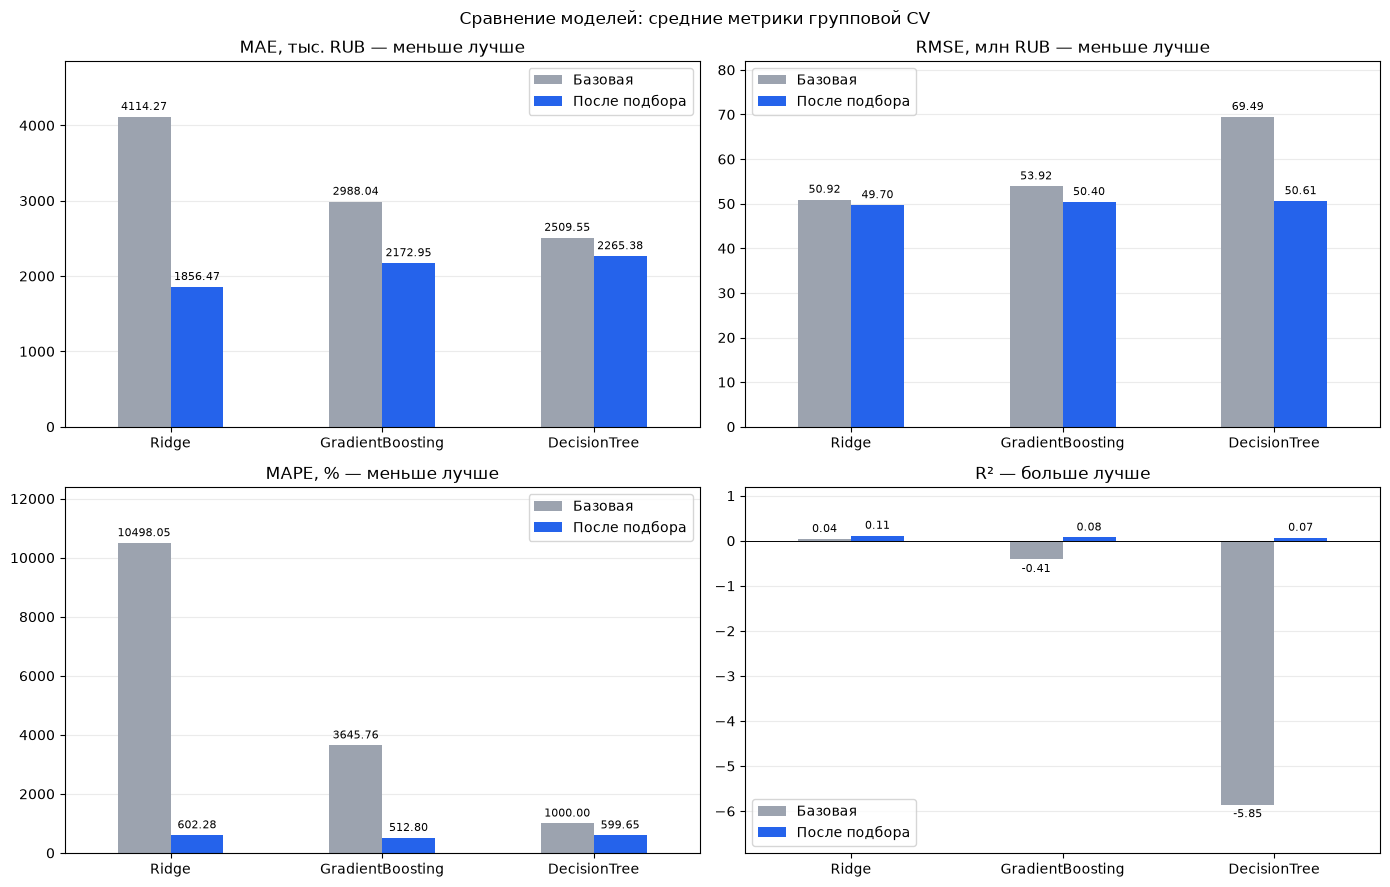

In [159]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (metric, label, scale) in zip(axes.flat, plot_settings):
    values = pd.DataFrame({
        "Базовая":
            baseline_results.loc[model_order, metric] / scale,
        "После подбора":
            tuned_results.loc[model_order, metric] / scale
    })

    values.plot.bar(
        ax=ax,
        rot=0,
        color=["#9ca3af", "#2563eb"]
    )

    ax.set_title(label)
    ax.set_xlabel("")
    ax.axhline(0, color="black", linewidth=0.7)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.margins(y=0.18)

    for bars in ax.containers:
        ax.bar_label(
            bars,
            fmt="%.2f",
            padding=3,
            fontsize=8
        )

fig.suptitle(
    "Сравнение моделей: средние метрики групповой CV"
)

plt.tight_layout()
plt.show()

In [161]:
# Предварительный лидер по прежней основной метрике
leader_name = tuned_results["MAE_CV"].idxmin()

In [162]:
diagnostic_data = pd.DataFrame({
    "Тип": X_train["listing_type"],
    "Факт": y_train,
    "Прогноз": tuned_oof[leader_name]
})

In [163]:
diagnostic_data["Остаток"] = (
    diagnostic_data["Факт"]
    - diagnostic_data["Прогноз"]
)

In [164]:
nonpositive_diagnostic_predictions = int(
    diagnostic_data["Прогноз"].le(0).sum()
)
print(
    "Неположительных OOF-прогнозов у предварительного лидера:",
    nonpositive_diagnostic_predictions,
)


Неположительных OOF-прогнозов у предварительного лидера: 0


In [165]:
listing_types = sorted(diagnostic_data["Тип"].unique())

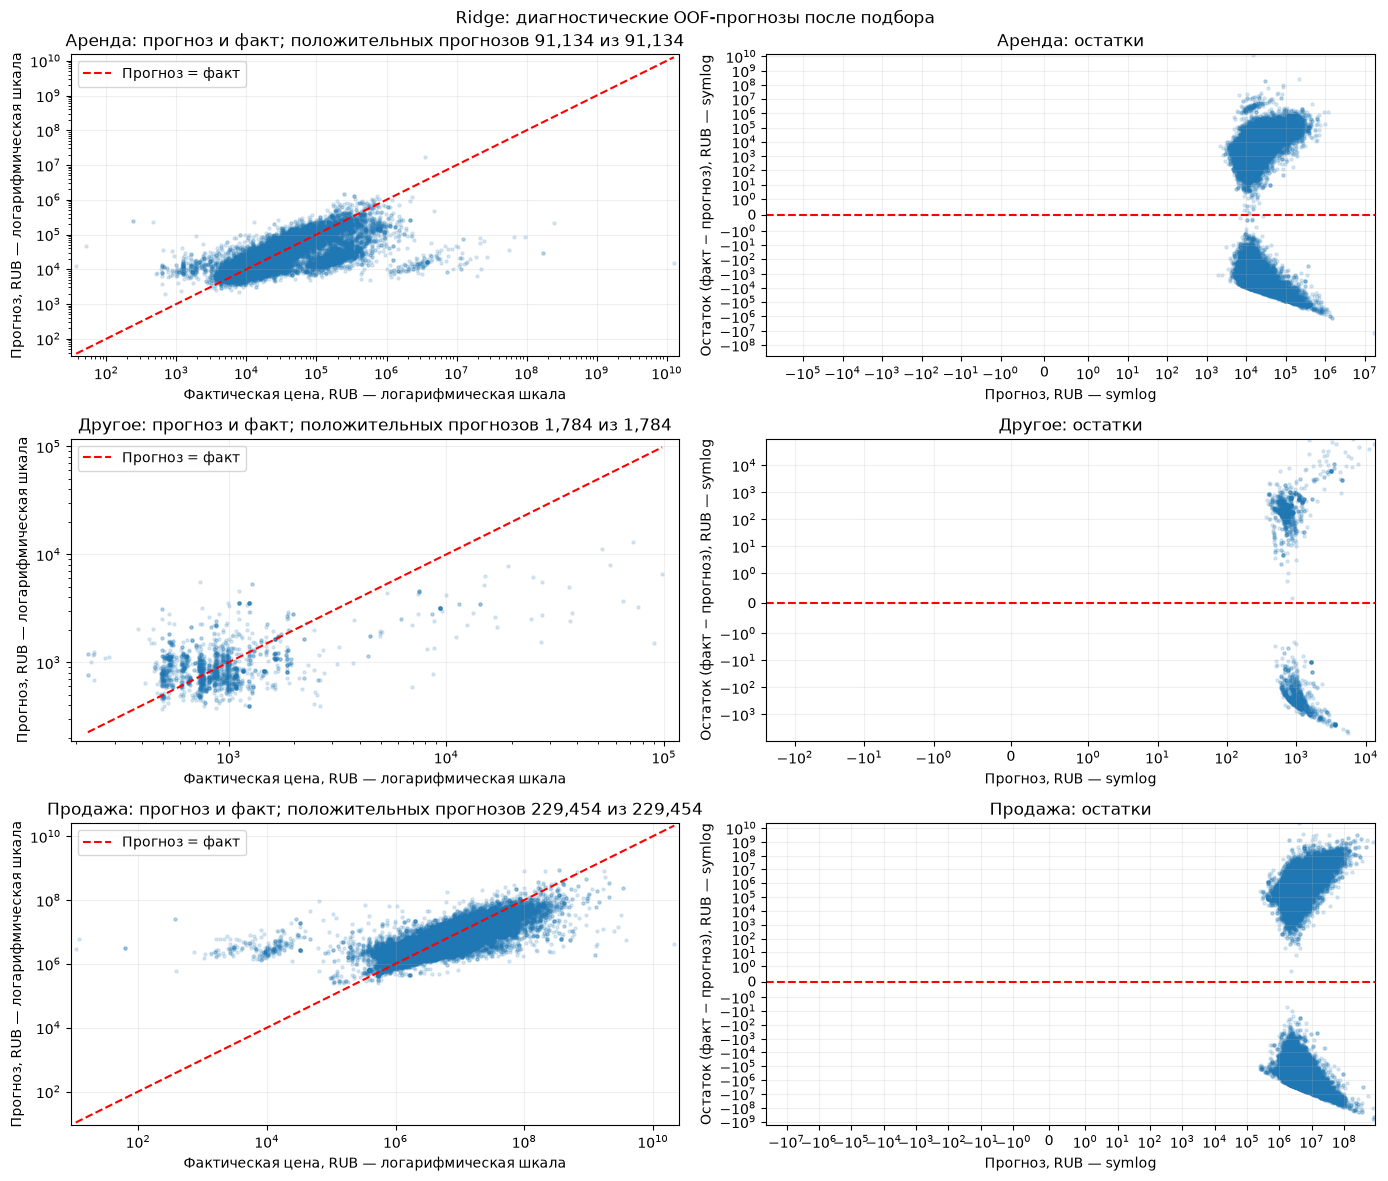

In [166]:
fig, axes = plt.subplots(
    len(listing_types),
    2,
    figsize=(14, 4 * len(listing_types)),
    squeeze=False,
)

for row, listing_type in enumerate(listing_types):
    points = diagnostic_data.loc[
        diagnostic_data["Тип"].eq(listing_type)
    ]
    positive_points = points.loc[
        points["Факт"].gt(0) & points["Прогноз"].gt(0)
    ]

    left, right = axes[row]

    # Для логарифмического графика факт–прогноз нужны положительные значения.
    # Неположительные прогнозы не скрываются: их число напечатано выше, а сами
    # наблюдения остаются на графике остатков справа.
    if positive_points.empty:
        left.text(
            0.5, 0.5, "Нет положительных прогнозов",
            ha="center", va="center", transform=left.transAxes,
        )
    else:
        left.scatter(
            positive_points["Факт"],
            positive_points["Прогноз"],
            s=5,
            alpha=0.15,
        )

        low = positive_points[["Факт", "Прогноз"]].min().min()
        high = positive_points[["Факт", "Прогноз"]].max().max()
        if np.isclose(low, high):
            low, high = low / 1.2, high * 1.2

        left.plot([low, high], [low, high], "r--", label="Прогноз = факт")
        left.set_xscale("log")
        left.set_yscale("log")
        left.set_xlim(low / 1.2, high * 1.2)
        left.set_ylim(low / 1.2, high * 1.2)
        left.legend()

    left.set_xlabel("Фактическая цена, RUB — логарифмическая шкала")
    left.set_ylabel("Прогноз, RUB — логарифмическая шкала")
    left.set_title(
        f"{listing_type}: прогноз и факт; "
        f"положительных прогнозов {len(positive_points):,} из {len(points):,}"
    )

    right.scatter(
        points["Прогноз"],
        points["Остаток"],
        s=5,
        alpha=0.15,
    )
    right.axhline(0, color="red", linestyle="--")
    right.set_xscale("symlog", linthresh=1)
    right.set_yscale("symlog", linthresh=1)
    right.set_xlabel("Прогноз, RUB — symlog")
    right.set_ylabel("Остаток (факт − прогноз), RUB — symlog")
    right.set_title(f"{listing_type}: остатки")

    for ax in [left, right]:
        ax.grid(alpha=0.2)

fig.suptitle(
    f"{leader_name}: диагностические OOF-прогнозы после подбора"
)
plt.tight_layout()
plt.show()


Графики предварительного лидера показывают, насколько прогнозы воспроизводят
различия в фактических ценах. Систематический рисунок и неодинаковый разброс
остатков указывают на ограничения модели, даже если отрицательных прогнозов
нет. Окончательное решение принимается после анализа признаков и ошибок.


#### Анализ коэффициентов и важности признаков

Для интерпретации используются настроенные модели, обученные на всём train.
Коэффициенты Ridge относятся к выбранной при настройке шкале цели и к уже
преобразованным признакам, поэтому не выражают прямое изменение цены в рублях.
Для деревьев показывается MDI-важность; она описывает работу модели, но не
доказывает причинное влияние признаков на стоимость. Test не используется.


In [167]:
feature_labels = {
    "size": "Площадь",
    "rooms_total": "Всего комнат",
    "living_rooms": "Гостиные",
    "listing_time_days": "Время публикации",
    "rooms_missing": "Неизвестная планировка",
    "listing_type": "Тип объявления",
    "sub_type": "Подтип недвижимости",
    "heating_type": "Отопление",
    "floor_no": "Этаж",
    "building_age": "Возраст здания",
    "total_floor_count": "Этажность здания",
    "address": "Адрес"
}

In [168]:
def feature_source(name):
    # Полные префиксы именно нашей предобработки.
    direct = {
        "size__size": "size",
        "rooms__rooms_total": "rooms_total",
        "rooms__living_rooms": "living_rooms",
        "time__listing_time_days": "listing_time_days",
        "binary__rooms_missing": "rooms_missing"
    }

    matches = [direct[name]] if name in direct else []

    for column in ["building_age", "total_floor_count"]:
        if name in [
            f"categories__ordinal__{column}",
            f"categories__ordinal__missingindicator_{column}"
        ]:
            matches.append(column)

    for column in [
        "listing_type", "sub_type", "heating_type", "floor_no"
    ]:
        if name.startswith(f"categories__nominal__{column}_"):
            matches.append(column)

    if name.startswith("categories__address__address_"):
        matches.append("address")

    if len(matches) != 1:
        raise ValueError(
            f"Не удалось однозначно сопоставить признак: {name}"
        )

    return matches[0]

In [169]:
def fitted_feature_table(model_name):
    wrapped = best_models[model_name]
    fitted_pipeline = wrapped.regressor_
    fitted_preprocessor = fitted_pipeline.named_steps["preprocess"]
    fitted_model = fitted_pipeline.named_steps["model"]

    names = fitted_preprocessor.get_feature_names_out()
    assert len(names) == fitted_model.n_features_in_
    assert len(set(names)) == len(names)

    table = pd.DataFrame({"Признак после обработки": names})
    table["Признак до кодирования"] = (
        table["Признак после обработки"].map(feature_source)
    )
    return fitted_model, fitted_preprocessor, table


In [170]:
ridge_model, ridge_preprocessor, ridge_coefficients = (
    fitted_feature_table("Ridge")
)

ridge_coefficients["Коэффициент"] = (
    np.asarray(ridge_model.coef_).ravel()
)

assert np.isfinite(ridge_coefficients["Коэффициент"]).all()

ridge_coefficients["Модуль коэффициента"] = (
    ridge_coefficients["Коэффициент"].abs()
)

ridge_coefficients = ridge_coefficients.sort_values(
    "Модуль коэффициента",
    ascending=False
)

Топ коэффициентов нужен, чтобы посмотреть, на какие признаки модель сильно реагирует в плюс или в минус.

In [171]:
ridge_target_label = (
    f"log({target})" if best_models["Ridge"].func is np.log else target
)
print(
    "20 наибольших по модулю коэффициентов; цель —",
    ridge_target_label,
)
display(ridge_coefficients.head(20).round(4))


20 наибольших по модулю коэффициентов; цель — log(price_rub)


,Признак после обработки,Признак до кодирования,Коэффициент,Модуль коэффициента
6,categories__nominal__listing_type_Продажа,listing_type,5.3835,5.3835
2417,categories__address__address_İstanbul/Şişli/Ha...,address,2.8171,2.8171
1983,categories__address__address_İstanbul/Beşiktaş...,address,2.6404,2.6404
2264,categories__address__address_İstanbul/Sarıyer/...,address,2.6271,2.6271
5,categories__nominal__listing_type_Другое,listing_type,-2.5886,2.5886
1991,categories__address__address_İstanbul/Beşiktaş...,address,2.5400,2.5400
2275,categories__address__address_İstanbul/Sarıyer/...,address,2.4242,2.4242
1982,categories__address__address_İstanbul/Beşiktaş...,address,2.2518,2.2518
2644,categories__address__address_İzmir/Çeşme/Celal...,address,2.2511,2.2511
1998,categories__address__address_İstanbul/Beşiktaş...,address,2.1758,2.1758


In [172]:
print("Коэффициенты остальных характеристик")
with pd.option_context("display.max_rows", None):
    display(
        ridge_coefficients.loc[
            ridge_coefficients["Признак до кодирования"].ne("address")
        ].round(4)
    )


Коэффициенты остальных характеристик


,Признак после обработки,Признак до кодирования,Коэффициент,Модуль коэффициента
6,categories__nominal__listing_type_Продажа,listing_type,5.3835,5.3835
5,categories__nominal__listing_type_Другое,listing_type,-2.5886,2.5886
15,categories__nominal__sub_type_Сборный дом,sub_type,-1.6357,1.6357
10,categories__nominal__sub_type_Кооператив,sub_type,-1.1363,1.1363
12,categories__nominal__sub_type_Особняк / Конак ...,sub_type,0.7427,0.7427
4,binary__rooms_missing,rooms_missing,0.5521,0.5521
8,categories__nominal__sub_type_Квартира,sub_type,-0.5458,0.5458
9,categories__nominal__sub_type_Квартира у воды,sub_type,0.4505,0.4505
25,categories__nominal__heating_type_Печь (уголь),heating_type,-0.4084,0.4084
59,categories__nominal__floor_no_Подвал,floor_no,-0.3863,0.3863


In [173]:
# Базовые категории нужны для интерпретации One-Hot коэффициентов
nominal_fitted = (
    ridge_preprocessor
    .named_transformers_["categories"]
    .named_transformers_["nominal"]
)

reference_categories = pd.DataFrame({
    "Признак": nominal_fitted.feature_names_in_,
    "Базовая категория": [
        categories[int(drop_index)]
        for categories, drop_index in zip(
            nominal_fitted.categories_,
            nominal_fitted.drop_idx_
        )
    ]
})

display(reference_categories)

,Признак,Базовая категория
0,listing_type,Аренда
1,sub_type,Вилла
2,heating_type,Kalorifer (Akaryakıt)
3,floor_no,1


In [174]:
address_fitted = (
    ridge_preprocessor
    .named_transformers_["categories"]
    .named_transformers_["address"]
)

In [175]:
address_base = address_fitted.categories_[0][
    int(address_fitted.drop_idx_[0])
]

In [176]:
rare_addresses = address_fitted.infrequent_categories_[0]

In [177]:
if rare_addresses is not None and address_base in rare_addresses:
    address_base = "Группа редких адресов"

In [178]:
print("Базовая категория адреса:", address_base)

Базовая категория адреса: Adana/Kozan/Karacaoğlan


In [179]:
ridge_top = (
    ridge_coefficients.head(20)
    .sort_values("Коэффициент")
)


In [180]:
ridge_plot_labels = (
    ridge_top["Признак после обработки"]
    .str.replace(
        "categories__address__address_",
        "Адрес: ",
        regex=False
    )
    .str.replace(
        "categories__nominal__listing_type_",
        "Тип объявления: ",
        regex=False
    )
)

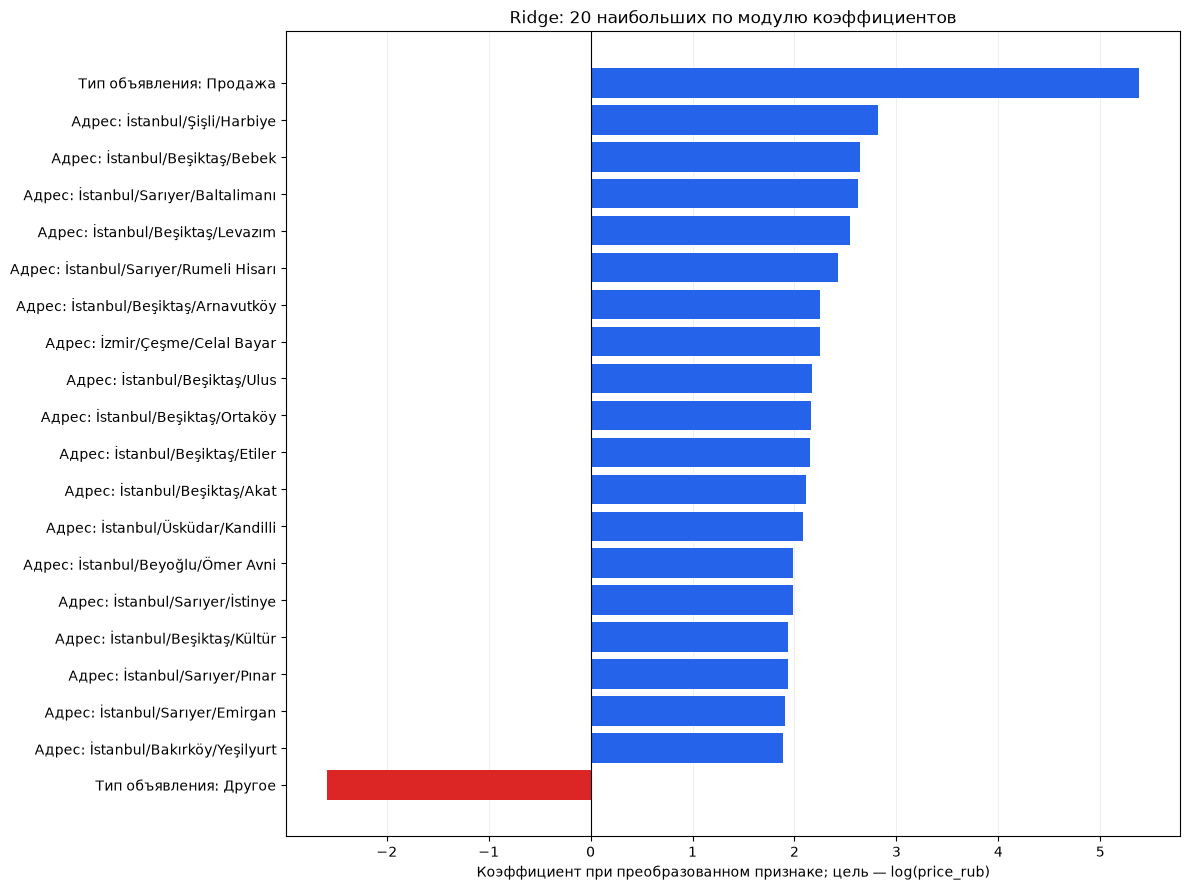

In [181]:
fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(
    ridge_plot_labels,
    ridge_top["Коэффициент"],
    color=np.where(
        ridge_top["Коэффициент"] >= 0,
        "#2563eb",
        "#dc2626"
    )
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Ridge: 20 наибольших по модулю коэффициентов")
ax.set_xlabel(
    "Коэффициент при преобразованном признаке; "
    f"цель — {ridge_target_label}"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Синий столбец означает положительную связь с прогнозом, красный — отрицательную.Это описание того, как именно обученная модель использует признаки

**Интерпретация коэффициентов Ridge**

Знак коэффициента показывает направление связи прогноза с преобразованным
признаком при прочих равных. Для One-Hot-категорий сравнение выполняется с
базовой категорией, указанной в таблице выше. Площадь логарифмирована и
масштабирована, а шкала цели выбирается по CV и выводится над таблицей. Поэтому
коэффициенты нельзя трактовать как изменение стоимости на фиксированное число
рублей.


In [182]:
tree_importances = {}
grouped_importances = {}

for name in ["DecisionTree", "GradientBoosting"]:
    fitted_model, _, table = fitted_feature_table(name)

    table["Важность MDI"] = fitted_model.feature_importances_

    assert np.isfinite(table["Важность MDI"]).all()
    assert table["Важность MDI"].ge(0).all()
    assert np.isclose(table["Важность MDI"].sum(), 1)

    tree_importances[name] = table.sort_values(
        "Важность MDI",
        ascending=False
    )

    # Складываем важности всех выходов одного входного признака.
    # Например, категории адреса или ранг возраста и индикатор
    # его пропуска.
    grouped = (
        table.groupby("Признак до кодирования")["Важность MDI"]
        .sum()
    )

    assert np.isclose(
        grouped.sum(),
        table["Важность MDI"].sum()
    )

    grouped_importances[name] = grouped

    print(f"{name}: 15 самых важных признаков после обработки")
    display(tree_importances[name].head(15).round(4))

importance_by_feature = (
    pd.DataFrame(grouped_importances)
    .reindex(feature_labels)
)

assert importance_by_feature.notna().all().all()

print("Суммарная важность по признакам до кодирования, %")
display(
    (100 * importance_by_feature)
    .rename(index=feature_labels)
    .round(2)
)

DecisionTree: 15 самых важных признаков после обработки


,Признак после обработки,Признак до кодирования,Важность MDI
6,categories__nominal__listing_type_Продажа,listing_type,0.9407
1,rooms__rooms_total,rooms_total,0.0218
8,categories__nominal__sub_type_Квартира,sub_type,0.0072
5,categories__nominal__listing_type_Другое,listing_type,0.0070
70,categories__ordinal__total_floor_count,total_floor_count,0.0039
0,size__size,size,0.0033
3,time__listing_time_days,listing_time_days,0.0014
69,categories__ordinal__building_age,building_age,0.0013
25,categories__nominal__heating_type_Печь (уголь),heating_type,0.0007
2683,categories__address__address_infrequent_sklearn,address,0.0007


GradientBoosting: 15 самых важных признаков после обработки


,Признак после обработки,Признак до кодирования,Важность MDI
6,categories__nominal__listing_type_Продажа,listing_type,0.9486
1,rooms__rooms_total,rooms_total,0.0170
8,categories__nominal__sub_type_Квартира,sub_type,0.0089
5,categories__nominal__listing_type_Другое,listing_type,0.0068
0,size__size,size,0.0053
70,categories__ordinal__total_floor_count,total_floor_count,0.0026
25,categories__nominal__heating_type_Печь (уголь),heating_type,0.0008
15,categories__nominal__sub_type_Сборный дом,sub_type,0.0008
2683,categories__address__address_infrequent_sklearn,address,0.0006
1998,categories__address__address_İstanbul/Beşiktaş...,address,0.0005


Суммарная важность по признакам до кодирования, %


,DecisionTree,GradientBoosting
Признак до кодирования,,
Площадь,0.33,0.53
Всего комнат,2.18,1.70
Гостиные,0.01,0.00
Время публикации,0.14,0.03
Неизвестная планировка,0.04,0.03
Тип объявления,94.77,95.54
Подтип недвижимости,0.92,1.03
Отопление,0.23,0.16
Этаж,0.06,0.01


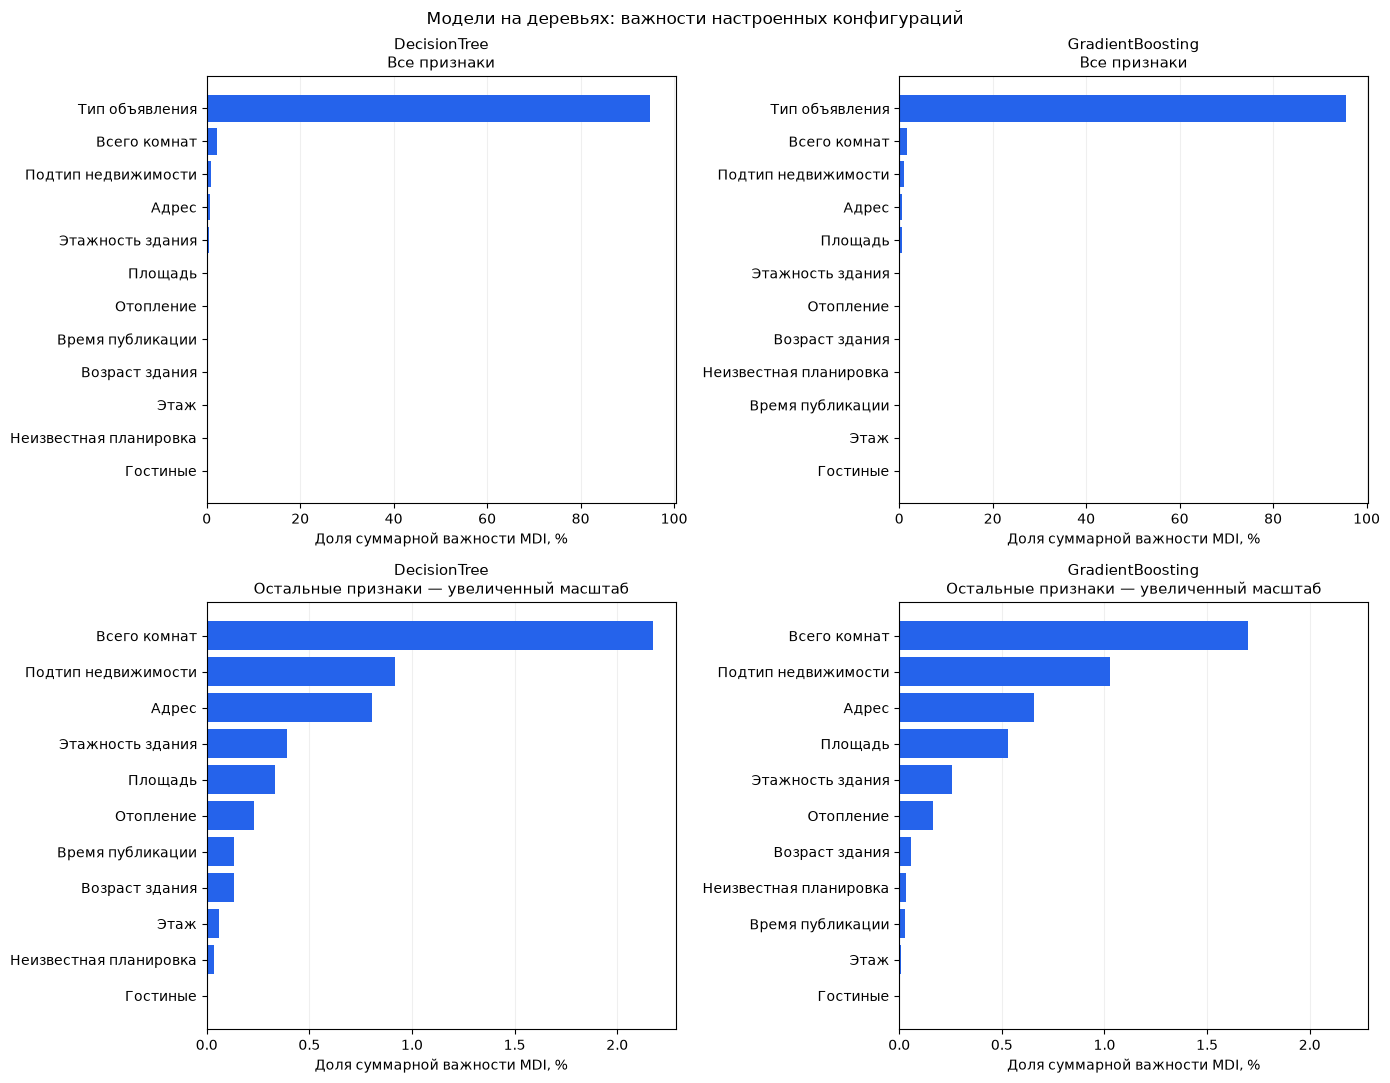

In [183]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11),
    sharex="row"
)

for column, name in enumerate(
    ["DecisionTree", "GradientBoosting"]
):
    all_values = 100 * importance_by_feature[name]

    for row in [0, 1]:
        # Нижний ряд подробнее показывает остальные признаки.
        # Их доли сохраняются: повторной нормировки нет.
        values = (
            all_values
            if row == 0
            else all_values.drop("listing_type")
        )
        values = values.sort_values()

        ax = axes[row, column]

        ax.barh(
            values.index.map(feature_labels),
            values.values,
            color="#2563eb"
        )

        suffix = (
            "Все признаки"
            if row == 0
            else "Остальные признаки — увеличенный масштаб"
        )

        ax.set_title(f"{name}\n{suffix}", fontsize=11)
        ax.set_xlabel("Доля суммарной важности MDI, %")
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)

fig.suptitle(
    "Модели на деревьях: важности настроенных конфигураций"
)

plt.tight_layout()
plt.show()

**Интерпретация важности признаков**

Таблица показывает, какие исходные характеристики чаще используются моделями
на деревьях для уменьшения ошибки. Важности всех закодированных категорий одного
признака суммированы. MDI может быть смещена в пользу признаков с большим числом
вариантов, поэтому небольшая важность сама по себе не является основанием для
удаления признака.


**Дополнительный анализ крупнейших ошибок**

Для лидера по CV исследуются абсолютная ошибка в рублях, квадрат ошибки и
относительная ошибка. Также рассчитывается медианная APE и доля крупнейших
ошибок в общей сумме. Исходные цена и валюта используются только для проверки
подозрительных записей; сами строки не удаляются без подтверждения ошибки.


In [184]:
assert X_train.index.is_unique and df.index.is_unique
assert diagnostic_data.index.equals(X_train.index)
assert y_train.index.equals(X_train.index)
assert groups_train.index.equals(X_train.index)
assert tuned_oof.index.equals(X_train.index)

In [185]:
assert diagnostic_data["Тип"].equals(X_train["listing_type"])
assert np.array_equal(diagnostic_data["Факт"], y_train)
assert np.array_equal(
    diagnostic_data["Прогноз"],
    tuned_oof[leader_name]
)

In [186]:
assert np.isfinite(
    diagnostic_data[["Факт", "Прогноз"]].to_numpy()
).all()
assert diagnostic_data["Факт"].gt(0).all()

In [187]:
error_analysis = diagnostic_data.copy()

In [188]:
error_analysis["Остаток"] = (
    error_analysis["Факт"] - error_analysis["Прогноз"]
)

In [189]:
error_analysis["AE"] = error_analysis["Остаток"].abs()
error_analysis["SE"] = error_analysis["Остаток"].pow(2)
error_analysis["APE_%"] = (
    100 * error_analysis["AE"] / error_analysis["Факт"]
)

In [190]:
assert np.isfinite(
    error_analysis[["AE", "SE", "APE_%"]].to_numpy()
).all()

In [191]:
error_analysis["id"] = df.loc[error_analysis.index, "id"]
error_analysis["group_id"] = groups_train

error_analysis["Строк группы в train"] = (
    groups_train.map(groups_train.value_counts())
)


In [192]:
print(
    f"Анализируем {leader_name}: "
    f"{len(error_analysis):,} OOF-прогнозов"
)

Анализируем Ridge: 322,372 OOF-прогнозов


In [193]:
def top_error_share(values, k=10):
    total = values.sum()
    return (
        100 * values.nlargest(k).sum() / total
        if total > 0
        else np.nan
    )

In [194]:
def summarize_errors(part):
    return {
        "Количество": len(part),
        "MAE, RUB": part["AE"].mean(),
        "RMSE, RUB": np.sqrt(part["SE"].mean()),
        "MAPE, %": part["APE_%"].mean(),
        "Медиана APE, %": part["APE_%"].median(),
        "Топ-10: доля суммы AE, %": top_error_share(part["AE"]),
        "Топ-10: доля суммы SE, %": top_error_share(part["SE"]),
        "Топ-10: доля суммы APE, %": top_error_share(part["APE_%"])
    }

In [195]:
error_rows = [{
    "Выборка": "Весь train",
    **summarize_errors(error_analysis)
}]
for listing_type, part in error_analysis.groupby("Тип", sort=True):
    error_rows.append({
        "Выборка": f"Тип {listing_type}",
        **summarize_errors(part)
    })

In [196]:
error_summary = (
    pd.DataFrame(error_rows)
    .set_index("Выборка")
)

In [197]:
print("Метрики по объединённым OOF-прогнозам")
display(error_summary.iloc[:, :5].round(2))

Метрики по объединённым OOF-прогнозам


,Количество,"MAE, RUB","RMSE, RUB","MAPE, %","Медиана APE, %"
Выборка,,,,,
Весь train,322372,1819584.21,48731339.31,402.89,19.58
Тип Аренда,91134,169246.75,41944293.63,36.23,20.53
Тип Другое,1784,927.67,4851.34,46.83,31.66
Тип Продажа,229454,2489201.37,51357939.45,551.29,19.17


In [198]:
print(
    "Концентрация ошибок: доли десяти крупнейших "
    "значений в каждой выборке"
)
display(error_summary.iloc[:, 5:].round(4))

Концентрация ошибок: доли десяти крупнейших значений в каждой выборке


,"Топ-10: доля суммы AE, %","Топ-10: доля суммы SE, %","Топ-10: доля суммы APE, %"
Выборка,,,
Весь train,9.6934,90.3495,82.4959
Тип Аренда,87.7800,99.9962,12.2433
Тип Другое,34.1058,86.4535,5.5815
Тип Продажа,8.0383,88.2987,84.7037


In [199]:
top_absolute_errors = error_analysis.nlargest(10, "AE")
top_relative_errors = error_analysis.nlargest(10, "APE_%")

In [200]:
detail_columns = [
    "id", "Тип", "Факт", "Прогноз", "AE", "APE_%",
    "group_id", "Строк группы в train"
]

In [201]:
detail_names = {
    "Факт": "Факт, RUB",
    "Прогноз": "Прогноз, RUB",
    "AE": "Абсолютная ошибка, RUB",
    "APE_%": "Относительная ошибка, %"
}

In [202]:
for title, table in [
    ("10 наибольших ошибок в рублях", top_absolute_errors),
    ("10 наибольших относительных ошибок", top_relative_errors)
]:
    print(title)

    with pd.option_context(
        "display.float_format",
        lambda value: f"{value:,.2f}".replace(",", " ")
    ):
        display(
            table[detail_columns].rename(columns=detail_names)
        )

10 наибольших ошибок в рублях


,id,Тип,"Факт, RUB","Прогноз, RUB","Абсолютная ошибка, RUB","Относительная ошибка, %",group_id,Строк группы в train
392156,392157,Продажа,21 555 973 266.50,4 157 671.38,21 551 815 595.12,99.98,282628,2
397627,397628,Аренда,12 656 608 412.82,14 679.03,12 656 593 733.79,100.00,294582,1
13209,13210,Продажа,3 763 132 461.63,5 431 470.05,3 757 700 991.58,99.86,10552,1
328479,328480,Продажа,3 254 771 606.26,34 728 872.41,3 220 042 733.86,98.93,243500,1
369884,369885,Продажа,3 435 889 540.50,243 405 133.71,3 192 484 406.78,92.92,273278,2
371170,371171,Продажа,3 435 889 540.50,243 405 133.71,3 192 484 406.78,92.92,273278,2
103704,103705,Продажа,2 882 266 861.27,13 859 503.40,2 868 407 357.87,99.52,78829,1
1319,1320,Продажа,2 476 708 600.26,10 695 244.28,2 466 013 355.98,99.57,1102,1
99412,99413,Продажа,2 105 867 782.88,128 593 481.09,1 977 274 301.79,93.89,75535,2
112630,112631,Продажа,2 105 867 782.88,128 593 481.09,1 977 274 301.79,93.89,75535,2


10 наибольших относительных ошибок


,id,Тип,"Факт, RUB","Прогноз, RUB","Абсолютная ошибка, RUB","Относительная ошибка, %",group_id,Строк группы в train
126061,126062,Продажа,12.21,6 166 986.42,6 166 974.21,50 521 638.67,94660,1
233698,233699,Продажа,10.70,2 912 523.42,2 912 512.72,27 228 650.56,174087,1
370081,370082,Продажа,376.23,25 975 531.10,25 975 154.87,6 903 998.41,273463,2
373947,373948,Продажа,376.23,25 975 531.10,25 975 154.87,6 903 998.41,273463,2
397991,397992,Продажа,62.73,3 043 309.02,3 043 246.29,4 851 567.75,294792,3
400776,400777,Продажа,62.73,3 043 309.02,3 043 246.29,4 851 567.75,294792,3
400780,400781,Продажа,62.73,3 043 309.02,3 043 246.29,4 851 567.75,294792,3
378297,378298,Продажа,1 630.53,6 201 438.64,6 199 808.11,380 233.05,279735,6
342562,342563,Продажа,740.01,2 419 610.71,2 418 870.70,326 869.63,254232,1
401539,401540,Продажа,1 902.28,6 201 438.64,6 199 536.35,325 899.76,279735,6


In [203]:
# Объединяем индексы двух списков
# Одну строку не показываем дважды
review_indices = top_absolute_errors.index.union(
    top_relative_errors.index,
    sort=False
)

source_review = df.loc[
    review_indices,
    [
        "id", "listing_type", "start_date",
        "price", "price_currency", "size",
        "room_count", "sub_type", "address"
    ]
].copy()

print(
    "Исходные данные выбранных строк; "
    "price указана в price_currency"
)

with pd.option_context(
    "display.max_columns", None,
    "display.max_colwidth", None,
    "display.float_format",
    lambda value: f"{value:,.2f}".replace(",", " ")
):
    display(source_review)

Исходные данные выбранных строк; price указана в price_currency


,id,listing_type,start_date,price,price_currency,size,room_count,sub_type,address
392156,392157,Продажа,9/26/18,2 000 000 000.00,TRY,NaN,+,Квартира,Mersin/Toroslar/Mithat Toroğlu
397627,397628,Аренда,2/17/19,999 999 100.00,TRY,160.00,3+1,Квартира,Samsun/Atakum/Mevlana
13209,13210,Продажа,1/27/19,300 000 000.00,TRY,130.00,3+1,Квартира,İstanbul/Bağcılar/Merkez
328479,328480,Продажа,12/7/18,260 000 000.00,TRY,28 323.00,+,Целое здание,İstanbul/Şişli/Mecidiyeköy
369884,369885,Продажа,10/11/18,310 000 000.00,TRY,NaN,10+0,Особняк / Конак / У воды,İstanbul/Üsküdar/Kandilli
371170,371171,Продажа,10/11/18,310 000 000.00,TRY,NaN,10+0,Особняк / Конак / У воды,İstanbul/Üsküdar/Kandilli
103704,103705,Продажа,10/22/18,250 000 000.00,TRY,NaN,+,Целое здание,Adana/Yumurtalık/Akyuva
1319,1320,Продажа,2/26/19,200 000 000.00,TRY,140.00,+,Целое здание,İstanbul/Fatih/Rüstem Paşa
99412,99413,Продажа,10/11/18,190 000 000.00,TRY,NaN,5+2,Особняк / Конак / У воды,İstanbul/Sarıyer/Yeniköy
112630,112631,Продажа,10/11/18,190 000 000.00,TRY,NaN,5+2,Особняк / Конак / У воды,İstanbul/Sarıyer/Yeniköy


**Вывод по анализу крупнейших ошибок**

Сравнение MAE, RMSE, средней и медианной APE показывает, насколько итоговые
метрики зависят от небольшого числа экстремальных объявлений. Исходные цены
проверяются вместе с валютой: значения вроде 1 или 5 TRY и чрезвычайно крупные
цены требуют проверки по первоисточнику. Большая ошибка прогноза сама по себе
не является достаточным основанием автоматически удалить строку.


### 3.5 Выбор финальной модели

In [204]:
from time import perf_counter

In [205]:
speed_sample = X_train.sample(
    n=min(1000, len(X_train)),
    random_state=random_state
)

In [206]:
single_requests = [
    speed_sample.iloc[[i]].copy()
    for i in range(min(10, len(speed_sample)))
]


In [207]:
speed_rows = []

for name, model in best_models.items():
    # Прогрев перед измерением
    model.predict(speed_sample)
    model.predict(single_requests[0])

    single_times, batch_times = [], []

    for _ in range(5):
        for request in single_requests:
            started = perf_counter()
            model.predict(request)
            single_times.append(
                1000 * (perf_counter() - started)
            )

        started = perf_counter()
        model.predict(speed_sample)
        batch_times.append(
            1000 * (perf_counter() - started)
        )

    speed_rows.append({
        "Модель": name,
        "Одно объявление, мс": np.median(single_times),
        "Пакет, мс": np.median(batch_times)
    })


In [208]:
prediction_speed = (
    pd.DataFrame(speed_rows).set_index("Модель")
)

In [209]:
selection_table = tuned_results[
    ["MAE_CV", "MAE_CV_std", "MAE_train"]
].join(prediction_speed)


In [210]:
selection_table["Разрыв CV/train, %"] = (
    100 * (
        selection_table["MAE_CV"]
        / selection_table["MAE_train"] - 1
    )
)

In [211]:
print(
    f"Размер пакета для измерения скорости: "
    f"{len(speed_sample)} строк"
)
display(selection_table.round(3))

Размер пакета для измерения скорости: 1000 строк


,MAE_CV,MAE_CV_std,MAE_train,"Одно объявление, мс","Пакет, мс","Разрыв CV/train, %"
Модель,,,,,,
Ridge,1820355.243,158172.121,1784640.683,56.082,64.479,2.001
DecisionTree,2236047.834,148148.821,1990051.650,53.282,61.164,12.361
GradientBoosting,2263500.552,152224.012,2256532.784,56.474,64.363,0.309


In [212]:
# Финальную модель выбираем до обращения к test — только по результатам CV.
final_model_name = tuned_results["MAE_CV"].idxmin()


In [213]:
assert final_model_name in best_models


In [214]:
final_model = best_models[final_model_name]

In [215]:
final_target_scale = (
    f"log({target})" if final_model.func is np.log else target
)


In [216]:
print("Выбрана модель:", final_model_name)
print("Цель при обучении:", final_target_scale)
print("Лучшие параметры:", best_parameters.loc[final_model_name, "Лучшие параметры"])


Выбрана модель: Ridge
Цель при обучении: log(price_rub)
Лучшие параметры: {'alpha': 0.1}


**Обоснование выбора финальной модели**

Финальная модель выбирается по минимальной средней MAE групповой CV до оценки
на test. Дополнительно рассматриваются разброс качества между разбиениями,
разрыв между train и CV, скорость прогнозирования и интерпретируемость.
Отложенный test используется один раз только для итоговой проверки.

In [217]:
assert X_test.index.equals(y_test.index)
assert X_test.index.equals(groups_test.index)
assert list(X_test.columns) == list(X_train.columns)


In [218]:
assert X_train.index.intersection(X_test.index).empty
assert set(groups_train).isdisjoint(set(groups_test))


In [219]:
assert np.isfinite(y_test).all()
assert y_test.gt(0).all()

In [220]:
test_predictions = pd.Series(
    final_model.predict(X_test),
    index=X_test.index,
    name="Прогноз, RUB"
)

C:\Users\polin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


In [221]:
assert np.isfinite(test_predictions).all()

In [222]:
test_rows = [{
    "Выборка": "Весь test",
    "Количество": len(y_test),
    **regression_metrics(y_test, test_predictions)
}]

for listing_type in sorted(X_test["listing_type"].unique()):
    mask = X_test["listing_type"].eq(listing_type)

    test_rows.append({
        "Выборка": f"Тип {listing_type}",
        "Количество": int(mask.sum()),
        **regression_metrics(
            y_test.loc[mask],
            test_predictions.loc[mask]
        )
    })

In [223]:
test_results = (
    pd.DataFrame(test_rows).set_index("Выборка")
)

In [224]:
display(
    test_results.round({
        "MAE": 2,
        "RMSE": 2,
        "MAPE_%": 2,
        "R2": 6
    })
)

,Количество,MAE,RMSE,MAPE_%,R2
Выборка,,,,,
Весь test,80355,1952678.70,71820789.12,839.79,0.077807
Тип Аренда,22967,307997.72,43043285.76,40.65,-0.000043
Тип Другое,450,554.40,1846.42,42.69,0.240824
Тип Продажа,56938,2631519.62,80822820.30,1168.44,0.084688


In [225]:
print(
    "Нулевых прогнозов:",
    int(test_predictions.eq(0).sum())
)
print(
    "Отрицательных прогнозов:",
    int(test_predictions.lt(0).sum())
)


Нулевых прогнозов: 0
Отрицательных прогнозов: 0


**Результаты итоговой проверки**

Таблица выше содержит независимые test-метрики в рублях для всей выборки и
отдельно по типам объявлений. Эти результаты не используются для повторной
настройки модели или удаления неудобных наблюдений. Высокая MAPE, низкий R² или
большое различие качества между группами должны быть явно указаны как
ограничения приложения.


In [226]:
from pathlib import Path
import importlib.util
import json
import platform
from importlib.metadata import version
import joblib


In [227]:
artifact_dir = (project_dir / "artifacts_model_v2").resolve()
artifact_dir.mkdir(parents=True, exist_ok=True)

In [228]:
feature_preparation_source = r'''
import numpy as np
import pandas as pd
RAW_COLUMNS = [
    "size", "room_count", "start_date", "listing_type", "sub_type",
    "heating_type", "floor_no", "building_age", "total_floor_count", "address"
]
MODEL_COLUMNS = [
    "size", "rooms_total", "living_rooms", "listing_time_days", "rooms_missing",
    "listing_type", "sub_type", "heating_type", "floor_no", "building_age",
    "total_floor_count", "address"
]
def prepare_features(raw):
    # size — числовой признак; listing_type и остальные категории — строки
    # start_date имеет формат %m/%d/%y, например "2/17/19"
    result = raw.loc[:, RAW_COLUMNS].copy()

    missing_columns = [
        "building_age", "total_floor_count", "floor_no",
        "heating_type", "room_count"
    ]
    result[missing_columns] = (
        result[missing_columns].fillna("Не указано")
    )

    result["size"] = (
        pd.to_numeric(result["size"], errors="raise").astype(float)
    )
    invalid_size = (
        result["size"].lt(10) | result["size"].gt(10_000) | ~np.isfinite(result["size"])
    )
    result.loc[invalid_size, "size"] = np.nan

    room_parts = (
        result["room_count"].astype("string")
        .str.extract(r"^\s*(\d+)\s*\+\s*(\d+)\s*$")
        .apply(pd.to_numeric, errors="coerce")
        .astype(float)
    )

    result["rooms_total"] = room_parts[0] + room_parts[1]
    result["living_rooms"] = room_parts[1]

    invalid_rooms = (
        room_parts.isna().any(axis=1)
        | result["rooms_total"].le(0)
    )

    result.loc[
        invalid_rooms,
        ["rooms_total", "living_rooms"]
    ] = np.nan

    result["rooms_missing"] = invalid_rooms.astype("int8")

    dates = pd.to_datetime(
        result["start_date"],
        format="%m/%d/%y",
        errors="raise"
    )

    result["listing_time_days"] = (
        dates - pd.Timestamp("2018-01-01")
    ).dt.days

    return result.loc[:, MODEL_COLUMNS]
'''

In [229]:
feature_module_path = artifact_dir / "feature_preparation.py"

In [230]:
feature_module_path.write_text(
    feature_preparation_source.strip() + "\n",
    encoding="utf-8"
)

1903

In [231]:
spec = importlib.util.spec_from_file_location(
    "feature_preparation",
    feature_module_path
)

In [232]:
feature_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(feature_module)

In [233]:
assert feature_module.MODEL_COLUMNS == list(X_train.columns)

In [234]:
# Проверяем совпадение с прежней подготовкой данных
export_probe = X_train.sample(
    n=min(100, len(X_train)),
    random_state=random_state
)

raw_probe = df.loc[
    export_probe.index,
    feature_module.RAW_COLUMNS
]

prepared_probe = feature_module.prepare_features(raw_probe)

pd.testing.assert_frame_equal(
    prepared_probe,
    export_probe,
    check_dtype=False
)

In [235]:
package_versions = {
    package: version(package)
    for package in [
        "numpy", "pandas", "scipy", "scikit-learn", "joblib"
    ]
}

In [236]:
train_dates = pd.to_datetime(
    df.loc[X_train.index, "start_date"],
    format="%m/%d/%y"
)


In [237]:
selected_parameters = best_parameters.loc[
    final_model_name, "Лучшие параметры"
]

ridge_alpha = None
if final_model_name == "Ridge":
    ridge_alpha = float(
        final_model.regressor_.named_steps["model"].alpha
    )

model_metadata = {
    "schema_version": 2,
    "model_name": final_model_name,
    "alpha": ridge_alpha,
    "best_parameters": selected_parameters,
    "target": target,
    "prediction_currency": "RUB",
    "target_transform": final_target_scale,
    "feature_columns": list(X_train.columns),
    "raw_columns": feature_module.RAW_COLUMNS,
    "feature_module": "feature_preparation.py",
    "date_format": "%m/%d/%y",
    "date_origin": "2018-01-01",
    "training_date_range": [
        str(train_dates.min().date()),
        str(train_dates.max().date()),
    ],
    "random_state": random_state,
    "python_version": platform.python_version(),
    "package_versions": package_versions,
    "cv_metrics": tuned_results.loc[final_model_name].to_dict(),
    "test_metrics": test_results.to_dict(orient="index"),
    "prediction_speed": prediction_speed.loc[final_model_name].to_dict(),
    "prediction_batch_size": len(speed_sample),
}


In [238]:
model_bundle = {
    "model": final_model,
    "metadata": model_metadata
}

In [239]:
model_path = artifact_dir / "price_model.joblib"


In [240]:
joblib.dump(
    model_bundle,
    model_path,
    compress=3
)

['C:\\Users\\polin\\Downloads\\artifacts\\price_model.joblib']

In [241]:
def json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Объект типа {type(value).__name__} не сериализуется в JSON")


(artifact_dir / "model_metadata.json").write_text(
    json.dumps(
        model_metadata,
        ensure_ascii=False,
        indent=2,
        default=json_default,
    ),
    encoding="utf-8",
)

(artifact_dir / "requirements_model.txt").write_text(
    "\n".join(f"{name}=={value}" for name, value in package_versions.items()) + "\n",
    encoding="utf-8",
)


75

In [242]:
# Загружаем сохранённую модель и сравниваем прогнозы
loaded_bundle = joblib.load(model_path)

In [243]:
expected_predictions = final_model.predict(export_probe)

In [244]:
restored_predictions = (
    loaded_bundle["model"].predict(prepared_probe)
)

In [245]:
np.testing.assert_allclose(
    restored_predictions,
    expected_predictions,
    rtol=1e-12,
    atol=1e-8
)

In [246]:
print(
    "Проверка пройдена: подготовка признаков "
    "и прогнозы после загрузки совпадают."
)

print("Сохранённые файлы:")

for filename in [
    "price_model.joblib",
    "feature_preparation.py",
    "model_metadata.json",
    "requirements_model.txt"
]:
    print(artifact_dir / filename)

Проверка пройдена: подготовка признаков и прогнозы после загрузки совпадают.
Сохранённые файлы:
C:\Users\polin\Downloads\artifacts\price_model.joblib
C:\Users\polin\Downloads\artifacts\feature_preparation.py
C:\Users\polin\Downloads\artifacts\model_metadata.json
C:\Users\polin\Downloads\artifacts\requirements_model.txt


**Сохранение модели и воспроизводимость**

Финальная модель сохраняется вместе с заполнением пропусков, кодированием,
масштабированием и выбранным на CV преобразованием целевой переменной.
Дополнительно создаются модуль подготовки исходных полей, метаданные и точные
версии библиотек. После повторной загрузки прогнозы сравниваются с исходной
моделью. Прогнозы и итоговые метрики выражены в рублях, а поле
`prediction_currency` в метаданных равно `RUB`.


###  Описание выбранных моделей

Одна система прогноза состоит из двух моделей: объявление направляется в нужную модель
по типу сделки. Выбор сделан до оценки внешних 20 объектов, по RMSE/R² в рублях на
пяти исходных групповых фолдах.

- Продажа: Ridge, alpha = 0.1; обучение на log(price_rub), обратное преобразование exp.
  Используются прежняя предобработка, город/район и проверенные дополнительные признаки.
- Аренда: HistGradientBoostingRegressor, loss = gamma; max_iter = 700,
  learning_rate = 0.05, max_leaf_nodes = 31, min_samples_leaf = 35,
  l2_regularization = 5, early_stopping = False, random_state = 42.
  Gamma использует логарифмическую функцию связи, но fit получает цену в рублях,
  а predict уже возвращает рубли: дополнительно применять exp нельзя.

Ранее полученные, округлённые результаты OOF:

| Тип | Модель | MAE, ₽ | RMSE, ₽ | MAPE, % | R² OOF в рублях | Среднее R² CV | R² на log-цене |
|---|---|---:|---:|---:|---:|---:|---:|
| Продажа | Ridge + признаки | 2 213 850.401 | 41 878 174.525 | 76.599 | 0.177 | 0.280 | 0.716 |
| Аренда | HistGB_Gamma | 17 492.232 | 189 861.652 | 43.933 | 0.086 | 0.104 | 0.603 |

Это показатели на обучающем поднаборе по OOF-прогнозам.
Среднее R² по фолдам и R² по объединённым OOF-прогнозам рассчитываются по-разному.
Выбор HistGB_Gamma для аренды основан на RMSE/R²; ExtraTrees давала лучше MAE и MAPE.
Общие ограничения: тяжёлый ценовой хвост, пропуски площади, редкие подтипы.

###  Настройки и чтение файлов

In [206]:
# Перечисляем данные, функции и настройки, необходимые для следующих ячеек
required = [
    "df", "df_clean", "rates",
    "X_train_geo", "X_extra_features", "advanced_X",
    "updated_indices", "y_compare", "feature_templates",
    "add_model_features", "add_extra_features",
    "make_advanced_features", "make_hist_gamma",
    "advanced_specs", "advanced_cat_cols", "advanced_num_cols",
    "MAP_SUB", "MAP_LISTING", "MAP_FLOOR",
    "MAP_FLOOR_COUNT", "MAP_HEATING",
    "extra_numeric_cols",
]
# globals() содержит объекты текущего сеанса
# Собираем названия тех, которые ещё не определены
missing = [name for name in required if name not in globals()]

# Если необходимых объектов нет, останавливаем выполнение
# и показываем их названия.
if missing:
    raise RuntimeError(
        "В текущем ядре отсутствуют переменные: "
        + ", ".join(missing))

# Проверяем, что df содержит таблицу pandas, а не путь к файлу
# Это необходимо для дальнейшей работы со строками и столбцами
if not isinstance(df, pd.DataFrame):
    raise TypeError("df должен быть таблицей pandas, а не путём к файлу.")

In [247]:
NEW_FIO = "Полуэктова Полина Евгеньевна"
NEW_GROUP = "23П-2"

In [207]:
new_samples_raw = pd.read_csv(
    r"C:\Users\polin\Downloads\test_real_estate_samples(1).csv",
    low_memory=False,
)

In [240]:
print("Объектов внешнего теста:", len(new_samples_raw))

Объектов внешнего теста: 20


In [209]:
# Сохраняем исходную таблицу без изменений.
new_samples = new_samples_raw.copy()

In [210]:
# Приводим ID, цену и площадь к числовому типу,а значения, которые нельзя преобразовать в число,заменяем пропусками NaN
for column in ["id", "price", "size"]:
    new_samples[column] = pd.to_numeric(
        new_samples[column], errors="coerce"
    )

In [211]:
# Для каждого столбца указываем словарь перевода и унификации значений
mappings = {
    "sub_type": MAP_SUB,
    "listing_type": MAP_LISTING,
    "floor_no": MAP_FLOOR,
    "total_floor_count": MAP_FLOOR_COUNT,
    "heating_type": MAP_HEATING,
}

In [212]:
# Перебираем столбцы и соответствующие им словари замены
for column, mapping in mappings.items():
    values = (
        new_samples[column]
        .astype("string")
        .str.strip()
        .replace(mapping)
    )
    
 # Сохраняем обработанный столбец
# Пропуски приводим к np.nan для последующей обработки в моделях
    new_samples[column] = (
        values.astype(object).where(values.notna(), np.nan)
    )

In [213]:
if not new_samples["listing_type"].isin(["Продажа", "Аренда"]).all():
    raise ValueError("Обнаружен неподдерживаемый тип объявления.")

In [214]:
# Преобразуем даты публикации из строк в даты pandas
new_dates = pd.to_datetime(
    new_samples["start_date"],
    format="%m/%d/%y",
    errors="raise",
)
# Сортируем таблицу курсов по датам и подбираем курс
# для даты публикации каждого объявления
new_rates = rates.sort_index().reindex(
    new_dates,
    method="ffill",
    tolerance=pd.Timedelta(days=7),
)

In [241]:
from IPython.display import display

# Форматируем сумму: пробелы между разрядами, запятая и два знака после неё
def format_rubles(value):
    return (
        f"{value:,.2f}"
        .replace(",", " ")
        .replace(".", ",")
        + " ₽"
    )

# Настраиваем отображение столбцов в зависимости от их названий
def show_ruble_table(table):
    formatters = {}

    for column in table.columns:
        name = str(column)
 # Квадраты ошибок и отклонений измеряются в квадратных рублях
        if name in {
            "squared_error_rub",
            "squared_deviation_rub",
        }:
            formatters[column] = lambda value: (
                f"{value:,.2f}"
                .replace(",", " ")
                .replace(".", ",")
                + " ₽²"
            )
# Цены, ошибки, MAE и RMSE отображаем в рублях
        elif name in {
            "price_rub",
            "prediction_rub",
            "error_rub",
            "absolute_error_rub",
        } or name.startswith(("MAE", "RMSE")):
            formatters[column] = format_rubles
# R2 не имеет единиц измерения, показываем три знака после запятой
        elif "R2" in name:
            formatters[column] = lambda value: (
                f"{value:.3f}".replace(".", ",")
            )
# Для уже рассчитанных процентов добавляем знак %
        elif name.endswith("_pct") or "%" in name:
            formatters[column] = lambda value: (
                f"{value:.2f}".replace(".", ",") + " %"
            )
 # Применяем оформление только при показе таблицы
    # Исходные числовые данные и точность расчётов не изменяются
    display(
        table.style.format(
            formatters,
            precision=3,
            na_rep="—",
        )
    )

In [243]:
# Согласуем индексы подобранных курсов с индексами объявлений
new_rates.index = new_samples.index
# Курсы заданы относительно EUR, поэтому курс самого EUR равен 1
new_rates["EUR"] = 1.0
# Создаём столбец для цены в рублях, пока заполняя его пропусками
new_samples["price_rub"] = np.nan
new_currencies = (
    new_samples["price_currency"].astype("string").str.strip()
)

unknown_currencies = set(new_currencies.dropna()) - {
    "TRY", "EUR", "GBP", "USD"
}
# Проверяем, нет ли валют, для которых пересчёт не предусмотрен
if unknown_currencies:
    raise ValueError(f"Неизвестные валюты: {unknown_currencies}")

for currency in ["TRY", "EUR", "GBP", "USD"]:
    # Выбираем объявления, цена которых указана в текущей валюте
    mask = new_currencies.eq(currency).fillna(False)

    if not mask.any():
        continue

    selected_rates = new_rates.loc[mask, ["RUB", currency]]

    if (
        selected_rates.isna().any().any()
        or not np.isfinite(
            selected_rates.to_numpy(dtype=float)
        ).all()
        or selected_rates.le(0).any().any()
    ):
        raise ValueError(f"Нет корректного курса для {currency}.")
        
    # Курсы — количество единиц валюты за один EUR
    new_samples.loc[mask, "price_rub"] = (
        new_samples.loc[mask, "price"]
        * new_rates.loc[mask, "RUB"]
        / new_rates.loc[mask, currency]
    )
# Проверяем, что для каждого объекта получена конечная положительная цена
if (
    not np.isfinite(new_samples["price_rub"]).all()
    or not new_samples["price_rub"].gt(0).all()
):
    raise ValueError("Не для всех объектов рассчитана цена в рублях.")
# Показываем исходную цену, валюту и результат пересчёта
display(
    new_samples[
        ["id", "listing_type", "price", "price_currency", "price_rub"]
    ].style.format(
        {
            "price": "{:,.2f}",
            "price_rub": "{:,.2f} ₽",
        },
        subset=["price", "price_rub"],
        thousands=" ",
        decimal=",",
        na_rep="—",
    )
)

,id,listing_type,price,price_currency,price_rub
0,49,Продажа,"300 000,00",TRY,"3 682 640,82 ₽"
1,506,Продажа,"1 600 000,00",TRY,"18 584 861,74 ₽"
2,2,Продажа,"490 000,00",TRY,"6 133 668,22 ₽"
3,528,Продажа,"103 600,00",TRY,"1 277 284,29 ₽"
4,109,Продажа,"300 000,00",TRY,"3 682 640,82 ₽"
5,100,Продажа,"500 000,00",TRY,"6 137 971,25 ₽"
6,320,Продажа,"1 000 000,00",TRY,"12 471 456,25 ₽"
7,3,Продажа,"155 000,00",TRY,"1 686 497,09 ₽"
8,7810,Продажа,"650 000,00",TRY,"8 560 252,48 ₽"
9,11,Продажа,"2 450 000,00",TRY,"30 180 505,04 ₽"


Для всех 20 объектов рассчитана цена в рублях с использованием
исторических курсов на дату публикации объявления. Проверки не выявили
отсутствующих, неположительных или бесконечных значений рассчитанной цены.


Истинные цены и прогнозы далее сравниваются в одной валюте.
Пробелы между разрядами, запятая и символ рубля используются только
для отображения: в расчётах цены остаются числовыми значениями.

### Проверка отсутствия тестовых объектов в train и подготовка признаков

In [216]:
# Объединяем индексы обучающих строк продажи и аренды
# Убираем повторяющиеся индексы, чтобы каждая строка учитывалась один раз
new_train_index = (
    updated_indices["Продажа"]
    .append(updated_indices["Аренда"])
    .drop_duplicates()
)


In [217]:
# Собираем ID внешних тестовых объектов
new_test_ids = set(new_samples["id"])
# Получаем ID объектов из объединённой обучающей выборки
new_train_ids = set(df_clean.loc[new_train_index, "id"])

In [218]:
if new_test_ids & new_train_ids:
    raise ValueError(
        "В train найдены объекты внешнего теста: "
        f"{sorted(new_test_ids & new_train_ids)}"
    )

In [219]:
# Проверяем также совпадающие группы, а не только ID
# Это позволяет обнаружить одинаковые характеристики даже при разных ID
new_group_cols = [
    "sub_type", "start_date", "listing_type", "building_age",
    "total_floor_count", "floor_no", "room_count",
    "size", "address", "heating_type",
]
# Объединяем выбранные поля train и теста в таблицу для проверки совпадений
new_keys = pd.concat(
    [
         # Сначала добавляем характеристики обучающих объектов
        df.loc[new_train_index, new_group_cols],
         # Затем те же характеристики внешних тестовых объектов
        new_samples[new_group_cols],
    ],
    ignore_index=True,# Создаём общую последовательную нумерацию строк
)

In [220]:
# Строкам с одинаковыми значениями всех выбранных полей присваиваем один и тот же номер группы
new_group_numbers = new_keys.groupby(
    new_group_cols,
    dropna=False,
    sort=False,
).ngroup()

In [221]:
# Первые строки объединённой таблицы относятся к train, собираем уникальные номера их групп
new_fit_groups = set(
    new_group_numbers.iloc[:len(new_train_index)]
)
# Оставшиеся строки относятся к внешнему тесту, эти группы далее сравним с группами train
new_test_groups = set(
    new_group_numbers.iloc[len(new_train_index):]
)

In [223]:
if new_fit_groups & new_test_groups:
    raise ValueError(
        "В train найдены группы, совпадающие с внешними объектами. ")

new_external_group_count = len(new_test_groups)

In [224]:
# Обработка соответствует уже использованной при обучении.
new_prepared = new_samples.copy()
new_prepared["room_count"] = (
    new_prepared["room_count"].replace("+", np.nan)
)

In [225]:
for column in [
    "building_age", "total_floor_count",
    "floor_no", "heating_type", "room_count",
]:
    new_prepared[column] = (
        new_prepared[column].fillna("Не указано")
    )

invalid_area = (
    new_prepared["size"].notna()
    & (
        new_prepared["size"].lt(10)
        | new_prepared["size"].gt(10000)
        | ~np.isfinite(new_prepared["size"])
    )
)

In [226]:
# Не удаляем тестовые объекты с неизвестной площадью.
new_prepared.loc[invalid_area, "size"] = np.nan

new_X_geo = add_model_features(new_prepared)

parts = new_X_geo["address"].astype("string").str.split("/")

city = (
    parts.str[0].fillna("Не указано")
    .str.strip().replace("", "Не указано")
)

In [227]:
# Из второй части адреса получаем район
# Пропуски и пустые строки заменяем на Не указано, убираем лишние пробелы
district = (
    parts.str[1].fillna("Не указано")
    .str.strip().replace("", "Не указано")
)

In [228]:
# Добавляем город и район как отдельные признаки
new_X_geo["city"] = city
# Объединяем название района с городом, чтобы одинаковые названия
# районов в разных городах не считались одной категорией
new_X_geo["district"] = city + "/" + district


In [229]:
# Оставляем тот же состав и порядок столбцов, что использовались при обучении
new_X_geo = new_X_geo[X_train_geo.columns].copy()


In [230]:
# Создаём дополнительные признаки по той же функции, что и для train
new_X_extra = add_extra_features(
    new_X_geo,
    new_prepared["room_count"],
)

In [231]:
# Формируем расширенный набор признаков для модели HistGB_Gamma
new_X_advanced = make_advanced_features(new_X_extra)

In [232]:
# Подготавливаем категориальные признаки
# приводим к строкам и заменяем пропуски отдельной категорией
for column in advanced_cat_cols:
    new_X_advanced[column] = (
        new_X_advanced[column]
        .astype("string")
        .fillna("Не указано")
        .astype(str)
    )
# Подготавливаем числовые признаки
# Значения, которые нельзя преобразовать в число, заменяем пропусками
for column in advanced_num_cols:
    new_X_advanced[column] = (
        pd.to_numeric(new_X_advanced[column], errors="coerce")
        .astype(float)
        .replace([np.inf, -np.inf], np.nan)
    )
# Согласуем состав и порядок тестовых признаков с обучающими таблицами
new_X_extra = new_X_extra[X_extra_features.columns]
new_X_advanced = new_X_advanced[advanced_X.columns]

assert len(new_X_extra) == 20
assert len(new_X_advanced) == 20

Тестовые данные подготовлены в соответствии с обработкой, использованной
при обучении моделей. Проверки по ID и заданным группам признаков
не выявили совпадений внешних объектов с обучающей выборкой.

Некорректная запись планировки «+» обработана как неизвестное значение.
Площади вне установленного диапазона, включая 1 м2 у объектов
ID 49 и 109, заменены пропусками в подготовленных признаках.
Тестовые строки при этом не удалялись.

Из адреса выделены город и район. Район записан вместе с городом,
чтобы одинаковые названия районов в разных городах не объединялись.
Состав и порядок признаков согласованы с обучающими таблицами.

Все 20 объектов сохранены. Исходные характеристики остаются в итоговой
таблице, а обработанные значения используются как входы моделей.
Заполнение пропусков не означает восстановления истинной площади.

### Два финальных обучения

In [233]:
# Создаём модели с ранее выбранными настройками
# clone копирует параметры Ridge, но не обученные коэффициенты
new_final_models = {
    "Продажа": clone(feature_templates[("Продажа", "Ridge")]),
    "Аренда": make_hist_gamma(advanced_specs["HistGB_Gamma"]),
}
# Названия моделей для сообщений и итоговой таблицы
new_model_names = {
    "Продажа": "Ridge + признаки",
    "Аренда": "HistGB_Gamma",
}
# Обучаем продажу и аренду отдельно, каждую на своих строках train
for kind, model in new_final_models.items():
    index = updated_indices[kind]
    # Для Ridge берём дополнительные признаки,
    # для HistGB — расширенный набор признаков
    train_inputs = (
        X_extra_features if kind == "Продажа" else advanced_X
    )

    print(
        f"Финальное обучение: {kind} — {new_model_names[kind]}",
        flush=True,
    )

    started = perf_counter()

    with threadpool_limits(limits=2):
        # Передаём признаки и соответствующие им цены в рублях
        # Логарифмирование цели для Ridge выполняется внутри её шаблона
        # Внешние 20 объектов здесь не используются
        model.fit(
            train_inputs.loc[index],
            y_compare.loc[index],
        )

    print(
        f"Готово за {(perf_counter() - started) / 60:.2f} мин",
        flush=True,
    )

Финальное обучение: Продажа — Ridge + признаки
Готово за 0.28 мин
Финальное обучение: Аренда — HistGB_Gamma
Готово за 0.39 мин


### Прогнозы и итоговая таблица

In [250]:
# Создаём Series для прогнозов с теми же индексами, что у тестовых объектов
# Пока прогнозов нет, поэтому значения заполнены пропусками
new_predictions = pd.Series(
    np.nan, index=new_samples.index, dtype=float
)
# Отдельно будем хранить название модели, использованной для каждого объекта
new_prediction_models = pd.Series(
    index=new_samples.index, dtype=object
)

for kind, model in new_final_models.items():
    index = new_samples.index[
        new_samples["listing_type"].eq(kind)
    ]

    if len(index) == 0:
        continue

    test_inputs = (
        new_X_extra if kind == "Продажа" else new_X_advanced
    )
 # Получаем прогнозы уже обученной модели
    with threadpool_limits(limits=2):
        predicted = model.predict(test_inputs.loc[index])

    # Обе модели уже возвращают рубли: exp здесь не нужен.
    new_predictions.loc[index] = np.asarray(
        predicted, dtype=float
    )
    new_prediction_models.loc[index] = new_model_names[kind]

if (
    not np.isfinite(new_predictions).all()
    or not new_predictions.gt(0).all()
):
    raise ValueError("Не для всех 20 объектов получен корректный прогноз.")

new_result = new_samples_raw.copy()
new_result["listing_type_ru"] = new_samples["listing_type"]
new_result["sub_type_ru"] = new_samples["sub_type"]
new_result["price_rub"] = new_samples["price_rub"]
new_result["model_name"] = new_prediction_models
new_result["prediction_rub"] = new_predictions
new_result["ФИО"] = NEW_FIO
new_result["Группа"] = NEW_GROUP


assert len(new_result) == 20
assert new_result.columns[-3] == "prediction_rub"

display(
    new_result.style.format(
        {
            "price": "{:,.2f}",
            "price_rub": "{:,.2f} ₽",
            "prediction_rub": "{:,.2f} ₽",
        },
        subset=["price", "price_rub", "prediction_rub"],
        thousands=" ",
        decimal=",",
        na_rep="—",
    )
)

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency,listing_type_ru,sub_type_ru,price_rub,model_name,prediction_rub,ФИО,Группа
0,49,Konut,Kooperatif,11/10/18,12/10/18,1,30,0,10,Müstakil,1+0,1.000000,İzmir/Aliağa/Yenişakran,nan,Fancoil,"300 000,00",TRY,Продажа,Кооператив,"3 682 640,82 ₽",Ridge + признаки,"1 813 131,32 ₽",Полуэктова Полина Евгеньевна,23П-2
1,506,Konut,Çiftlik Evi,10/25/18,2/23/19,1,121,2,2,nan,2+2,250.000000,İzmir/Foça/Yeniköy,nan,Yok,"1 600 000,00",TRY,Продажа,Фермерский дом,"18 584 861,74 ₽",Ridge + признаки,"15 929 501,93 ₽",Полуэктова Полина Евгеньевна,23П-2
2,2,Konut,Daire,2/13/19,nan,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.000000,İstanbul/Kartal/Kordonboyu,nan,Fancoil,"490 000,00",TRY,Продажа,Квартира,"6 133 668,22 ₽",Ridge + признаки,"7 990 486,29 ₽",Полуэктова Полина Евгеньевна,23П-2
3,528,Konut,Prefabrik Ev,11/16/18,1/21/19,1,66,nan,1,nan,3+1,122.000000,Tekirdağ/Çerkezköy/Kızılpınar,nan,Yok,"103 600,00",TRY,Продажа,Сборный дом,"1 277 284,29 ₽",Ridge + признаки,"522 165,27 ₽",Полуэктова Полина Евгеньевна,23П-2
4,109,Konut,Kooperatif,11/10/18,1/9/19,1,60,0,10,Müstakil,1+0,1.000000,İzmir/Aliağa/Yenişakran,nan,Fancoil,"300 000,00",TRY,Продажа,Кооператив,"3 682 640,82 ₽",Ridge + признаки,"1 813 131,32 ₽",Полуэктова Полина Евгеньевна,23П-2
5,100,Konut,Yazlık,1/12/19,nan,1,46,1,10,9,3+1,150.000000,Mersin/Erdemli/Kargıpınarı,nan,Fancoil,"500 000,00",TRY,Продажа,Дача,"6 137 971,25 ₽",Ridge + признаки,"7 040 856,67 ₽",Полуэктова Полина Евгеньевна,23П-2
6,320,Konut,Yazlık,2/12/19,2/12/19,1,0,0,2,Müstakil,4+1,134.000000,Balıkesir/Burhaniye/Pelitköy,nan,Fancoil,"1 000 000,00",TRY,Продажа,Дача,"12 471 456,25 ₽",Ridge + признаки,"8 940 281,36 ₽",Полуэктова Полина Евгеньевна,23П-2
7,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,nan,Tekirdağ/Çorlu/Reşadiye,nan,Fancoil,"155 000,00",TRY,Продажа,Квартира,"1 686 497,09 ₽",Ridge + признаки,"2 046 529,05 ₽",Полуэктова Полина Евгеньевна,23П-2
8,7810,Konut,Loft,12/30/18,1/29/19,1,30,nan,4,nan,4+1,145.000000,İzmir/Konak/Akın Simav,nan,Kalorifer (Doğalgaz),"650 000,00",TRY,Продажа,Лофт,"8 560 252,48 ₽",Ridge + признаки,"12 758 669,08 ₽",Полуэктова Полина Евгеньевна,23П-2
9,11,Konut,Müstakil Ev,11/13/18,11/26/18,1,13,0,1,Bahçe katı,3+1,125.000000,Muğla/Bodrum/Ortakentyahşi,nan,Fancoil,"2 450 000,00",TRY,Продажа,Отдельный дом,"30 180 505,04 ₽",Ridge + признаки,"18 585 930,62 ₽",Полуэктова Полина Евгеньевна,23П-2


In [251]:
from math import sqrt
# Рассчитываем метрики вручную, без функций sklearn
def new_manual_metrics(actual, predicted):
    actual = [float(value) for value in actual]
    predicted = [float(value) for value in predicted]

    n = len(actual)

    if n == 0 or n != len(predicted):
        raise ValueError("Массивы должны быть непустыми и одинаковой длины.")

    mean_actual = sum(actual) / n
    sum_absolute = 0.0
    sse = 0.0
    sst = 0.0

    for real, forecast in zip(actual, predicted):
        error = real - forecast
        sum_absolute += abs(error)
        sse += error ** 2
        sst += (real - mean_actual) ** 2

    return {
        "n": n,
        "mean_actual": mean_actual,
        "sum_absolute": sum_absolute,
        "SSE": sse,
        "SST": sst,
        "MAE": sum_absolute / n,
        "RMSE": sqrt(sse / n),
        "R2": 1 - sse / sst if n >= 2 and sst > 0 else np.nan,
    }


new_calculations = pd.DataFrame({
    "id": new_result["id"],
    "Тип": new_samples["listing_type"],
    "price_rub": new_result["price_rub"],
    "prediction_rub": new_predictions,
})
# Положительная ошибка означает недооценку,отрицательная — завышение прогноза относительно фактической цены
new_calculations["error_rub"] = (
    new_calculations["price_rub"]
    - new_calculations["prediction_rub"]
)
# Абсолютная ошибка показывает величину отклонения независимо от его знака
new_calculations["absolute_error_rub"] = (
    new_calculations["error_rub"].abs()
)
# Квадрат ошибки используется при расчёте SSE и RMSE
new_calculations["squared_error_rub"] = (
    new_calculations["error_rub"] ** 2
)
# Здесь отклонения рассчитаны от средней цены всех 20 объектов
# Для продажи и аренды отдельно средняя пересчитывается внутри функции
new_calculations["squared_deviation_rub"] = (
    new_calculations["price_rub"]
    - new_calculations["price_rub"].mean()
) ** 2
# APE абсолютная ошибка отдельного объекта в процентах от его цены
new_calculations["APE_pct"] = (
    new_calculations["absolute_error_rub"]
    / new_calculations["price_rub"] * 100
)

new_metric_rows = []
new_manual_summaries = {}

for kind in ["Все 20 объектов", "Продажа", "Аренда"]:
    part = (
        new_calculations
        if kind == "Все 20 объектов"
        else new_calculations.loc[new_calculations["Тип"].eq(kind)]
    )

    if part.empty:
        continue

    actual = part["price_rub"].to_numpy()
    predicted = part["prediction_rub"].to_numpy()

    manual = new_manual_metrics(actual, predicted)
# Рассчитываем те же метрики средствами sklearn
    library = {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": sqrt(mean_squared_error(actual, predicted)),
        "R2": (
            r2_score(actual, predicted, force_finite=False)
            if len(part) >= 2 else np.nan
        ),
    }
 # Проверяем совпадение двух способов с учётом погрешности вычислений
    np.testing.assert_allclose(
        [manual[m] for m in ["MAE", "RMSE", "R2"]],
        [library[m] for m in ["MAE", "RMSE", "R2"]],
        rtol=1e-10,
        atol=1e-8,
        equal_nan=True,
    )

    new_manual_summaries[kind] = manual
    row = {"Выборка": kind, "Количество": len(part)}

    for metric in ["MAE", "RMSE", "R2"]:
        row[f"{metric}_вручную"] = manual[metric]
        row[f"{metric}_sklearn"] = library[metric]

    new_metric_rows.append(row)

new_metrics = pd.DataFrame(new_metric_rows)

# Оформление цен и ошибок без изменения числовых данных.
calculation_formats = {
    "price_rub": "{:,.2f} ₽",
    "prediction_rub": "{:,.2f} ₽",
    "error_rub": "{:,.2f} ₽",
    "absolute_error_rub": "{:,.2f} ₽",
    "squared_error_rub": "{:,.2f} ₽²",
    "squared_deviation_rub": "{:,.2f} ₽²",
    "APE_pct": "{:,.2f} %",
}

display(
    new_calculations.style.format(
        calculation_formats,
        subset=list(calculation_formats),
        thousands=" ",
        decimal=",",
        na_rep="—",
    )
)

metric_formats = {
    "MAE_вручную": "{:,.2f} ₽",
    "MAE_sklearn": "{:,.2f} ₽",
    "RMSE_вручную": "{:,.2f} ₽",
    "RMSE_sklearn": "{:,.2f} ₽",
    "R2_вручную": "{:.6f}",
    "R2_sklearn": "{:.6f}",
}

display(
    new_metrics.style.format(
        metric_formats,
        subset=list(metric_formats),
        thousands=" ",
        decimal=",",
        na_rep="—",
    )
)
# Форматируем числа для текстового показа: пробелы между разрядами и запятая
def new_display_number(value, decimals=2):
    return (
        f"{value:,.{decimals}f}"
        .replace(",", " ")
        .replace(".", ",")
    )

new_overall = new_manual_summaries["Все 20 объектов"]

print(f"n = {new_overall['n']}")

print(
    "Сумма абсолютных ошибок = "
    f"{new_display_number(new_overall['sum_absolute'])} ₽"
)

print(
    f"SSE = {new_display_number(new_overall['SSE'])} ₽²"
)

print(
    f"SST = {new_display_number(new_overall['SST'])} ₽²"
)

print(
    "MAE = сумма абсолютных ошибок / n = "
    f"{new_display_number(new_overall['MAE'])} ₽"
)

print(
    "RMSE = sqrt(SSE / n) = "
    f"{new_display_number(new_overall['RMSE'])} ₽"
)

print(
    "R² = 1 - SSE / SST = "
    f"{new_display_number(new_overall['R2'], 6)}"
)


,id,Тип,price_rub,prediction_rub,error_rub,absolute_error_rub,squared_error_rub,squared_deviation_rub,APE_pct
0,49,Продажа,"3 682 640,82 ₽","1 813 131,32 ₽","1 869 509,50 ₽","1 869 509,50 ₽","3 495 065 780 297,71 ₽²","956 479 092 132,99 ₽²","50,77 %"
1,506,Продажа,"18 584 861,74 ₽","15 929 501,93 ₽","2 655 359,81 ₽","2 655 359,81 ₽","7 050 935 720 762,45 ₽²","193 883 998 277 947,94 ₽²","14,29 %"
2,2,Продажа,"6 133 668,22 ₽","7 990 486,29 ₽","-1 856 818,07 ₽","1 856 818,07 ₽","3 447 773 346 379,12 ₽²","2 169 817 122 214,33 ₽²","30,27 %"
3,528,Продажа,"1 277 284,29 ₽","522 165,27 ₽","755 119,01 ₽","755 119,01 ₽","570 204 723 760,11 ₽²","11 447 084 437 492,68 ₽²","59,12 %"
4,109,Продажа,"3 682 640,82 ₽","1 813 131,32 ₽","1 869 509,50 ₽","1 869 509,50 ₽","3 495 065 780 297,71 ₽²","956 479 092 132,99 ₽²","50,77 %"
5,100,Продажа,"6 137 971,25 ₽","7 040 856,67 ₽","-902 885,42 ₽","902 885,42 ₽","815 202 078 958,47 ₽²","2 182 512 614 710,12 ₽²","14,71 %"
6,320,Продажа,"12 471 456,25 ₽","8 940 281,36 ₽","3 531 174,89 ₽","3 531 174,89 ₽","12 469 196 084 228,33 ₽²","61 008 876 827 935,52 ₽²","28,31 %"
7,3,Продажа,"1 686 497,09 ₽","2 046 529,05 ₽","-360 031,97 ₽","360 031,97 ₽","129 623 017 359,67 ₽²","8 845 516 015 319,04 ₽²","21,35 %"
8,7810,Продажа,"8 560 252,48 ₽","12 758 669,08 ₽","-4 198 416,60 ₽","4 198 416,60 ₽","17 626 701 909 267,58 ₽²","15 206 990 706 775,23 ₽²","49,05 %"
9,11,Продажа,"30 180 505,04 ₽","18 585 930,62 ₽","11 594 574,41 ₽","11 594 574,41 ₽","134 434 155 786 288,03 ₽²","651 263 597 736 085,12 ₽²","38,42 %"


,Выборка,Количество,MAE_вручную,MAE_sklearn,RMSE_вручную,RMSE_sklearn,R2_вручную,R2_sklearn
0,Все 20 объектов,20,"1 524 316,24 ₽","1 524 316,24 ₽","3 031 490,05 ₽","3 031 490,05 ₽","0,841233","0,841233"
1,Продажа,10,"2 959 339,92 ₽","2 959 339,92 ₽","4 284 085,95 ₽","4 284 085,95 ₽","0,751389","0,751389"
2,Аренда,10,"89 292,56 ₽","89 292,56 ₽","162 700,56 ₽","162 700,56 ₽","-3,749904","-3,749904"


n = 20
Сумма абсолютных ошибок = 30 486 324,79 ₽
SSE = 183 798 638 957 692,47 ₽²
SST = 1 157 662 267 125 590,75 ₽²
MAE = сумма абсолютных ошибок / n = 1 524 316,24 ₽
RMSE = sqrt(SSE / n) = 3 031 490,05 ₽
R² = 1 - SSE / SST = 0,841233


Ручной и библиотечный расчёты совпали. Но результаты продажи и аренды сильно различаются.

Первоначальный вариант: Ridge для продажи и HistGB_Gamma для аренды.

Проверка выполнена на всех 20 объектах. Ручные расчёты MAE, RMSE и R2 совпали с результатами sklearn. Для продажи получен R2 = 0,751, однако сохраняются значительные абсолютные ошибки. Для аренды получен отрицательный R2 = −3,750, указывающий на неудовлетворительное качество на данном поднаборе. Общий R2 = 0,841 необходимо интерпретировать осторожно из-за разных масштабов цен и малого размера выборки. Тестовые объекты не исключались, параметры моделей после проверки не изменялись.

**Продажа — Ridge.** Модель получила положительный R², но абсолютные
ошибки остаются значительными: в среднем около 2,96 млн Р.
Наибольшая ошибка относится к ID 11: при истинной цене
30,18 млн Р прогноз составляет 18,59 млн ₽.

**Аренда — HistGB_Gamma.** На этих десяти объектах качество
неудовлетворительное. Отрицательный R2 означает, что сумма квадратов
ошибок примерно в 4,75 раза больше, чем у постоянного прогноза
средней истинной цены этого же тестового поднабора.
Это математический ориентир для интерпретации R2.

На объекты ID 496, 758 и 91731 приходится около 99,54%
суммы квадратов ошибок аренды. Модель сильно переоценивает целое
здание ID 496 и недооценивает фермерский дом ID 758 и лофт ID 91731.

**Общая оценка.** R2 = 0,841233 нельзя считать подтверждением
высокого качества обоих направлений. Продажа и аренда имеют разные
масштабы цен. Поэтому качество необходимо оценивать отдельно
для каждого типа сделки.


In [277]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


# Форматирование меняет только отображение, не числовые данные.
def ru_number(value, digits=2):
    if pd.isna(value):
        return "—"

    return (
        f"{value:,.{digits}f}"
        .replace(",", " ")
        .replace(".", ",")
    )


def ru_money(value):
    return "—" if pd.isna(value) else ru_number(value) + " ₽"


def ru_square(value):
    return "—" if pd.isna(value) else ru_number(value) + " ₽²"


def ru_percent(value):
    return "—" if pd.isna(value) else ru_number(value) + " %"


def table_formats(table):
    money_columns = {
        "price_rub",
        "prediction_rub",
        "error_rub",
        "absolute_error_rub",
        "mean_actual",
        "sum_absolute",
    }

    square_columns = {
        "squared_error_rub",
        "squared_deviation_rub",
        "SSE",
        "SST",
    }

    formats = {}

    for column in table.columns:
        name = str(column)

        if name in square_columns:
            formats[column] = ru_square

        elif (
            name in money_columns
            or name.startswith(("MAE", "RMSE"))
            or name.endswith("₽")
        ):
            formats[column] = ru_money

        elif name.startswith(("R2", "R²")):
            formats[column] = lambda value: ru_number(value, 6)

        elif name.endswith("_pct") or "%" in name:
            formats[column] = ru_percent

    return formats


# Показываем уже рассчитанные ошибки без повторного обучения.
new_worst = new_calculations.nlargest(
    5, "absolute_error_rub"
).copy()

display(
    new_worst.style.format(
        table_formats(new_worst),
        precision=3,
        na_rep="—",
    )
)


# Готовим копию результата: исходную таблицу не изменяем.
new_export = new_result.copy()
new_export["ФИО"] = NEW_FIO
new_export["Группа"] = NEW_GROUP

# По заданию прогноз должен быть последним столбцом.
new_export = new_export[
    [
        column for column in new_export.columns
        if column != "prediction_rub"
    ] + ["prediction_rub"]
]

if len(new_export) != 20:
    raise ValueError("В итоговой таблице должно быть ровно 20 объектов.")

if new_export["id"].tolist() != new_samples_raw["id"].tolist():
    raise ValueError("Состав или порядок объектов отличается от тестового файла.")

# В CSV сохраняем числа, без пробелов-разделителей и символа ₽.
for column in ["price_rub", "prediction_rub"]:
    new_export[column] = pd.to_numeric(
        new_export[column],
        errors="raise",
    )

    values = new_export[column].to_numpy(dtype=float)

    if not np.isfinite(values).all() or not (values > 0).all():
        raise ValueError(f"Некорректные значения в столбце {column}.")

if not str(NEW_FIO).strip() or not str(NEW_GROUP).strip():
    raise ValueError("Необходимо указать ФИО и группу.")


# Сохраняем только обязательный файл с результатами.
new_output_dir = Path.cwd() / "new_assignment_results"
new_output_dir.mkdir(parents=True, exist_ok=True)

new_result_path = (
    new_output_dir / "result_real_estate_samples.csv"
)

new_export.to_csv(
    new_result_path,
    index=False,
    encoding="utf-8-sig",
)


# Проверяем, что сохранение не изменило строки и прогнозы.
new_saved = pd.read_csv(
    new_result_path,
    float_precision="round_trip",
    dtype={"ФИО": str, "Группа": str},
)

assert len(new_saved) == 20
assert new_saved["id"].tolist() == new_samples_raw["id"].tolist()
assert new_saved.columns.tolist() == new_export.columns.tolist()
assert new_saved.columns[-1] == "prediction_rub"
assert new_saved["ФИО"].eq(str(NEW_FIO)).all()
assert new_saved["Группа"].eq(str(NEW_GROUP)).all()

np.testing.assert_allclose(
    new_saved[["price_rub", "prediction_rub"]].to_numpy(dtype=float),
    new_export[["price_rub", "prediction_rub"]].to_numpy(dtype=float),
    rtol=1e-12,
    atol=1e-8,
)

print(f"CSV сохранён: {new_result_path.resolve()}")

,id,Тип,price_rub,prediction_rub,error_rub,absolute_error_rub,squared_error_rub,squared_deviation_rub,APE_pct
9,11,Продажа,"30 180 505,04 ₽","18 585 930,62 ₽","11 594 574,41 ₽","11 594 574,41 ₽","134 434 155 786 288,03 ₽²","651 263 597 736 085,12 ₽²","38,42 %"
8,7810,Продажа,"8 560 252,48 ₽","12 758 669,08 ₽","-4 198 416,60 ₽","4 198 416,60 ₽","17 626 701 909 267,58 ₽²","15 206 990 706 775,23 ₽²","49,05 %"
6,320,Продажа,"12 471 456,25 ₽","8 940 281,36 ₽","3 531 174,89 ₽","3 531 174,89 ₽","12 469 196 084 228,33 ₽²","61 008 876 827 935,52 ₽²","28,31 %"
1,506,Продажа,"18 584 861,74 ₽","15 929 501,93 ₽","2 655 359,81 ₽","2 655 359,81 ₽","7 050 935 720 762,45 ₽²","193 883 998 277 947,94 ₽²","14,29 %"
0,49,Продажа,"3 682 640,82 ₽","1 813 131,32 ₽","1 869 509,50 ₽","1 869 509,50 ₽","3 495 065 780 297,71 ₽²","956 479 092 132,99 ₽²","50,77 %"


CSV сохранён: C:\Users\polin\Downloads\new_assignment_results\result_real_estate_samples.csv


Пять наибольших абсолютных ошибок относятся к объектам
ID 11, 7810, 320, 506 и 49. Это показывает, насколько итоговый
RMSE зависит от небольшого числа крупных отклонений.

Большая ошибка прогноза сама по себе не доказывает ошибочность
исходного объявления и не является основанием для его удаления
из внешнего теста.

Сохранён файл result_real_estate_samples.csv.
Он содержит все 20 исходных объектов,ФИО и группу. Прогноз расположен последним столбцом,
цены сохранены числовыми значениями.

Этот CSV содержит основной результат: Ridge для продажи
и HistGB_Gamma для аренды. Дополнительные прогнозы CatBoost
в него автоматически не включаются.

In [268]:
import numpy as np
import pandas as pd

from time import perf_counter
from IPython.display import display
from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from threadpoolctl import threadpool_limits

# Перечисляем объекты, необходимые для дополнительного эксперимента CatBoost
required = [
    "X_catboost",
    "catboost_cat_cols",
    "y_compare",
    "updated_indices",
    "df_clean",
    "df",
    "new_X_geo",
    "new_samples",
    "new_samples_raw",
    "new_predictions",
    "new_result",
]
# Собираем названия объектов, отсутствующих в текущем сеансе
missing = [
    name for name in required
    if name not in globals()
]
# Получаем индексы прежней обучающей выборки аренды
cb_rent_train_index = pd.Index(
    updated_indices["Аренда"]
)
# Выбираем из внешнего теста только объявления аренды
cb_rent_test_index = new_samples.index[
    new_samples["listing_type"].eq("Аренда")
]
# Проверяем уникальность обучающих индексов и ожидаемое количество объектов
assert cb_rent_train_index.is_unique
assert len(new_samples) == 20
assert len(cb_rent_test_index) == 10

# Проверяем согласованность индексов таблиц и прежних прогнозо
assert new_samples.index.equals(new_samples_raw.index)
assert new_X_geo.index.equals(new_samples.index)
assert new_predictions.index.equals(new_samples.index)
assert new_result.index.equals(new_samples.index)

# Дополнительно проверяем, что порядок ID после подготовки не изменился
assert (
    new_samples["id"].tolist()
    == new_samples_raw["id"].tolist()
)

assert (
    new_result["id"].tolist()
    == new_samples_raw["id"].tolist()
)

assert X_catboost.loc[
    cb_rent_train_index, "listing_type"
].eq("Аренда").all()


# Собираем ID обучающих объектов аренды и всех внешних тестовых объектов
cb_train_ids = set(
    df_clean.loc[cb_rent_train_index, "id"]
)

cb_test_ids = set(new_samples_raw["id"])

if cb_train_ids & cb_test_ids:
    raise ValueError(
        "В train найдены ID внешнего теста."
    )

# Задаём поля для поиска совпадающих групп даже при разных ID
cb_group_columns = [
    "sub_type", "start_date", "listing_type", "building_age",
    "total_floor_count", "floor_no", "room_count",
    "size", "address", "heating_type",
]

# Объединяем характеристики train и теста только для проверки совпадений
cb_group_keys = pd.concat(
    [
        df.loc[
            cb_rent_train_index,
            cb_group_columns,
        ],
        new_samples[cb_group_columns],
    ],
    ignore_index=True,
)

# Одинаковым сочетаниям характеристик присваиваем одинаковый номер группы
cb_group_numbers = cb_group_keys.groupby(
    cb_group_columns,
    dropna=False,
    sort=False,
).ngroup()

# Разделяем номера групп обратно на обучающие и тестовые
cb_train_groups = set(
    cb_group_numbers.iloc[:len(cb_rent_train_index)]
)

cb_test_groups = set(
    cb_group_numbers.iloc[len(cb_rent_train_index):]
)

if cb_train_groups & cb_test_groups:
    raise ValueError(
        "В train найдены группы, "
        "совпадающие с внешним тестом."
    )

# Берём состав и порядок признаков из прежней обучающей таблицы CatBoost
cb_columns = X_catboost.columns.tolist()

# Проверяем, что все необходимые признаки присутствуют в тестовых данных
cb_missing_columns = (
    set(cb_columns) - set(new_X_geo.columns)
)

if cb_missing_columns:
    raise ValueError(
        f"Нет тестовых признаков: {sorted(cb_missing_columns)}"
    )

cb_rent_X_train = X_catboost.loc[
    cb_rent_train_index,
    cb_columns,
].copy()

cb_rent_X_test = new_X_geo.loc[
    cb_rent_test_index,
    cb_columns,
].copy()

# Получаем соответствующие обучающим строкам цены в рублях
cb_rent_y_train = y_compare.loc[
    cb_rent_train_index
].astype(float)


# Повторяем обработку, использованную при прежней CV.
for frame in [cb_rent_X_train, cb_rent_X_test]:
    for column in catboost_cat_cols:
        frame[column] = (
            frame[column]
            .astype("string")
            .fillna("Не указано")
            .astype(str)
        )

    for column in cb_columns:
        if column not in catboost_cat_cols:
            frame[column] = (
                pd.to_numeric(
                    frame[column],
                    errors="coerce",
                )
                .astype("float64")
                .replace([np.inf, -np.inf], np.nan)
            )

assert cb_rent_X_train.index.equals(
    cb_rent_y_train.index
)

if (
    not np.isfinite(cb_rent_y_train).all()
    or not cb_rent_y_train.gt(0).all()
):
    raise ValueError(
        "Некорректные обучающие цены в рублях."
    )


cb_rent_params = {
    "iterations": 800,         # Количество итераций бустинга
    "depth": 8,                # Глубина деревьев
    "learning_rate": 0.05,     # Шаг обучения, вклад очередного дерева
    "l2_leaf_reg": 10,         # Регуляризация значений в листьях деревьев
    "loss_function": "RMSE",   # Функция потерь при обучении
    "cat_features": tuple(catboost_cat_cols),  # Названия категориальных признаков
    "random_seed": 42,         # Фиксируем случайность для воспроизводимости
    "thread_count": 2,         # Число потоков CatBoost
    "verbose": 100,            # Показываем прогресс каждые 100 итераций
    "allow_writing_files": False,  # Не создаём служебные файлы CatBoost
}

print(
    "Обучающих строк аренды:",
    len(cb_rent_train_index),
)

print(
    "Тестовых объектов аренды:",
    len(cb_rent_test_index),
)

print(
    "Цель: log(price_rub). "
    "Параметры: прежний CatBoost, Вариант 2."
)

Обучающих строк аренды: 91269
Тестовых объектов аренды: 10
Цель: log(price_rub). Параметры: прежний CatBoost, Вариант 2.


In [269]:
cb_rent_model = CatBoostRegressor(
    **cb_rent_params
)

print(
    "Начато одно финальное обучение CatBoost для аренды.",
    flush=True,
)

cb_started = perf_counter()

with threadpool_limits(limits=2):
    cb_rent_model.fit(
        cb_rent_X_train,
        np.log(cb_rent_y_train),
    )

    cb_rent_prediction_log = cb_rent_model.predict(
        cb_rent_X_test
    )

# Этот CatBoost возвращает log(рублей)
# Обратное преобразование выполняем ровно один раз
with np.errstate(over="raise", invalid="raise"):
    cb_rent_prediction_rub = np.exp(
        np.asarray(
            cb_rent_prediction_log,
            dtype=float,
        )
    )

if (
    not np.isfinite(cb_rent_prediction_rub).all()
    or not (cb_rent_prediction_rub > 0).all()
):
    raise ValueError(
        "Получены некорректные прогнозы."
    )

print(
    "Обучение и прогноз заняли "
    f"{(perf_counter() - cb_started) / 60:.2f} мин."
)

Начато одно финальное обучение CatBoost для аренды.
0:	learn: 0.7859328	total: 368ms	remaining: 4m 54s
100:	learn: 0.4941234	total: 33.5s	remaining: 3m 52s
200:	learn: 0.4751132	total: 1m 7s	remaining: 3m 20s
300:	learn: 0.4657317	total: 1m 39s	remaining: 2m 44s
400:	learn: 0.4603726	total: 2m 11s	remaining: 2m 10s
500:	learn: 0.4560966	total: 2m 44s	remaining: 1m 38s
600:	learn: 0.4512905	total: 3m 17s	remaining: 1m 5s
700:	learn: 0.4459338	total: 3m 51s	remaining: 32.6s
799:	learn: 0.4413464	total: 4m 23s	remaining: 0us
Обучение и прогноз заняли 4.42 мин.


In [271]:
# Форматируем денежные значения для показа
# два знака после запятой, пробелы между разрядами и символ рубля, пропуски показываем прочерком
def cb_money(value):
    if pd.isna(value):
        return "—"

    return (
        f"{float(value):,.2f}"
        .replace(",", " ")
        .replace(".", ",")
        + " ₽"
    )

# Получаем фактические цены десяти тестовых объектов аренды
cb_rent_actual = new_samples.loc[
    cb_rent_test_index,
    "price_rub",
].to_numpy(dtype=float)

# Берём прежние прогнозы HistGB_Gamma для тех же объектов
cb_rent_old_prediction = new_predictions.loc[
    cb_rent_test_index
].to_numpy(dtype=float)


cb_rent_comparison = pd.DataFrame({
    "id": new_samples_raw.loc[
        cb_rent_test_index,
        "id",
    ],
    "Подтип": new_samples.loc[
        cb_rent_test_index,
        "sub_type",
    ],
    "Цена в файле, ₽": cb_rent_actual,
    "Прежний прогноз, ₽": cb_rent_old_prediction,
    "CatBoost, ₽": cb_rent_prediction_rub,
})
# Считаем относительную абсолютную ошибку прежней модели по каждому объекту
cb_rent_comparison["APE прежней модели, %"] = (
    np.abs(cb_rent_actual - cb_rent_old_prediction)
    / cb_rent_actual
    * 100
)
# Аналогично рассчитываем ошибки CatBoost относительно тех же фактических цен
cb_rent_comparison["APE CatBoost, %"] = (
    np.abs(cb_rent_actual - cb_rent_prediction_rub)
    / cb_rent_actual
    * 100
)

display(
    cb_rent_comparison.style.format({
        "Цена в файле, ₽": cb_money,
        "Прежний прогноз, ₽": cb_money,
        "CatBoost, ₽": cb_money,
        "APE прежней модели, %": "{:.2f} %",
        "APE CatBoost, %": "{:.2f} %",
    }, na_rep="—")
)


cb_metric_rows = []

# Оцениваем модели на одних и тех же десяти объектах аренды
for label, prediction in [
    (
        "Прежняя модель аренды",
        cb_rent_old_prediction,
    ),
    (
        "CatBoost: прежний Вариант 2",
        cb_rent_prediction_rub,
    ),
]:
    ape = (
        np.abs(cb_rent_actual - prediction)
        / cb_rent_actual
        * 100
    )

    cb_metric_rows.append({
        "Модель": label,
        "Количество": len(cb_rent_actual),
        "MAE, ₽": mean_absolute_error(
            cb_rent_actual,
            prediction,
        ),
        "RMSE, ₽": np.sqrt(
            mean_squared_error(
                cb_rent_actual,
                prediction,
            )
        ),
        "MAPE, %": np.mean(ape),
        "Медианная APE, %": np.median(ape),
        "R2": r2_score(
            cb_rent_actual,
            prediction,
        ),
    })

cb_rent_test_metrics = pd.DataFrame(
    cb_metric_rows
)

display(
    cb_rent_test_metrics.style.format({
        "MAE, ₽": cb_money,
        "RMSE, ₽": cb_money,
        "MAPE, %": "{:.2f} %",
        "Медианная APE, %": "{:.2f} %",
        "R2": "{:.6f}",
    })
)

# Формируем отдельную итоговую таблицу Ridge + CatBoost
cb_predictions_20 = new_predictions.copy()

cb_predictions_20.loc[
    cb_rent_test_index
] = cb_rent_prediction_rub

cb_sale_index = new_samples.index[
    new_samples["listing_type"].eq("Продажа")
]

np.testing.assert_array_equal(
    cb_predictions_20.loc[cb_sale_index],
    new_predictions.loc[cb_sale_index],
)


cb_result_20 = new_result.copy()

cb_result_20["prediction_rub"] = cb_predictions_20

cb_result_20.loc[
    cb_rent_test_index,
    "model_name",
] = "CatBoost: log(price_rub), Вариант 2"

cb_result_20 = cb_result_20[
    [
        column
        for column in cb_result_20.columns
        if column != "prediction_rub"
    ]
    + ["prediction_rub"]
]

assert len(cb_result_20) == 20

assert (
    cb_result_20["id"].tolist()
    == new_samples_raw["id"].tolist()
)

assert (
    cb_result_20.columns[-1]
    == "prediction_rub"
)

,id,Подтип,"Цена в файле, ₽","Прежний прогноз, ₽","CatBoost, ₽","APE прежней модели, %","APE CatBoost, %"
10,1,Резиденция,"43 908,95 ₽","50 341,60 ₽","27 676,46 ₽",14.65 %,36.97 %
11,758,Фермерский дом,"240 475,78 ₽","10 005,53 ₽","13 174,53 ₽",95.84 %,94.52 %
12,496,Целое здание,"154 168,92 ₽","583 674,81 ₽","526 527,43 ₽",278.59 %,241.53 %
13,7,Квартира,"47 206,35 ₽","67 483,30 ₽","42 150,96 ₽",42.95 %,10.71 %
14,1942,Квартира у воды,"9 564,53 ₽","11 555,76 ₽","43 295,99 ₽",20.82 %,352.67 %
15,58,Вилла,"39 129,54 ₽","58 482,55 ₽","50 954,39 ₽",49.46 %,30.22 %
16,91731,Лофт,"173 923,04 ₽","12 991,83 ₽","28 841,15 ₽",92.53 %,83.42 %
17,680,Дача,"14 790,82 ₽","19 074,44 ₽","13 890,81 ₽",28.96 %,6.08 %
18,16,Вилла,"39 129,54 ₽","58 482,55 ₽","50 954,39 ₽",49.46 %,30.22 %
19,18,Квартира,"52 690,74 ₽","53 018,52 ₽","27 480,13 ₽",0.62 %,47.85 %


,Модель,Количество,"MAE, ₽","RMSE, ₽","MAPE, %","Медианная APE, %",R2
0,Прежняя модель аренды,10,"89 292,56 ₽","162 700,56 ₽",67.39 %,46.21 %,-3.749904
1,CatBoost: прежний Вариант 2,10,"84 952,13 ₽","146 187,68 ₽",93.42 %,42.41 %,-2.834672


Все 20 объектов сохранены. Продажа не изменена. Старые результаты и файлы не перезаписаны.


Для аренды дополнительно проверен CatBoost, обученный на логарифме
цены в рублях с параметрами ранее исследованного Варианта 2.

По сравнению с HistGB_Gamma средняя абсолютная ошибка уменьшилась
с 89 292,56 до 84 952,13 ₽, а RMSE — с 162 700,56
до 146 187,68 ₽. R2 улучшился с −3,749904 до −2,834672,
но остался отрицательным.

MAPE вырос с 67,39% до 93,42%,
хотя медианная относительная ошибка уменьшилась с 46,21% до 42,41%.
Для ID 1942 при истинной цене 9 564,53 ₽
CatBoost прогнозирует 43 295,99 ₽

Таким образом, CatBoost уменьшил крупные абсолютные ошибки,
но не обеспечил устойчиво хорошего качества на всех объектах аренды.

Параметры взяты из прежнего эксперимента, однако эта проверка выполнена
после просмотра результатов внешнего теста. Поэтому её следует
представлять как дополнительный исследовательский эксперимент,
а не как новую независимую оценку качества.

In [272]:
cb_baseline_rows = []

# Используем цены train, а не среднюю цену десяти тестовых объектов.
for label, level in [
    ("Средняя цена train", float(cb_rent_y_train.mean())),
    ("Медианная цена train", float(cb_rent_y_train.median())),
]:
    prediction = np.full(
        len(cb_rent_actual),
        level,
        dtype=float,
    )

    ape = (
        np.abs(cb_rent_actual - prediction)
        / cb_rent_actual * 100
    )

    cb_baseline_rows.append({
        "Модель": label,
        "Количество": len(cb_rent_actual),
        "MAE, ₽": mean_absolute_error(
            cb_rent_actual, prediction
        ),
        "RMSE, ₽": np.sqrt(
            mean_squared_error(cb_rent_actual, prediction)
        ),
        "MAPE, %": np.mean(ape),
        "Медианная APE, %": np.median(ape),
        "R2": r2_score(cb_rent_actual, prediction),
    })

cb_comparison_with_baselines = pd.concat(
    [
        cb_rent_test_metrics,
        pd.DataFrame(cb_baseline_rows),
    ],
    ignore_index=True,
)

display(
    cb_comparison_with_baselines.style.format({
        "MAE, ₽": cb_money,
        "RMSE, ₽": cb_money,
        "MAPE, %": "{:.2f} %",
        "Медианная APE, %": "{:.2f} %",
        "R2": "{:.6f}",
    })
)

,Модель,Количество,"MAE, ₽","RMSE, ₽","MAPE, %","Медианная APE, %",R2
0,Прежняя модель аренды,10,"89 292,56 ₽","162 700,56 ₽",67.39 %,46.21 %,-3.749904
1,CatBoost: прежний Вариант 2,10,"84 952,13 ₽","146 187,68 ₽",93.42 %,42.41 %,-2.834672
2,Средняя цена train,10,"56 372,16 ₽","88 612,16 ₽",74.08 %,57.02 %,-0.408943
3,Медианная цена train,10,"68 270,11 ₽","100 546,63 ₽",66.77 %,68.91 %,-0.814019


Категории согласованы, CatBoost уменьшил абсолютные ошибки относительно HistGB, однако на данном тесте обе модели уступили простому ориентиру по MAE и RMSE.

Для сравнения использованы постоянные прогнозы средней и медианной
цены обучающей выборки аренды. 

Прогноз средней цены train получил MAE = 56 372,16 ₽
и RMSE = 88 612,16 ₽. Прогноз медианной цены train получил
MAE = 68 270,11 ₽ и RMSE = 100 546,63 ₽.
По этим двум метрикам оба ориентира оказались лучше
HistGB_Gamma и CatBoost на рассматриваемых десяти объектах.

Однако медианная относительная ошибка у CatBoost составляет 42,41%,
что ниже показателей средней и медианной цены train:
57,02% и 68,91% соответственно. Следовательно, модели лучше
описывают часть объектов, но допускают крупные ошибки
на отдельных объявлениях.

Все четыре варианта имеют отрицательный R2. Устойчивое высокое
качество прогноза аренды на данном внешнем поднаборе не достигнуто.
При этом десяти объектов недостаточно, чтобы сделать надёжный
вывод о качестве моделей на всём рынке или выбрать новую
финальную модель только по этому сравнению.

In [278]:
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


required = [
    "cb_result_20",
    "new_manual_metrics",
    "table_formats",
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"В ядре отсутствуют переменные: {missing}. "
        "Эта ячейка использует уже рассчитанные прогнозы CatBoost."
    )


# Отдельный вариант: Ridge для продажи, CatBoost для аренды.
# Прежние результаты не изменяем.
ridge_cb_result = cb_result_20.copy()

ridge_cb_calculations = pd.DataFrame({
    "id": ridge_cb_result["id"],
    "Тип": ridge_cb_result["listing_type_ru"],
    "price_rub": ridge_cb_result["price_rub"],
    "prediction_rub": ridge_cb_result["prediction_rub"],
})

assert len(ridge_cb_calculations) == 20
assert ridge_cb_calculations["Тип"].eq("Продажа").sum() == 10
assert ridge_cb_calculations["Тип"].eq("Аренда").sum() == 10

values = ridge_cb_calculations[
    ["price_rub", "prediction_rub"]
].to_numpy(dtype=float)

if not np.isfinite(values).all() or not (values > 0).all():
    raise ValueError("Цены и прогнозы должны быть положительными числами.")


ridge_cb_metric_rows = []

for kind in ["Все 20 объектов", "Продажа", "Аренда"]:
    part = (
        ridge_cb_calculations
        if kind == "Все 20 объектов"
        else ridge_cb_calculations.loc[
            ridge_cb_calculations["Тип"].eq(kind)
        ]
    )

    actual = part["price_rub"].to_numpy(dtype=float)
    predicted = part["prediction_rub"].to_numpy(dtype=float)

    # Ручной расчёт существующей функцией
    manual = new_manual_metrics(actual, predicted)

    # Независимая проверка средствами sklearn
    library = {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted, force_finite=False),
    }

    np.testing.assert_allclose(
        [manual[metric] for metric in ["MAE", "RMSE", "R2"]],
        [library[metric] for metric in ["MAE", "RMSE", "R2"]],
        rtol=1e-10,
        atol=1e-8,
        equal_nan=True,
    )

    row = {
        "Выборка": kind,
        "Количество": len(part),
    }

    for metric in ["MAE", "RMSE", "R2"]:
        row[f"{metric}_вручную"] = manual[metric]
        row[f"{metric}_sklearn"] = library[metric]

    ridge_cb_metric_rows.append(row)

ridge_cb_metrics = pd.DataFrame(ridge_cb_metric_rows)


# Таблица всех 20 прогнозов, прогноз — последний столбец.
ridge_cb_view = ridge_cb_result[
    [
        "id",
        "listing_type_ru",
        "sub_type_ru",
        "model_name",
        "price_rub",
        "prediction_rub",
    ]
].copy()

display(
    ridge_cb_view.style.format(
        table_formats(ridge_cb_view),
        precision=3,
        na_rep="—",
    )
)

display(
    ridge_cb_metrics.style.format(
        table_formats(ridge_cb_metrics),
        precision=3,
        na_rep="—",
    )
)

,id,listing_type_ru,sub_type_ru,model_name,price_rub,prediction_rub
0,49,Продажа,Кооператив,Ridge + признаки,"3 682 640,82 ₽","1 813 131,32 ₽"
1,506,Продажа,Фермерский дом,Ridge + признаки,"18 584 861,74 ₽","15 929 501,93 ₽"
2,2,Продажа,Квартира,Ridge + признаки,"6 133 668,22 ₽","7 990 486,29 ₽"
3,528,Продажа,Сборный дом,Ridge + признаки,"1 277 284,29 ₽","522 165,27 ₽"
4,109,Продажа,Кооператив,Ridge + признаки,"3 682 640,82 ₽","1 813 131,32 ₽"
5,100,Продажа,Дача,Ridge + признаки,"6 137 971,25 ₽","7 040 856,67 ₽"
6,320,Продажа,Дача,Ridge + признаки,"12 471 456,25 ₽","8 940 281,36 ₽"
7,3,Продажа,Квартира,Ridge + признаки,"1 686 497,09 ₽","2 046 529,05 ₽"
8,7810,Продажа,Лофт,Ridge + признаки,"8 560 252,48 ₽","12 758 669,08 ₽"
9,11,Продажа,Отдельный дом,Ridge + признаки,"30 180 505,04 ₽","18 585 930,62 ₽"


,Выборка,Количество,MAE_вручную,MAE_sklearn,RMSE_вручную,RMSE_sklearn,R2_вручную,R2_sklearn
0,Все 20 объектов,20,"1 522 146,03 ₽","1 522 146,03 ₽","3 031 069,39 ₽","3 031 069,39 ₽","0,841277","0,841277"
1,Продажа,10,"2 959 339,92 ₽","2 959 339,92 ₽","4 284 085,95 ₽","4 284 085,95 ₽","0,751389","0,751389"
2,Аренда,10,"84 952,13 ₽","84 952,13 ₽","146 187,68 ₽","146 187,68 ₽","-2,834672","-2,834672"


### Итоговый вывод

Проверка выполнена на всех 20 тестовых объектах:
10 объявлениях продажи и 10 объявлениях аренды.
Рассчитаны прогнозы, выполнен ручной и библиотечный расчёт
MAE, RMSE и R2, проведён анализ ошибок и сохранён итоговый CSV.

Ridge для продажи получил 2² = 0,751389, однако сохраняет
значительные абсолютные ошибки. HistGB_Gamma для аренды
получил R2 = −3,749904. Дополнительная проверка CatBoost
уменьшила MAE и RMSE аренды, но не устранила проблему низкого качества.

Общий R2 = 0,841233 относится к исходной паре Ridge и HistGB_Gamma,
а не к варианту с CatBoost. Его необходимо рассматривать
вместе с отдельными результатами продажи и аренды.

Выборка мала и содержит повторяющиеся сочетания характеристик:
20 строк соответствуют 18 группам по использованному правилу
группировки. Пропуски и малое число обучающих примеров для отдельных
сочетаний характеристик могут ограничивать точность, но их конкретный
вклад не установлен этой проверкой.

Результаты не позволяют утверждать, что достигнуто высокое качество
прогноза аренды. Все тестовые объекты сохранены; неудобные для модели
строки не исключались ради улучшения метрик.

In [4]:
from io import StringIO
from pathlib import Path
import json
import numpy as np
import pandas as pd


root = Path(r"C:\Users\polin\Downloads")

notebook_path = root / "Zignat_command(2).ipynb"
base_path = (
    root
    / "new_assignment_results"
    / "result_real_estate_samples.csv"
)

# Старый CSV сохраняет исходные поля, точные цены и прогнозы Ridge
base = pd.read_csv(
    base_path,
    float_precision="round_trip",
    dtype={"ФИО": str, "Группа": str},
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8-sig")
)

saved_table = None
required_columns = {
    "id",
    "listing_type_ru",
    "model_name",
    "price_rub",
    "prediction_rub",
}

# Читаем только сохранённый вывод
for cell in notebook["cells"]:
    cell_source = "".join(cell.get("source", []))

    if not any(
        line.strip() == "ridge_cb_result = cb_result_20.copy()"
        for line in cell_source.splitlines()
    ):
        continue

    for output in cell.get("outputs", []):
        html = output.get("data", {}).get("text/html")

        if not html:
            continue

        html = "".join(html) if isinstance(html, list) else html

        for table in pd.read_html(
            StringIO(html),
            thousands=None,
        ):
            if (
                len(table) == 20
                and required_columns.issubset(table.columns)
            ):
                saved_table = table.copy()
                break

        if saved_table is not None:
            break

    if saved_table is not None:
        break

if saved_table is None:
    raise ValueError(
        "В сохранённом ноутбуке не найдена таблица Ridge + CatBoost"
    )


def parse_rubles(series):
    return pd.to_numeric(
        series.astype(str)
        .str.replace(r"[\s₽]", "", regex=True)
        .str.replace(",", ".", regex=False),
        errors="raise",
    )


saved_table["id"] = pd.to_numeric(
    saved_table["id"],
    errors="raise",
)

for column in ["price_rub", "prediction_rub"]:
    saved_table[column] = parse_rubles(saved_table[column])

assert len(base) == 20
assert base["id"].is_unique
assert saved_table["id"].is_unique
assert set(saved_table["id"]) == set(base["id"])

# Сопоставляем по ID, сохраняя порядок исходного CSV.
saved_table = (
    saved_table.set_index("id")
    .loc[base["id"]]
    .reset_index()
)

assert (
    saved_table["listing_type_ru"].tolist()
    == base["listing_type_ru"].tolist()
)

np.testing.assert_allclose(
    saved_table["price_rub"],
    base["price_rub"],
    rtol=0,
    atol=0.0051,
)

rent = base["listing_type_ru"].eq("Аренда")

assert int(rent.sum()) == 10
assert int(base["listing_type_ru"].eq("Продажа").sum()) == 10

assert (
    saved_table.loc[rent, "model_name"]
    .str.contains("CatBoost")
    .all()
)

ridge_cb_result = base.copy()

ridge_cb_result.loc[rent, "prediction_rub"] = (
    saved_table.loc[rent, "prediction_rub"].to_numpy()
)

ridge_cb_result.loc[rent, "model_name"] = (
    saved_table.loc[rent, "model_name"].to_numpy()
)

# меняются только прогнозы аренды
np.testing.assert_array_equal(
    ridge_cb_result.loc[~rent, "prediction_rub"],
    base.loc[~rent, "prediction_rub"],
)

values = ridge_cb_result[
    ["price_rub", "prediction_rub"]
].to_numpy(dtype=float)

assert np.isfinite(values).all()
assert (values > 0).all()
assert ridge_cb_result["ФИО"].notna().all()
assert ridge_cb_result["Группа"].notna().all()

ridge_cb_result = ridge_cb_result[
    [
        column for column in ridge_cb_result.columns
        if column != "prediction_rub"
    ] + ["prediction_rub"]
]

# Новый вариант сохраняется отдельно от прежнего CSV
output_dir = (
    root
    / "new_assignment_results"
    / "ridge_catboost_recovered"
)
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "result_real_estate_samples.csv"

ridge_cb_result.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig",
)

# Проверяем сохранённый файл
saved = pd.read_csv(
    output_path,
    float_precision="round_trip",
)

assert saved["id"].tolist() == base["id"].tolist()
assert saved.columns[-1] == "prediction_rub"

np.testing.assert_allclose(
    saved["prediction_rub"],
    ridge_cb_result["prediction_rub"],
    rtol=1e-12,
    atol=1e-8,
)

print("Сохранено:", output_path)

Сохранено: C:\Users\polin\Downloads\new_assignment_results\ridge_catboost_recovered\result_real_estate_samples.csv


In [5]:
input_path = Path(
    r"C:\Users\polin\Downloads\new_assignment_results"
    r"\ridge_catboost_recovered\result_real_estate_samples.csv"
)

source = pd.read_csv(
    input_path,
    float_precision="round_trip",
    dtype={"ФИО": str, "Группа": str},
)

ru = source.copy()

# Переносим сохранённый перевод в основные столбцы
ru["type"] = ru["type"].replace({"Konut": "Жилая"})
ru["listing_type"] = ru["listing_type_ru"]
ru["sub_type"] = ru["sub_type_ru"]

floor_translation = {
    "Müstakil": "Отдельный",
    "Komple": "Целиком",
    "Yüksek Giriş": "Высокий первый этаж",
    "Bahçe katı": "Садовый этаж",
    "20 ve üzeri": "20+",
    "10-20 arası": "10-20",
}

for column in ["floor_no", "total_floor_count"]:
    ru[column] = (
        ru[column].astype("string").str.strip()
        .replace(floor_translation)
    )

ru["building_age"] = (
    ru["building_age"].astype("string")
    .str.replace(r"\s+arası$", "", regex=True)
)

ru["heating_type"] = ru["heating_type"].replace({
    "Fancoil": "Фанкойл",
    "Yok": "Нет отопления",
    "Kalorifer (Doğalgaz)": "Центральное отопление (газ)",
    "Kombi (Doğalgaz)": "Котёл (газ)",
})

city_translation = {
    "İzmir": "Измир",
    "İstanbul": "Стамбул",
    "Tekirdağ": "Текирдаг",
    "Mersin": "Мерсин",
    "Balıkesir": "Балыкесир",
    "Muğla": "Мугла",
    "Malatya": "Малатья",
    "Kocaeli": "Коджаэли",
    "Adana": "Адана",
    "Aydın": "Айдын",
}

# Добавляем русское название города
ru["city_ru"] = (
    ru["address"].astype("string")
    .str.split("/").str[0].str.strip()
    .replace(city_translation)
)
ru = ru.drop(columns=["listing_type_ru", "sub_type_ru"])

# Проверяем сохранность всех цен, прогнозов и ID
protected_columns = ["id", "price", "price_rub", "prediction_rub"]

np.testing.assert_array_equal(
    ru[protected_columns].to_numpy(),
    source[protected_columns].to_numpy(),
)

assert len(ru) == 20

headers = {
    "id": "ID",
    "type": "Тип недвижимости",
    "sub_type": "Вид недвижимости",
    "start_date": "Дата публикации",
    "end_date": "Дата окончания",
    "listing_type": "Тип сделки",
    "tom": "Срок размещения, дней",
    "building_age": "Возраст здания, лет",
    "total_floor_count": "Этажей в здании",
    "floor_no": "Этаж",
    "room_count": "Планировка",
    "size": "Площадь, м²",
    "address": "Адрес (исходное написание)",
    "furnished": "Мебель",
    "heating_type": "Отопление",
    "price": "Цена в исходной валюте",
    "price_currency": "Исходная валюта",
    "price_rub": "Цена, ₽",
    "model_name": "Модель",
    "city_ru": "Город",
    "prediction_rub": "Прогноз, ₽",
}

ru = ru.rename(columns=headers)

# Прогноз оставляем последним столбцом
ru = ru[
    [column for column in ru.columns if column != "Прогноз, ₽"]
    + ["Прогноз, ₽"]
]

# Отдельная версия для Excel с русскими региональными настройками
output_path = input_path.with_name(
    "result_real_estate_samples_ru.csv"
)

ru.to_csv(
    output_path,
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig",
)

# Проверяем записанный файл
saved_ru = pd.read_csv(
    output_path,
    sep=";",
    decimal=",",
    float_precision="round_trip",
)

assert saved_ru["ID"].tolist() == source["id"].tolist()
assert saved_ru.columns[-1] == "Прогноз, ₽"

np.testing.assert_array_equal(
    saved_ru[["Цена, ₽", "Прогноз, ₽"]].to_numpy(),
    source[["price_rub", "prediction_rub"]].to_numpy(),
)

print("Версия сохранена:", output_path)

Версия сохранена: C:\Users\polin\Downloads\new_assignment_results\ridge_catboost_recovered\result_real_estate_samples_ru.csv


Для продажи используется Ridge с alpha = 0,1 и дополнительными признаками. Для аренды — CatBoost, градиентный бустинг деревьев: 800 итераций, глубина 8, learning_rate = 0,05, l2_leaf_reg = 10. Обе модели обучались на логарифме цены в рублях. Обратное преобразование возвращает прогноз в рублях.

### Итоговое сравнение двух вариантов моделей

На внешней выборке из 20 объектов проверены два варианта:
1. Ridge для продажи и HistGB_Gamma для аренды.
2. Та же Ridge для продажи и CatBoost для аренды.

Во втором варианте изменена только модель аренды. Прогнозы продажи
и состав тестовой выборки остались прежними. Для обеих версий
MAE, RMSE и R2 рассчитаны вручную и средствами sklearn;
результаты двух способов расчёта совпали.

#### Продажа

Ridge получила MAE = 2 959 339,92 ₽, RMSE = 4 284 085,95 ₽
и R2 = 0,751389. На этих десяти объектах модель заметно уменьшает
сумму квадратов ошибок относительно постоянного прогноза средней
цены тестового поднабора. Однако абсолютные ошибки остаются
значительными.

#### Аренда: сравнение HistGB_Gamma и CatBoost

CatBoost уменьшил MAE с 89 292,56 до 84 952,13 ₽,
а RMSE — со 162 700,56 до 146 187,68 ₽.
R2 улучшился с −3,749904 до −2,834672.
Медианная относительная ошибка также снизилась:
с 46,21% до 42,41%.

При этом средняя относительная ошибка MAPE увеличилась
с 67,39% до 93,42%. Следовательно, улучшение не является
однозначным: CatBoost лучше по MAE, RMSE и медианной
относительной ошибке, а HistGB_Gamma — по MAPE.
Особенно большую относительную ошибку CatBoost допустил
для объекта ID 1942 с небольшой фактической ценой.

Обе модели аренды сохраняют отрицательный R2 и на данном
поднаборе уступают постоянным прогнозам средней и медианной
цены train по MAE и RMSE. Поэтому высокое качество прогноза
аренды не достигнуто ни в одном из двух вариантов.

#### Общий результат и ограничения

Общий R2 составляет 0,841233 для Ridge + HistGB_Gamma
и 0,841277 для Ridge + CatBoost. Различие небольшое:
общая оценка в рублях в значительной степени определяется
продажей и не отражает отдельно качество аренды.

Первоначальная пара моделей выбрана по результатам
кросс-валидации до оценки внешней выборки. CatBoost
дополнительно проверен после просмотра результатов теста,
с параметрами из прежнего эксперимента. Поэтому его
результаты рассматриваются как исследовательское сравнение,
а не как новая независимая проверка качества.

Все 20 тестовых объектов сохранены. Выборка содержит
18 групп по использованному правилу группировки, поэтому
не все строки являются независимыми наблюдениями.
Малый размер теста не позволяет уверенно переносить
полученные результаты.

Таким образом, обе версии сохранены для сравнения.
На рассматриваемом тесте CatBoost предпочтительнее,
если основной критерий — величина ошибок в рублях.
HistGB_Gamma имеет преимущество по средней относительной
ошибке. Универсального превосходства одной модели по всем
показателям не получено.

### Приложение для прогноза стоимости недвижимости

*Форма для прогноза стоимости*

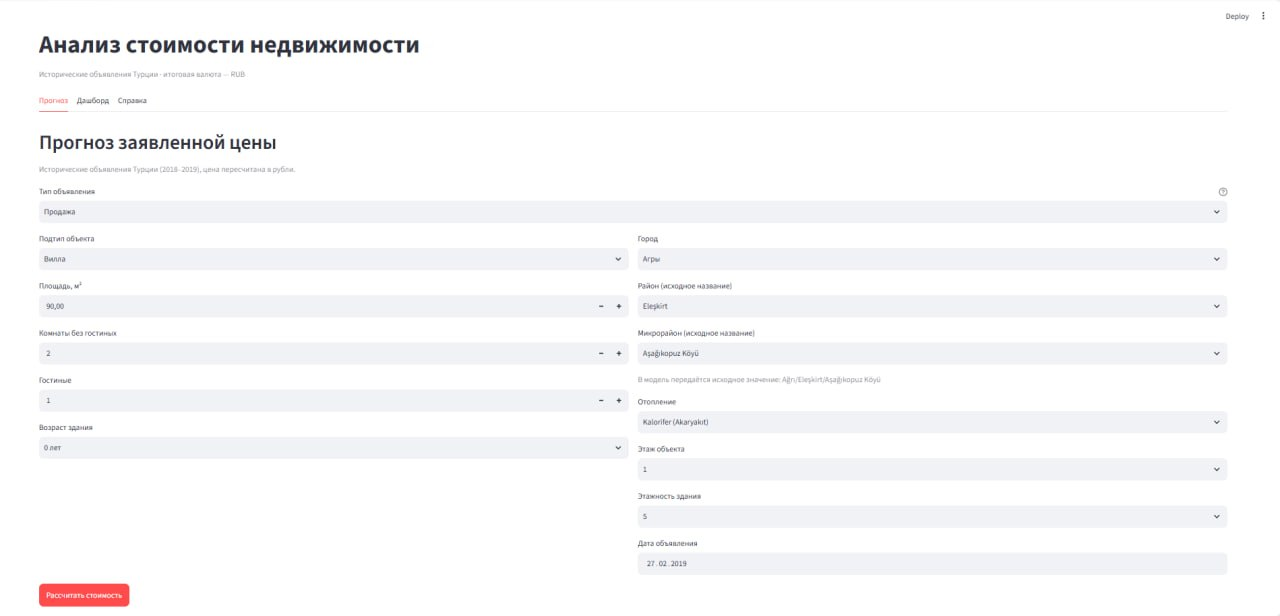

*Дашборд*

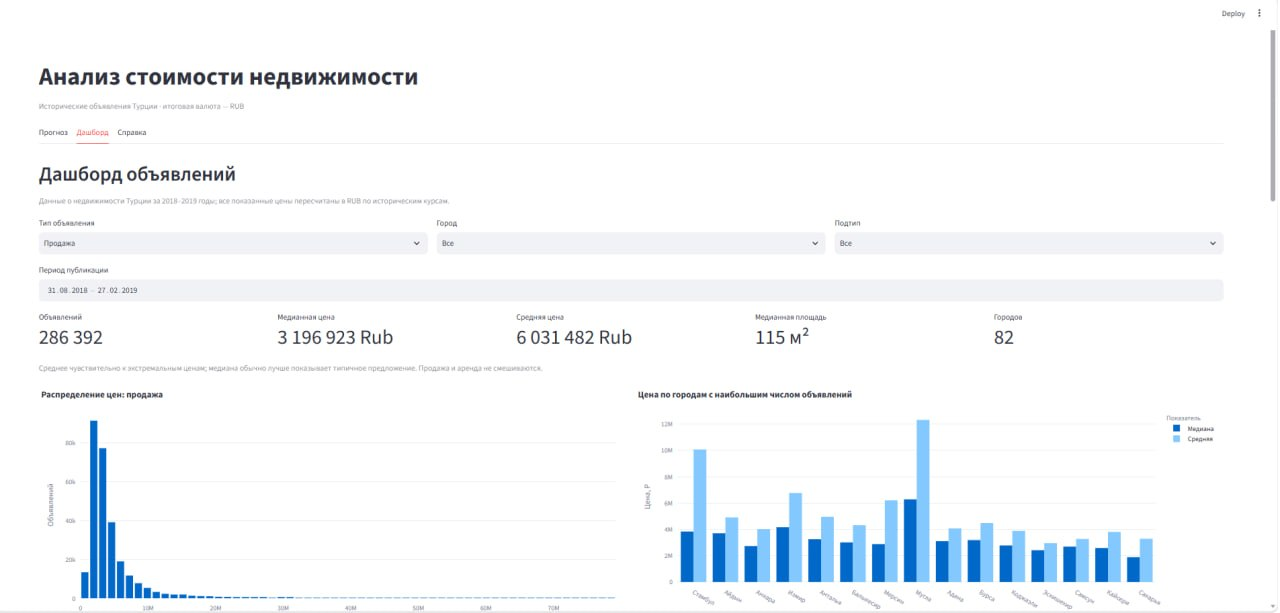
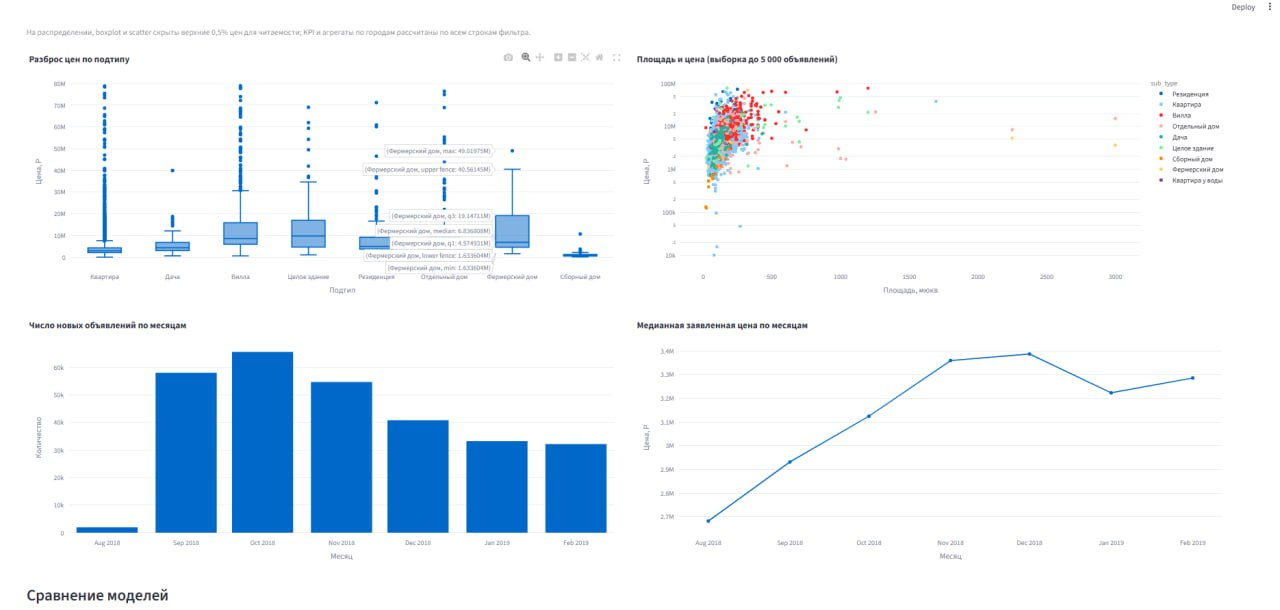
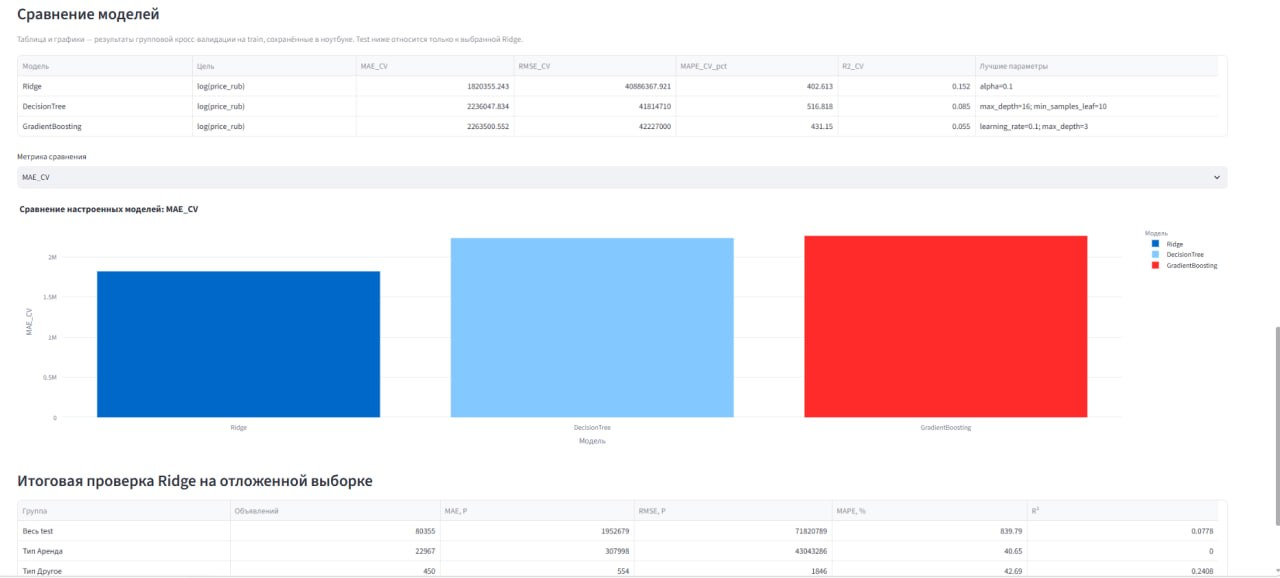

*Справка*

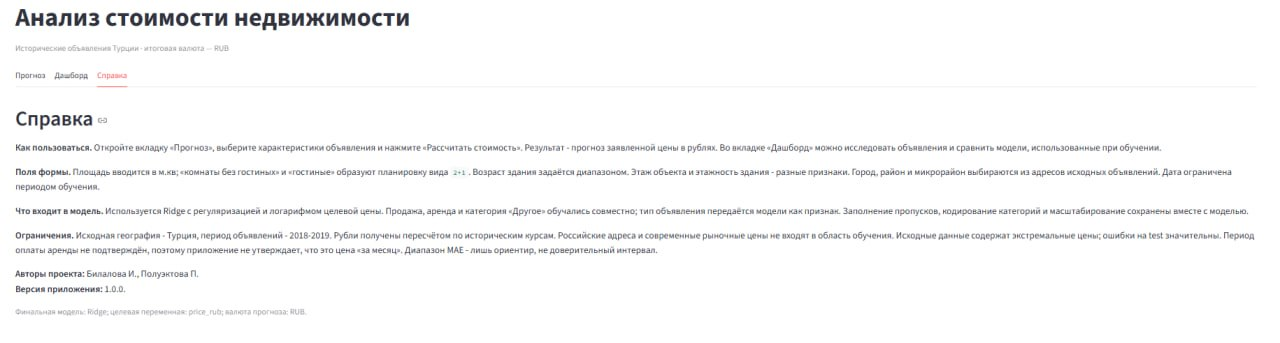